# MSc Dissertation Analysis Notebook
# Fizza Raza - 6509217 - MSC Data Science

## Neighbourhood green space at age 3 and cognitive development at age 5

### Research question
**Is neighbourhood green-space exposure at age 3 associated with verbal and non-verbal cognitive development at age 5, after accounting for socioeconomic background and the Home Learning Environment?**

### Outcomes
- **Naming Vocabulary T-score** — verbal/language cognition
- **Pattern Construction T-score** — non-verbal/spatial cognition

### Main exposure
- **`BGREENSP`** — age-3 LSOA-level green-space decile (primary analysis)

### Sensitivity exposure
- **`BGRND`** — age-3 ward-level green-space decile

### Main controls
- Child sex
- Household income quintile
- Highest parental education
- Home Learning Environment (HLE)

---

## How to use this notebook

This notebook intentionally keeps the full workflow in one place so the analysis can be followed from raw MCS files to final results. Each major section contains:

- **Goal** — what the step is trying to achieve
- **Why** — why it is needed
- **Result/meaning** — what the output tells us

Note : If the project grows much larger, a future tidy version could be split into **(1) data preparation** and **(2) statistical analysis/results**, with a saved clean master dataset between them. 

---

# Step 1 — Locate the MCS files and dissertation variables

**Goal:** Confirm that the required Sweep 2, Sweep 3 and linked green-space `.sav` files are available and identify which file contains each dissertation variable.

**Why:** MCS is distributed across many files. Before cleaning or modelling, we need a reproducible map of variable → source file.


In [1]:
from pathlib import Path
import pandas as pd
import pyreadstat

# The MCS_DATA folder should be in the same folder as this notebook.
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "MCS_DATA"

print("Project directory:", BASE_DIR)
print("Data directory:", DATA_DIR)
print("MCS_DATA exists:", DATA_DIR.exists())

Project directory: /Users/fizza/Documents/university/Dissertation/notebooks
Data directory: /Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA
MCS_DATA exists: True


## Step 1A — Find all SPSS `.sav` files

This recursively searches the dissertation data directory and lists all SPSS datasets. It is a file-discovery step only; no statistical analysis happens here.


In [2]:
sav_files = list(DATA_DIR.rglob("*.sav"))

print(f"Number of .sav files found: {len(sav_files)}")

for file in sav_files:
    print(file)

Number of .sav files found: 34
/Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA/SWEEP3/spss/spss28/mcs3_cm_interview.sav
/Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA/SWEEP3/spss/spss28/mcs3_hhgrid.sav
/Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA/SWEEP3/spss/spss28/mcs3_family_derived.sav
/Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA/SWEEP3/spss/spss28/mcs3_cm_teacher_survey.sav
/Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA/SWEEP3/spss/spss28/mcs3_older_siblings_questionnaire.sav
/Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA/SWEEP3/spss/spss28/mcs3_parent_derived.sav
/Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA/SWEEP3/spss/spss28/mcs3_parent_cm_interview.sav
/Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA/SWEEP3/spss/spss28/mcs3_cm_derived.sav
/Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA/SWEEP3/spss/spss28/mcs3

## Step 1B — Define the variables we want to locate

This list contains the IDs, candidate exposures, HLE items, controls and cognitive outcomes identified during dissertation feasibility work.

**Why:** Searching metadata is safer and faster than manually opening dozens of SPSS files.


In [3]:
# Variables we want to locate across all MCS .sav files

variables_to_find = [
    # Linking / IDs
    "MCSID",
    "BCNUM00",
    "CCNUM00",

    # Physical environment
    "BPGDAC00",
    "BGREENSP",
    "BDOMGARD",
    "BGRND",

    # Home Learning Environment
    "BPOFRE00",
    "BPOFAB00",
    "BPOFSO00",
    "BPPAMA00",
    "BPOFLI00",

    # Socioeconomic / demographic controls
    "BOECDUK0",
    "BDHINC00",
    "BDACAQ00",
    "BHCSEX00",
    "BDC06E00",

    # Age 5 cognitive outcomes
    "CCNVTSCORE",
    "CCPCTSCORE"
]

## Step 1C — Search file metadata for the variables

Only SPSS metadata are read. The code records which file contains each requested variable.

**Output:** A variable-to-file lookup table used throughout the rest of the notebook.


In [4]:
results = []

for file in sav_files:
    try:
        # Read metadata only — much faster than loading full datasets
        _, meta = pyreadstat.read_sav(file, metadataonly=True)

        available_vars = set(meta.column_names)

        for variable in variables_to_find:
            if variable in available_vars:
                results.append({
                    "Variable": variable,
                    "File": file.name,
                    "Full Path": str(file)
                })

    except Exception as e:
        print(f"Could not read {file.name}: {e}")

### Review the variable-to-file map

The table below confirms where each requested variable lives. This is the practical extraction plan for the dissertation.


In [5]:
results_df = pd.DataFrame(results)

results_df.sort_values(["Variable", "File"])

,Variable,File,Full Path
44,BCNUM00,mcs2_cm_cognitive_assessment.sav,/Users/fizza/Documents/university/Dissertation...
46,BCNUM00,mcs2_cm_derived.sav,/Users/fizza/Documents/university/Dissertation...
23,BCNUM00,mcs2_cm_interview.sav,/Users/fizza/Documents/university/Dissertation...
21,BCNUM00,mcs2_cm_oral_fluid.sav,/Users/fizza/Documents/university/Dissertation...
35,BCNUM00,mcs2_hhgrid.sav,/Users/fizza/Documents/university/Dissertation...
27,BCNUM00,mcs2_parent_cm_interview.sav,/Users/fizza/Documents/university/Dissertation...
25,BDACAQ00,mcs2_parent_derived.sav,/Users/fizza/Documents/university/Dissertation...
47,BDC06E00,mcs2_cm_derived.sav,/Users/fizza/Documents/university/Dissertation...
40,BDHINC00,mcs2_family_derived.sav,/Users/fizza/Documents/university/Dissertation...
52,BDOMGARD,green_space_ward_deciles_mcs2.sav,/Users/fizza/Documents/university/Dissertation...


### Check that nothing required is missing

An empty `Variables not found` list means every variable in the search list was located in the downloaded MCS files.


In [6]:
found_variables = set(results_df["Variable"])

missing_variables = [
    var for var in variables_to_find
    if var not in found_variables
]

print("Variables not found:")
print(missing_variables)

Variables not found:
[]


**Result interpretation:** All requested dissertation variables were found in the downloaded files. This confirms the proposed project is technically feasible using the available MCS data.


## Step 1C.1 — Define the source files needed for the main analysis

Rather than repeatedly loading all 31 SPSS files, this creates a smaller list of files containing the dissertation variables.


In [7]:
# Files needed for the main dissertation analysis

files_needed = [
    "mcs2_parent_cm_interview.sav",
    "mcs2_parent_interview.sav",
    "mcs2_family_derived.sav",
    "mcs2_parent_derived.sav",
    "mcs2_hhgrid.sav",
    "mcs2_cm_derived.sav",
    "green_space_ward_deciles_mcs2.sav",
    "mcs3_cm_cognitive_assessment.sav"
]

### Confirm the selected files

This checks that the expected source datasets were found at their paths.


In [8]:
selected_files = [
    file for file in sav_files
    if file.name in files_needed
]

print(f"Files selected: {len(selected_files)}")

for file in selected_files:
    print(file.name)

Files selected: 8
mcs3_cm_cognitive_assessment.sav
mcs2_parent_derived.sav
mcs2_parent_cm_interview.sav
mcs2_hhgrid.sav
mcs2_family_derived.sav
mcs2_parent_interview.sav
mcs2_cm_derived.sav
green_space_ward_deciles_mcs2.sav


### Audit identifiers and file structure

**Goal:** Inspect row counts and identifier availability in the selected files.

**Why:** MCS files exist at different levels (family, person, parent-child, cohort child). Understanding that structure prevents incorrect merges.


In [9]:
audit_results = []

for file in selected_files:
    try:
        df, meta = pyreadstat.read_sav(file)

        # Find identifier-type variables
        id_vars = [
            col for col in df.columns
            if (
                "MCSID" in col.upper()
                or "CNUM" in col.upper()
                or "PNUM" in col.upper()
            )
        ]

        audit_results.append({
            "File": file.name,
            "Rows": len(df),
            "Columns": len(df.columns),
            "ID variables": ", ".join(id_vars)
        })

    except Exception as e:
        print(f"Problem reading {file.name}: {e}")

audit_df = pd.DataFrame(audit_results)

audit_df

,File,Rows,Columns,ID variables
0,mcs3_cm_cognitive_assessment.sav,15424,341,"MCSID, CCNUM00"
1,mcs2_parent_derived.sav,28413,36,"MCSID, BPNUM00"
2,mcs2_parent_cm_interview.sav,26229,455,"MCSID, BPNUM00, BCNUM00, BPNUMB00, BPNUMSA0, B..."
3,mcs2_hhgrid.sav,69172,40,"MCSID, BPNUM00, BCNUM00"
4,mcs2_family_derived.sav,15570,58,MCSID
5,mcs2_parent_interview.sav,25896,960,"MCSID, BPNUM00, BPNUMH00"
6,mcs2_cm_derived.sav,15771,29,"MCSID, BCNUM00"
7,green_space_ward_deciles_mcs2.sav,15583,5,MCSID


### Define exact variables to inspect in each source file

This sets up a focused structural check of the variables that will actually be used.


In [10]:
# Check structure of the exact variables we need

check_files = {
    "mcs2_parent_cm_interview.sav":
        ["MCSID", "BPNUM00", "BCNUM00",
         "BPOFRE00", "BPOFAB00", "BPOFSO00", "BPPAMA00", "BPOFLI00"],

    "mcs2_parent_interview.sav":
        ["MCSID", "BPNUM00", "BPGDAC00"],

    "mcs2_family_derived.sav":
        ["MCSID", "BOECDUK0", "BDHINC00"],

    "mcs2_parent_derived.sav":
        ["MCSID", "BPNUM00", "BDACAQ00"],

    "mcs2_hhgrid.sav":
        ["MCSID", "BPNUM00", "BCNUM00", "BHCSEX00"],

    "mcs2_cm_derived.sav":
        ["MCSID", "BCNUM00", "BDC06E00"],

    "green_space_ward_deciles_mcs2.sav":
        ["MCSID", "BGREENSP", "BDOMGARD", "BGRND"],

    "mcs3_cm_cognitive_assessment.sav":
        ["MCSID", "CCNUM00", "CCNVTSCORE", "CCPCTSCORE"]
}

### Inspect variable distributions and identifiers

This early audit helps reveal duplicated family IDs, cohort-member numbers and special/missing codes before any cleaning decisions are made.


In [11]:
for filename, variables in check_files.items():

    file_path = next(
        file for file in selected_files
        if file.name == filename
    )

    df, meta = pyreadstat.read_sav(file_path)

    existing = [v for v in variables if v in df.columns]

    print("\n" + "=" * 70)
    print(filename)
    print("=" * 70)

    print("Rows:", len(df))
    print("Variables:", existing)

    print("\nFirst 5 rows:")
    display(df[existing].head())


mcs2_parent_cm_interview.sav
Rows: 26229
Variables: ['MCSID', 'BPNUM00', 'BCNUM00', 'BPOFRE00', 'BPOFAB00', 'BPOFSO00', 'BPPAMA00', 'BPOFLI00']

First 5 rows:


,MCSID,BPNUM00,BCNUM00,BPOFRE00,BPOFAB00,BPOFSO00,BPPAMA00,BPOFLI00
0,M10001N,1.0,1.0,2.0,2.0,7.0,7.0,NaN
1,M10001N,2.0,1.0,2.0,NaN,NaN,NaN,NaN
2,M10002P,1.0,1.0,1.0,NaN,5.0,7.0,1.0
3,M10002P,2.0,1.0,1.0,NaN,NaN,NaN,NaN
4,M10007U,1.0,1.0,1.0,7.0,7.0,5.0,NaN



mcs2_parent_interview.sav
Rows: 25896
Variables: ['MCSID', 'BPNUM00', 'BPGDAC00']

First 5 rows:


,MCSID,BPNUM00,BPGDAC00
0,M10001N,1.0,NaN
1,M10001N,2.0,NaN
2,M10002P,1.0,NaN
3,M10002P,2.0,NaN
4,M10007U,1.0,NaN



mcs2_family_derived.sav
Rows: 15570
Variables: ['MCSID', 'BOECDUK0', 'BDHINC00']

First 5 rows:


...

,MCSID,BCNUM00,BDC06E00
0,M10001N,1.0,1.0
1,M10002P,1.0,1.0
2,M10007U,1.0,1.0
3,M10008V,1.0,1.0
4,M10008V,2.0,1.0



green_space_ward_deciles_mcs2.sav
Rows: 15583
Variables: ['MCSID', 'BGREENSP', 'BDOMGARD', 'BGRND']

First 5 rows:


,MCSID,BGREENSP,BDOMGARD,BGRND
0,M10001N,NaN,NaN,6.0
1,M10002P,NaN,NaN,6.0
2,M10007U,NaN,NaN,6.0
3,M10008V,3.0,7.0,4.0
4,M10011Q,8.0,5.0,7.0



mcs3_cm_cognitive_assessment.sav
Rows: 15424
Variables: ['MCSID', 'CCNUM00', 'CCNVTSCORE', 'CCPCTSCORE']

First 5 rows:


,MCSID,CCNUM00,CCNVTSCORE,CCPCTSCORE
0,M10001N,1.0,34.0,46.0
1,M10002P,1.0,51.0,58.0
2,M10007U,1.0,67.0,57.0
3,M10011Q,1.0,60.0,59.0
4,M10015U,1.0,71.0,40.0


### Inspect labels and missing values

This code extracts SPSS labels and observed values so that recoding decisions are based on the documentation embedded in the files rather than assumptions.


In [12]:
# ============================================================
# STEP 1C: Inspect variable labels, value labels and missingness
# ============================================================

for filename, variables in check_files.items():

    file_path = next(
        file for file in selected_files
        if file.name == filename
    )

    df, meta = pyreadstat.read_sav(file_path)

    print("\n" + "=" * 80)
    print(filename)
    print("=" * 80)

    for var in variables:

        if var not in df.columns:
            continue

        # Variable description
        try:
            label = meta.column_names_to_labels.get(var)
        except:
            label = None

        print(f"\nVARIABLE: {var}")
        print(f"LABEL: {label}")

        # Missingness
        n_valid = df[var].notna().sum()
        n_missing = df[var].isna().sum()
        pct_missing = df[var].isna().mean() * 100

        print(f"Valid: {n_valid:,}")
        print(f"Missing: {n_missing:,} ({pct_missing:.1f}%)")

        # Most common values
        print("Values:")
        print(df[var].value_counts(dropna=False).head(15))


mcs2_parent_cm_interview.sav

VARIABLE: MCSID
LABEL: MCS Research ID - Anonymised Family/Household Identifier
Valid: 26,229
Missing: 0 (0.0%)
Values:
MCSID
M10008V    4
M10225C    4
M10362L    4
M10415G    4
M10476V    4
M10611J    4
M10852Z    4
M11163K    4
M11273Q    4
M11297Y    4
M11554W    4
M11689L    4
M12096V    4
M12134J    4
M12197Z    4
Name: count, dtype: int64

VARIABLE: BPNUM00
LABEL: Person number within an MCS family (excl Cohort Members, see CNUM)
Valid: 26,229
Missing: 0 (0.0%)
Values:
BPNUM00
1.0    15456
2.0     9956
3.0      398
4.0      227
5.0      116
6.0       45
7.0       16
8.0        8
9.0        7
Name: count, dtype: int64

VARIABLE: BCNUM00
LABEL: Cohort Member number within an MCS family
Valid: 26,229
Missing: 0 (0.0%)
Values:
BCNUM00
1.0    25896
2.0      333
Name: count, dtype: int64

VARIABLE: BPOFRE00
LABEL: How often do you read to the child
Valid: 26,210
Missing: 19 (0.1%)
Values:
BPOFRE00
1.0    11217
3.0     5848
2.0     5602
4.0     1431
6.0   

# Step 1D — Understand the SPSS coding

**Goal:** Find out what the numeric values in each MCS variable actually mean.

**Why this matters:** SPSS variables often use numbers such as `1`, `2`, `3`, but the direction is not always intuitive. For example, one HLE item may use `1 = every day` while another uses `7 = every day`. We must understand the labels before recoding or combining variables.

**What this step checks:** HLE activities, garden access, income, parental education, child sex, green-space measures, and the two age-5 cognitive outcomes.


In [13]:
import pyreadstat
from pathlib import Path

BASE = DATA_DIR
# Files and variables whose coding we need to understand
check_files = {
    
    "HLE variables": (
        BASE / "SWEEP2/spss/spss28/mcs2_parent_cm_interview.sav",
        ["BPOFRE00", "BPOFAB00", "BPOFSO00", "BPPAMA00", "BPOFLI00"]
    ),
    
    "Garden access": (
        BASE / "SWEEP2/spss/spss28/mcs2_parent_interview.sav",
        ["BPGDAC00"]
    ),
    
    "SES - income": (
        BASE / "SWEEP2/spss/spss28/mcs2_family_derived.sav",
        ["BOECDUK0", "BDHINC00"]
    ),
    
    "Parental education": (
        BASE / "SWEEP2/spss/spss28/mcs2_parent_derived.sav",
        ["BDACAQ00"]
    ),
    
    "Child sex": (
        BASE / "SWEEP2/spss/spss28/mcs2_hhgrid.sav",
        ["BHCSEX00"]
    ),
    
    "Green space": (
        BASE / "GreenSpace_Linked/spss/spss28/green_space_ward_deciles_mcs2.sav",
        ["BGREENSP", "BDOMGARD", "BGRND"]
    ),
    
    "Age 5 cognitive outcomes": (
        BASE / "SWEEP3/spss/spss28/mcs3_cm_cognitive_assessment.sav",
        ["CCNVTSCORE", "CCPCTSCORE"]
    )
}


for section, (file_path, variables) in check_files.items():
    
    print("\n" + "=" * 80)
    print(section)
    print(file_path.name)
    print("=" * 80)
    
    df, meta = pyreadstat.read_sav(
        file_path,
        metadataonly=True
    )
    
    for var in variables:
        
        print(f"\nVARIABLE: {var}")
        
        # Variable description
        label = meta.column_names_to_labels.get(var, "No label")
        print("VARIABLE LABEL:", label)
        
        # Find which SPSS value-label set belongs to this variable
        label_set = meta.variable_to_label.get(var)
        
        if label_set and label_set in meta.value_labels:
            print("VALUE LABELS:")
            
            for value, meaning in meta.value_labels[label_set].items():
                print(f"   {value} = {meaning}")
                
        else:
            print("VALUE LABELS: No labelled categories found")


HLE variables
mcs2_parent_cm_interview.sav

VARIABLE: BPOFRE00
VARIABLE LABEL: How often do you read to the child
VALUE LABELS:
   -1.0 = Not Applicable
   1.0 = Every day
   2.0 = Several times a week
   3.0 = Once or twice a week
   4.0 = Once or twice a month
   5.0 = Less often
   6.0 = Not at all

VARIABLE: BPOFAB00
VARIABLE LABEL: How often help child learn alphabet
VALUE LABELS:
   -9.0 = Missing value -9
   -2.0 = Not answered
   -1.0 = Not applicable
   1.0 = Occasionally or less than once a week
   2.0 = 1-2 days per week
   3.0 = 3 times a week
   4.0 = 4 times a week
   5.0 = 5 times a week
   6.0 = 6 times a week
   7.0 = 7 times a week/constantly

VARIABLE: BPOFSO00
VARIABLE LABEL: How often teach child songs/poems/rhymes
VALUE LABELS:
   -1.0 = Not Applicable
   1.0 = Occasionally or less than once a week
   2.0 = 1 - 2 days per week
   3.0 = 3 times a week
   4.0 = 4 times a week
   5.0 = 5 times a week
   6.0 = 6 times a week
   7.0 = 7 times a week constantly

VARIAB

**Result interpretation:** The HLE items do not all use the same coding direction, so recoding is essential. The age-5 cognitive variables are continuous T-scores rather than categories. Green-space variables are deciles and require documentation-based interpretation.


# Step 2 — Identify the correct child and respondent records

MCS files are not always one row per child. Some contain multiple parents/respondents, and some families contain more than one cohort child (for example, twins).

**Goal:** Work out the correct identifiers before any merging.

- `MCSID` = family/household identifier.
- `BCNUM00` = cohort-child number at Sweep 2 (age 3).
- `BPNUM00` = parent/person respondent number.

**Why this matters:** Merging only on `MCSID` could accidentally duplicate children or pair the wrong records.


In [14]:
import pyreadstat
from pathlib import Path
import pandas as pd

BASE = DATA_DIR
# ---------------------------------------------------------
# 1. HLE file
# ---------------------------------------------------------

hle_path = BASE / "SWEEP2/spss/spss28/mcs2_parent_cm_interview.sav"

hle_vars = [
    "MCSID",
    "BPNUM00",
    "BCNUM00",
    "BPOFRE00",
    "BPOFAB00",
    "BPOFSO00",
    "BPPAMA00",
    "BPOFLI00"
]

hle, hle_meta = pyreadstat.read_sav(
    hle_path,
    usecols=hle_vars
)

print("=" * 70)
print("HLE FILE")
print("=" * 70)

print("\nTotal rows:", len(hle))
print("Unique families (MCSID):", hle["MCSID"].nunique())

print("\nParent/person numbers:")
print(hle["BPNUM00"].value_counts(dropna=False).sort_index())

print("\nCohort member numbers:")
print(hle["BCNUM00"].value_counts(dropna=False).sort_index())


# ---------------------------------------------------------
# 2. Age-5 cognitive outcome file
# ---------------------------------------------------------

cog_path = BASE / "SWEEP3/spss/spss28/mcs3_cm_cognitive_assessment.sav"

cog_vars = [
    "MCSID",
    "CCNUM00",
    "CCNVTSCORE",
    "CCPCTSCORE"
]

cog, cog_meta = pyreadstat.read_sav(
    cog_path,
    usecols=cog_vars
)

print("\n" + "=" * 70)
print("AGE-5 COGNITIVE FILE")
print("=" * 70)

print("\nTotal rows:", len(cog))
print("Unique families (MCSID):", cog["MCSID"].nunique())

print("\nCohort member numbers:")
print(cog["CCNUM00"].value_counts(dropna=False).sort_index())


# ---------------------------------------------------------
# 3. Check whether family IDs repeat
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("REPEATED MCSID CHECK")
print("=" * 70)

hle_counts = hle.groupby("MCSID").size()

print("\nHLE rows per family:")
print(hle_counts.value_counts().sort_index())

cog_counts = cog.groupby("MCSID").size()

print("\nCognitive rows per family:")
print(cog_counts.value_counts().sort_index())


# ---------------------------------------------------------
# 4. Show examples of families with multiple HLE records
# ---------------------------------------------------------

multiple_hle = hle_counts[hle_counts > 1].index[:5]

print("\n" + "=" * 70)
print("EXAMPLE FAMILIES WITH MULTIPLE HLE RECORDS")
print("=" * 70)

display(
    hle[hle["MCSID"].isin(multiple_hle)]
    .sort_values(["MCSID", "BCNUM00", "BPNUM00"])
)

HLE FILE

Total rows: 26229
Unique families (MCSID): 15491

Parent/person numbers:
BPNUM00
1.0    15456
2.0     9956
3.0      398
4.0      227
5.0      116
6.0       45
7.0       16
8.0        8
9.0        7
Name: count, dtype: int64

Cohort member numbers:
BCNUM00
1.0    25896
2.0      333
Name: count, dtype: int64

AGE-5 COGNITIVE FILE

Total rows: 15424
Unique families (MCSID): 15230

Cohort member numbers:
CCNUM00
1.0    15230
2.0      194
Name: count, dtype: int64

REPEATED MCSID CHECK

HLE rows per family:
1     5027
2    10327
4      137
Name: count, dtype: int64

Cognitive rows per family:
1    15036
2      194
Name: count, dtype: int64

EXAMPLE FAMILIES WITH MULTIPLE HLE RECORDS


,MCSID,BPNUM00,BCNUM00,BPOFRE00,BPOFLI00,BPOFAB00,BPOFSO00,BPPAMA00
0,M10001N,1.0,1.0,2.0,NaN,2.0,7.0,7.0
1,M10001N,2.0,1.0,2.0,NaN,NaN,NaN,NaN
2,M10002P,1.0,1.0,1.0,1.0,NaN,5.0,7.0
3,M10002P,2.0,1.0,1.0,NaN,NaN,NaN,NaN
4,M10007U,1.0,1.0,1.0,NaN,7.0,7.0,5.0
5,M10007U,2.0,1.0,1.0,NaN,NaN,NaN,NaN
7,M10008V,1.0,1.0,1.0,NaN,2.0,2.0,7.0
9,M10008V,2.0,1.0,1.0,NaN,NaN,NaN,NaN
6,M10008V,1.0,2.0,1.0,NaN,NaN,7.0,2.0
8,M10008V,2.0,2.0,1.0,NaN,NaN,NaN,NaN


## Step 2B — Which respondent provides the HLE information?

**Goal:** Compare the completeness of Home Learning Environment responses across parent/respondent records.

**Why:** We do not want to automatically assume respondent 1 is always the best record. We keep the respondent with the most complete HLE information for each child.


In [15]:
# ============================================================
# STEP 2B — Check HLE completeness by parent/respondent number
# ============================================================

hle_items = [
    "BPOFRE00",
    "BPOFAB00",
    "BPOFSO00",
    "BPPAMA00",
    "BPOFLI00"
]

# Count how many HLE questions are answered on each row
hle["HLE_answered_count"] = hle[hle_items].notna().sum(axis=1)

print("=" * 70)
print("HLE COMPLETENESS BY PARENT/PERSON NUMBER")
print("=" * 70)

summary = (
    hle.groupby("BPNUM00")
       .agg(
           rows=("MCSID", "size"),
           mean_HLE_items_answered=("HLE_answered_count", "mean"),
           rows_with_any_HLE=("HLE_answered_count", lambda x: (x > 0).sum()),
           rows_with_all_5_HLE=("HLE_answered_count", lambda x: (x == 5).sum())
       )
)

summary["percent_with_any_HLE"] = (
    summary["rows_with_any_HLE"] / summary["rows"] * 100
)

display(summary.round(2))


# ------------------------------------------------------------
# Check each HLE variable separately by parent number
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NON-MISSING RESPONSES FOR EACH HLE VARIABLE")
print("=" * 70)

for var in hle_items:
    print(f"\n{var}")
    print(
        hle.groupby("BPNUM00")[var]
           .apply(lambda x: x.notna().sum())
    )


# ------------------------------------------------------------
# Compare parent 1 vs parent 2 when both exist for same child
# ------------------------------------------------------------

parent12 = hle[hle["BPNUM00"].isin([1, 2])].copy()

comparison = parent12.pivot_table(
    index=["MCSID", "BCNUM00"],
    columns="BPNUM00",
    values="HLE_answered_count",
    aggfunc="first"
)

comparison.columns = [
    f"parent_{int(c)}_answered"
    for c in comparison.columns
]

print("\n" + "=" * 70)
print("PARENT 1 vs PARENT 2 HLE COMPLETENESS")
print("=" * 70)

display(comparison.head(20))

if {"parent_1_answered", "parent_2_answered"}.issubset(comparison.columns):

    both = comparison.dropna(
        subset=["parent_1_answered", "parent_2_answered"]
    )

    print("\nChildren with both parent 1 and parent 2 records:", len(both))

    print(
        "\nParent 1 has more HLE information:",
        (both["parent_1_answered"] > both["parent_2_answered"]).sum()
    )

    print(
        "Parent 2 has more HLE information:",
        (both["parent_2_answered"] > both["parent_1_answered"]).sum()
    )

    print(
        "Same amount of HLE information:",
        (both["parent_1_answered"] == both["parent_2_answered"]).sum()
    )

HLE COMPLETENESS BY PARENT/PERSON NUMBER


,rows,mean_HLE_items_answered,rows_with_any_HLE,rows_with_all_5_HLE,percent_with_any_HLE
BPNUM00,,,,,
1.0,15456,4.04,15445,4731,99.93
2.0,9956,1.20,9949,193,99.93
3.0,398,1.12,398,3,100.00
4.0,227,1.08,227,1,100.00
5.0,116,1.03,116,0,100.00
6.0,45,1.11,44,0,97.78
7.0,16,1.00,16,0,100.00
8.0,8,1.50,8,1,100.00
9.0,7,1.43,7,0,100.00



NON-MISSING RESPONSES FOR EACH HLE VARIABLE

BPOFRE00
BPNUM00
1.0    15445
2.0     9949
3.0      398
4.0      227
5.0      116
6.0       44
7.0       16
8.0        8
9.0        7
Name: BPOFRE00, dtype: int64

BPOFAB00
BPNUM00
1.0    12073
2.0      516
3.0       13
4.0        6
5.0        1
6.0        2
7.0        0
8.0        1
9.0        1
Name: BPOFAB00, dtype: int64

BPOFSO00
BPNUM00
1.0    14233
2.0      589
3.0       15
4.0        6
5.0        1
6.0        2
7.0        0
8.0        1
9.0        1
Name: BPOFSO00, dtype: int64

BPPAMA00
BPNUM00
1.0    14655
2.0      611
3.0       16
4.0        6
5.0        1
6.0        2
7.0        0
8.0        1
9.0        1
Name: BPPAMA00, dtype: int64

BPOFLI00
BPNUM00
1.0    6002
2.0     238
3.0       4
4.0       1
5.0       0
6.0       0
7.0       0
8.0       1
9.0       0
Name: BPOFLI00, dtype: int64

PARENT 1 vs PARENT 2 HLE COMPLETENESS


parent_1_answered  parent_2_answered
MCSID   BCNUM00                                      
M10001N 1.0                    4.0                1.0
M10002P 1.0                    4.0                1.0
M10007U 1.0                    4.0                1.0
M10008V 1.0                    4.0                1.0
        2.0                    3.0                1.0
M10011Q 1.0                    4.0                NaN
M10014T 1.0                    3.0                1.0
M10015U 1.0                    4.0                1.0
M10016V 1.0                    4.0                1.0
M10017W 1.0                    NaN                3.0
M10018X 1.0                    5.0                1.0
M10020R 1.0                    4.0                1.0
M10021S 1.0                    5.0                NaN
M10022T 1.0                    5.0                1.0
M10024V 1.0                    5.0                1.0
M10025W 1.0                    4.0                NaN
M10027Y 1.0                    3.0                NaN
M10029A 1.0                    2.0                NaN
M10034X 1.0                    4.0                1.0
M10035Y 1.0                    4.0                NaN


Children with both parent 1 and parent 2 records: 9749

Parent 1 has more HLE information: 9251
Parent 2 has more HLE information: 472
Same amount of HLE information: 26


**Result interpretation:** Respondent 1 usually contains more complete HLE information, but respondent 2 is more complete for a non-trivial minority of children. Selecting the most complete respondent is therefore preferable to automatically keeping respondent 1.


## Step 2C — Create one HLE record per child

**Goal:** Reduce the parent-child interview file to **one record per cohort child**.

**Rule:** For each `MCSID + BCNUM00`, retain the respondent with the greatest number of answered HLE items. If tied, use the lower respondent number as a consistent tie-breaker.

**Expected result:** Zero duplicate child IDs.


In [16]:
# ============================================================
# STEP 2C — Create ONE HLE record per child
# Keep the respondent with the most complete HLE information
# ============================================================

hle_items = [
    "BPOFRE00",
    "BPOFAB00",
    "BPOFSO00",
    "BPPAMA00",
    "BPOFLI00"
]

# Work on a copy
hle_child = hle.copy()

# Count HLE items answered
hle_child["HLE_answered_count"] = (
    hle_child[hle_items]
    .notna()
    .sum(axis=1)
)

# Sort so that:
# 1. Most complete HLE record comes first
# 2. If completeness is tied, lower BPNUM00 is preferred
hle_child = hle_child.sort_values(
    by=["MCSID", "BCNUM00", "HLE_answered_count", "BPNUM00"],
    ascending=[True, True, False, True]
)

# Keep only the best respondent record for each child
hle_child = (
    hle_child
    .drop_duplicates(
        subset=["MCSID", "BCNUM00"],
        keep="first"
    )
    .copy()
)

print("=" * 70)
print("ONE HLE RECORD PER CHILD")
print("=" * 70)

print("Rows:", len(hle_child))

print(
    "Unique MCSID + BCNUM00:",
    hle_child[["MCSID", "BCNUM00"]]
    .drop_duplicates()
    .shape[0]
)

print("\nSelected respondent numbers:")
print(
    hle_child["BPNUM00"]
    .value_counts()
    .sort_index()
)

print("\nHLE completeness after selection:")
print(
    hle_child["HLE_answered_count"]
    .value_counts()
    .sort_index()
)

print("\nAny duplicated child IDs remaining?")
print(
    hle_child.duplicated(
        subset=["MCSID", "BCNUM00"]
    ).sum()
)

display(
    hle_child[
        [
            "MCSID",
            "BCNUM00",
            "BPNUM00",
            "HLE_answered_count",
            "BPOFRE00",
            "BPOFAB00",
            "BPOFSO00",
            "BPPAMA00",
            "BPOFLI00"
        ]
    ].head(10)
)

ONE HLE RECORD PER CHILD
Rows: 15687
Unique MCSID + BCNUM00: 15687

Selected respondent numbers:
BPNUM00
1.0    14977
2.0      677
3.0       19
4.0        8
5.0        1
6.0        2
7.0        1
8.0        1
9.0        1
Name: count, dtype: int64

HLE completeness after selection:
HLE_answered_count
0      10
1     101
2     261
3    2135
4    8251
5    4929
Name: count, dtype: int64

Any duplicated child IDs remaining?
0


,MCSID,BCNUM00,BPNUM00,HLE_answered_count,BPOFRE00,BPOFAB00,BPOFSO00,BPPAMA00,BPOFLI00
0,M10001N,1.0,1.0,4,2.0,2.0,7.0,7.0,NaN
2,M10002P,1.0,1.0,4,1.0,NaN,5.0,7.0,1.0
4,M10007U,1.0,1.0,4,1.0,7.0,7.0,5.0,NaN
7,M10008V,1.0,1.0,4,1.0,2.0,2.0,7.0,NaN
6,M10008V,2.0,1.0,3,1.0,NaN,7.0,2.0,NaN
10,M10011Q,1.0,1.0,4,1.0,7.0,7.0,7.0,NaN
11,M10014T,1.0,1.0,3,1.0,NaN,7.0,2.0,NaN
13,M10015U,1.0,1.0,4,1.0,6.0,5.0,4.0,NaN
15,M10016V,1.0,1.0,4,3.0,3.0,2.0,3.0,NaN
17,M10017W,1.0,2.0,3,2.0,NaN,2.0,4.0,NaN


**Result interpretation:** One HLE record is now retained per child and duplicate child IDs are removed. This prevents parent/respondent duplication from inflating the analysis sample.


# Step 3 — Construct the Home Learning Environment (HLE) score

## Step 3A — Recode all HLE items in the same direction

**Goal:** Make all activity scores mean the same thing: **higher = more frequent/richer learning activity**.

The original MCS questions use different directions, so they cannot be averaged safely until recoded. Special negative values such as `-1`, `-2`, and `-9` are treated as missing rather than genuine scores.


In [17]:
# ============================================================
# STEP 3A — Recode HLE variables
# Higher score = MORE frequent learning activity
# ============================================================

import numpy as np

# Work on a copy
hle_scored = hle_child.copy()

# ------------------------------------------------------------
# First convert special negative codes to missing
# ------------------------------------------------------------

hle_items = [
    "BPOFRE00",
    "BPOFAB00",
    "BPOFSO00",
    "BPPAMA00",
    "BPOFLI00"
]

for var in hle_items:
    hle_scored.loc[hle_scored[var] < 0, var] = np.nan


# ------------------------------------------------------------
# 1. Reading
#
# Original:
# 1 = Every day
# 2 = Several times a week
# 3 = Once/twice a week
# 4 = Once/twice a month
# 5 = Less often
# 6 = Not at all
#
# Reverse so HIGHER = MORE frequent
# ------------------------------------------------------------

reading_map = {
    1: 5,
    2: 4,
    3: 3,
    4: 2,
    5: 1,
    6: 0
}

hle_scored["HLE_reading"] = (
    hle_scored["BPOFRE00"].map(reading_map)
)


# ------------------------------------------------------------
# 2. Alphabet
#
# Original 1–7 already runs:
# low frequency -> high frequency
#
# Convert to 0–6
# ------------------------------------------------------------

hle_scored["HLE_alphabet"] = (
    hle_scored["BPOFAB00"] - 1
)


# ------------------------------------------------------------
# 3. Songs / poems / rhymes
# Original 1–7 -> convert to 0–6
# ------------------------------------------------------------

hle_scored["HLE_songs"] = (
    hle_scored["BPOFSO00"] - 1
)


# ------------------------------------------------------------
# 4. Painting / drawing
# Original 1–7 -> convert to 0–6
# ------------------------------------------------------------

hle_scored["HLE_painting"] = (
    hle_scored["BPPAMA00"] - 1
)


# ------------------------------------------------------------
# 5. Library
#
# Original:
# 1 = special occasions
# 2 = monthly
# 3 = fortnightly
# 4 = weekly
#
# Convert to 0–3
# ------------------------------------------------------------

hle_scored["HLE_library"] = (
    hle_scored["BPOFLI00"] - 1
)


# ------------------------------------------------------------
# Check the new variables
# ------------------------------------------------------------

new_hle_items = [
    "HLE_reading",
    "HLE_alphabet",
    "HLE_songs",
    "HLE_painting",
    "HLE_library"
]

print("=" * 70)
print("RECODED HLE VARIABLES")
print("Higher score = more frequent learning activity")
print("=" * 70)

for var in new_hle_items:
    print(f"\n{var}")
    print(
        hle_scored[var]
        .value_counts(dropna=False)
        .sort_index()
    )


print("\n" + "=" * 70)
print("EXAMPLE RECODED CHILDREN")
print("=" * 70)

display(
    hle_scored[
        [
            "MCSID",
            "BCNUM00",
            "BPOFRE00",
            "HLE_reading",
            "BPOFAB00",
            "HLE_alphabet",
            "BPOFSO00",
            "HLE_songs",
            "BPPAMA00",
            "HLE_painting",
            "BPOFLI00",
            "HLE_library"
        ]
    ].head(15)
)

RECODED HLE VARIABLES
Higher score = more frequent learning activity

HLE_reading
HLE_reading
0.0     524
1.0     336
2.0     423
3.0    2484
4.0    2971
5.0    8939
NaN      10
Name: count, dtype: int64

HLE_alphabet
HLE_alphabet
0.0    1925
1.0    3387
2.0    1934
3.0    1157
4.0     778
5.0     369
6.0    3063
NaN    3074
Name: count, dtype: int64

HLE_songs
HLE_songs
0.0     608
1.0    1634
2.0    1414
3.0    1185
4.0    1082
5.0     660
6.0    8265
NaN     839
Name: count, dtype: int64

HLE_painting
HLE_painting
0.0     610
1.0    2226
2.0    1837
3.0    1564
4.0    1319
5.0     882
6.0    6855
NaN     394
Name: count, dtype: int64

HLE_library
HLE_library
0.0    1427
1.0    2564
2.0    1176
3.0    1079
NaN    9441
Name: count, dtype: int64

EXAMPLE RECODED CHILDREN


,MCSID,BCNUM00,BPOFRE00,HLE_reading,BPOFAB00,HLE_alphabet,BPOFSO00,HLE_songs,BPPAMA00,HLE_painting,BPOFLI00,HLE_library
0,M10001N,1.0,2.0,4.0,2.0,1.0,7.0,6.0,7.0,6.0,NaN,NaN
2,M10002P,1.0,1.0,5.0,NaN,NaN,5.0,4.0,7.0,6.0,1.0,0.0
4,M10007U,1.0,1.0,5.0,7.0,6.0,7.0,6.0,5.0,4.0,NaN,NaN
7,M10008V,1.0,1.0,5.0,2.0,1.0,2.0,1.0,7.0,6.0,NaN,NaN
6,M10008V,2.0,1.0,5.0,NaN,NaN,7.0,6.0,2.0,1.0,NaN,NaN
10,M10011Q,1.0,1.0,5.0,7.0,6.0,7.0,6.0,7.0,6.0,NaN,NaN
11,M10014T,1.0,1.0,5.0,NaN,NaN,7.0,6.0,2.0,1.0,NaN,NaN
13,M10015U,1.0,1.0,5.0,6.0,5.0,5.0,4.0,4.0,3.0,NaN,NaN
15,M10016V,1.0,3.0,3.0,3.0,2.0,2.0,1.0,3.0,2.0,NaN,NaN
17,M10017W,1.0,2.0,4.0,NaN,NaN,2.0,1.0,4.0,3.0,NaN,NaN


## Step 3B — Examine the HLE items before combining them

**Goal:** Check descriptive statistics, missingness and correlations among the candidate HLE activities.

**Why:** A composite score should be based on items that are reasonably available and conceptually related. This check showed that the library item had very high missingness and very weak relationships with the other home-learning activities.


In [18]:
# ============================================================
# STEP 3B — Examine HLE items before creating composite
# ============================================================

hle_vars = [
    "HLE_reading",
    "HLE_alphabet",
    "HLE_songs",
    "HLE_painting",
    "HLE_library"
]

print("=" * 70)
print("HLE DESCRIPTIVE STATISTICS")
print("=" * 70)

display(
    hle_scored[hle_vars]
    .describe()
    .T
    .round(2)
)


print("\n" + "=" * 70)
print("NUMBER AND % MISSING")
print("=" * 70)

missing_table = pd.DataFrame({
    "missing_n": hle_scored[hle_vars].isna().sum(),
    "missing_percent":
        hle_scored[hle_vars].isna().mean() * 100
})

display(missing_table.round(2))


print("\n" + "=" * 70)
print("CORRELATIONS BETWEEN HLE ITEMS")
print("=" * 70)

hle_correlations = hle_scored[hle_vars].corr()

display(hle_correlations.round(3))

HLE DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
HLE_reading,15677.0,4.16,1.24,0.0,4.0,5.0,5.0,5.0
HLE_alphabet,12613.0,2.70,2.21,0.0,1.0,2.0,5.0,6.0
HLE_songs,14848.0,4.39,2.05,0.0,3.0,6.0,6.0,6.0
HLE_painting,15293.0,4.02,2.09,0.0,2.0,5.0,6.0,6.0
HLE_library,6246.0,1.31,1.01,0.0,1.0,1.0,2.0,3.0



NUMBER AND % MISSING


,missing_n,missing_percent
HLE_reading,10,0.06
HLE_alphabet,3074,19.60
HLE_songs,839,5.35
HLE_painting,394,2.51
HLE_library,9441,60.18



CORRELATIONS BETWEEN HLE ITEMS


,HLE_reading,HLE_alphabet,HLE_songs,HLE_painting,HLE_library
HLE_reading,1.000,0.130,0.177,0.084,0.089
HLE_alphabet,0.130,1.000,0.298,0.178,0.048
HLE_songs,0.177,0.298,1.000,0.263,0.014
HLE_painting,0.084,0.178,0.263,1.000,0.018
HLE_library,0.089,0.048,0.014,0.018,1.000


**Result interpretation:** The four home-based HLE activities have reasonable coverage and modest positive relationships. The library item has very high missingness and contributes little to the shared pattern, supporting its exclusion from the primary HLE composite.


## Step 3C — Construct the HLE composite

The primary HLE score uses four activities:

1. Reading to the child
2. Helping the child learn the alphabet
3. Teaching songs, poems or rhymes
4. Painting/drawing at home

Each item is standardised (z-scored), then the available standardised items are averaged. A score is retained when **at least 3 of the 4 core items** are available.

**Interpretation:** Higher `HLE_score` = more frequent home-learning activities. A value around 0 is approximately average for the sample; negative values simply indicate below-average frequency, not a “negative” home environment.


In [19]:
# ============================================================
# STEP 3C — Construct Home Learning Environment (HLE) score
# ============================================================

hle_core = [
    "HLE_reading",
    "HLE_alphabet",
    "HLE_songs",
    "HLE_painting"
]

# Number of available HLE items for each child
hle_scored["HLE_items_available"] = (
    hle_scored[hle_core].notna().sum(axis=1)
)

# Standardise each HLE item (z-score)
hle_z_vars = []

for var in hle_core:
    z_var = var + "_z"

    hle_scored[z_var] = (
        hle_scored[var] - hle_scored[var].mean()
    ) / hle_scored[var].std()

    hle_z_vars.append(z_var)

# Mean of standardised items
# Require at least 3 of the 4 HLE activities
hle_scored["HLE_score"] = (
    hle_scored[hle_z_vars]
    .mean(axis=1, skipna=True)
    .where(hle_scored["HLE_items_available"] >= 3)
)


print("=" * 70)
print("FINAL HLE SCORE")
print("=" * 70)

print("\nNumber of HLE items available:")
print(
    hle_scored["HLE_items_available"]
    .value_counts()
    .sort_index()
)

print("\nHLE score descriptive statistics:")
print(
    hle_scored["HLE_score"]
    .describe()
    .round(3)
)

print("\nMissing HLE score:")
print(hle_scored["HLE_score"].isna().sum())

print("\nValid HLE score:")
print(hle_scored["HLE_score"].notna().sum())


display(
    hle_scored[
        [
            "MCSID",
            "BCNUM00",
            "HLE_reading",
            "HLE_alphabet",
            "HLE_songs",
            "HLE_painting",
            "HLE_items_available",
            "HLE_score"
        ]
    ].head(15)
)

FINAL HLE SCORE

Number of HLE items available:
HLE_items_available
0       10
1      105
2      314
3     3334
4    11924
Name: count, dtype: int64

HLE score descriptive statistics:
count    15258.000
mean         0.001
std          0.635
min         -2.470
25%         -0.428
50%          0.049
75%          0.484
max          1.040
Name: HLE_score, dtype: float64

Missing HLE score:
429

Valid HLE score:
15258


,MCSID,BCNUM00,HLE_reading,HLE_alphabet,HLE_songs,HLE_painting,HLE_items_available,HLE_score
0,M10001N,1.0,4.0,1.0,6.0,6.0,4,0.207740
2,M10002P,1.0,5.0,NaN,4.0,6.0,3,0.477968
4,M10007U,1.0,5.0,6.0,6.0,4.0,4,0.736487
7,M10008V,1.0,5.0,1.0,1.0,6.0,4,-0.199018
6,M10008V,2.0,5.0,NaN,6.0,1.0,3,0.006176
10,M10011Q,1.0,5.0,6.0,6.0,6.0,4,0.975351
11,M10014T,1.0,5.0,NaN,6.0,1.0,3,0.006176
13,M10015U,1.0,5.0,5.0,4.0,3.0,4,0.260523
15,M10016V,1.0,3.0,2.0,1.0,2.0,4,-0.966595
17,M10017W,1.0,4.0,NaN,1.0,3.0,3,-0.755102


**Result interpretation:** A usable HLE score is available for the large majority of children. Higher scores represent more frequent home-learning activity.


# Step 4 — Prepare the age-3 physical environment variables

This section investigates several possible measures of the child's outdoor/physical environment:

- `BGREENSP` — percentage green space at LSOA level, in deciles
- `BGRND` — ward-level green-space decile
- `BDOMGARD` — percentage domestic gardens at LSOA level, in deciles
- `BPGDAC00` — household access to a garden

**Purpose:** Decide which measure is most suitable as the primary exposure and which should be retained only for sensitivity/secondary analyses.


## Step 4A — Load the Sweep-2 linked green-space file

The linked file is household/geography-level and contains one row per `MCSID`. It does not contain a child number because children in the same household share the same neighbourhood exposure at that sweep.


In [20]:
import pyreadstat

green_path = (

    DATA_DIR

    / "GreenSpace_Linked"

    / "spss"

    / "spss28"

    / "green_space_ward_deciles_mcs2.sav"

)
green_space, green_meta = pyreadstat.read_sav(green_path)

print("GREEN SPACE MCS2 FILE LOADED")
print("=" * 60)

print("Rows:", len(green_space))
print("Columns:", len(green_space.columns))

print("\nRelevant variables:")
for var in ["MCSID", "BCNUM00", "BGREENSP", "BDOMGARD", "BGRND"]:
    print(f"{var:12s} →", var in green_space.columns)

GREEN SPACE MCS2 FILE LOADED
Rows: 15583
Columns: 5

Relevant variables:
MCSID        → True
BCNUM00      → False
BGREENSP     → True
BDOMGARD     → True
BGRND        → True


## Step 4B — Inspect green-space distributions and completeness

**Goal:** Check uniqueness, missingness and correlations among the linked environmental measures.

**Key finding:** `BGRND` has near-complete coverage, while the LSOA variables `BGREENSP` and `BDOMGARD` are missing for about 35% of records.


In [21]:
# ============================================================
# STEP 4A — Inspect green-space exposure variables
# ============================================================

print("=" * 70)
print("GREEN-SPACE FILE STRUCTURE")
print("=" * 70)

print("Rows:", len(green_space))
print("Unique MCSID:", green_space["MCSID"].nunique())

print(
    "Duplicated MCSID:",
    green_space.duplicated(subset=["MCSID"]).sum()
)


print("\n" + "=" * 70)
print("GREEN-SPACE DISTRIBUTIONS")
print("=" * 70)

for var in ["BGREENSP", "BDOMGARD", "BGRND"]:

    print(f"\n{var}")
    print("-" * 40)

    print(
        green_space[var]
        .value_counts(dropna=False)
        .sort_index()
    )

    missing_n = green_space[var].isna().sum()
    missing_pct = green_space[var].isna().mean() * 100

    print(
        f"\nMissing: {missing_n:,} "
        f"({missing_pct:.2f}%)"
    )


print("\n" + "=" * 70)
print("CORRELATIONS BETWEEN ENVIRONMENTAL MEASURES")
print("=" * 70)

display(
    green_space[
        ["BGREENSP", "BDOMGARD", "BGRND"]
    ]
    .corr()
    .round(3)
)

GREEN-SPACE FILE STRUCTURE
Rows: 15583
Unique MCSID: 15583
Duplicated MCSID: 0

GREEN-SPACE DISTRIBUTIONS

BGREENSP
----------------------------------------
BGREENSP
1.0     1182
2.0     1482
3.0     1032
4.0     1027
5.0      969
6.0      997
7.0      822
8.0     1033
9.0      717
10.0     820
NaN     5502
Name: count, dtype: int64

Missing: 5,502 (35.31%)

BDOMGARD
----------------------------------------
BDOMGARD
1.0     1012
2.0      695
3.0     1259
4.0      936
5.0     1099
6.0     1044
7.0      966
8.0     1039
9.0     1141
10.0     891
NaN     5501
Name: count, dtype: int64

Missing: 5,501 (35.30%)

BGRND
----------------------------------------
BGRND
1.0     2735
2.0     2107
3.0     1875
4.0     2070
5.0     1554
6.0     1584
7.0     1089
8.0     1008
9.0      896
10.0     664
NaN        1
Name: count, dtype: int64

Missing: 1 (0.01%)

CORRELATIONS BETWEEN ENVIRONMENTAL MEASURES


,BGREENSP,BDOMGARD,BGRND
BGREENSP,1.000,-0.749,0.721
BDOMGARD,-0.749,1.000,-0.491
BGRND,0.721,-0.491,1.000


**Result interpretation:** `BGRND` is almost complete, while `BGREENSP`/`BDOMGARD` are structurally unavailable for a substantial group. This difference later motivates using `BGREENSP` as the conceptually local primary measure and `BGRND` as a larger-sample sensitivity measure.


## Step 4C — Investigate the missingness pattern in `BGREENSP`

This checks whether `BGREENSP` and `BDOMGARD` are missing for the same households and whether `BGRND` remains available.

**Why:** The pattern helps distinguish structural data availability from scattered item non-response.


In [22]:
# ============================================================
# STEP 4B — Investigate BGREENSP missingness
# ============================================================

print("=" * 70)
print("GREEN-SPACE MISSINGNESS PATTERN")
print("=" * 70)

print("\nBGREENSP missing:")
print(green_space["BGREENSP"].isna().value_counts())

print("\nBGREENSP and BDOMGARD missing together:")
print(
    pd.crosstab(
        green_space["BGREENSP"].isna(),
        green_space["BDOMGARD"].isna(),
        rownames=["BGREENSP_missing"],
        colnames=["BDOMGARD_missing"]
    )
)

print("\nBGRND availability when BGREENSP is missing:")
print(
    green_space.loc[
        green_space["BGREENSP"].isna(),
        "BGRND"
    ].describe()
)

print("\nExample rows where BGREENSP is missing:")
display(
    green_space.loc[
        green_space["BGREENSP"].isna(),
        ["MCSID", "BGREENSP", "BDOMGARD", "BGRND"]
    ].head(10)
)

GREEN-SPACE MISSINGNESS PATTERN

BGREENSP missing:
BGREENSP
False    10081
True      5502
Name: count, dtype: int64

BGREENSP and BDOMGARD missing together:
BDOMGARD_missing  False  True 
BGREENSP_missing              
False             10081      0
True                  1   5501

BGRND availability when BGREENSP is missing:
count    5501.000000
mean        5.446101
std         2.764491
min         1.000000
25%         3.000000
50%         6.000000
75%         8.000000
max        10.000000
Name: BGRND, dtype: float64

Example rows where BGREENSP is missing:


,MCSID,BGREENSP,BDOMGARD,BGRND
0,M10001N,NaN,NaN,6.0
1,M10002P,NaN,NaN,6.0
2,M10007U,NaN,NaN,6.0
5,M10014T,NaN,NaN,7.0
7,M10016V,NaN,NaN,10.0
13,M10024V,NaN,NaN,4.0
14,M10025W,NaN,NaN,7.0
15,M10027Y,NaN,NaN,5.0
18,M10035Y,NaN,NaN,7.0
21,M10039C,NaN,NaN,2.0


## Step 4D — Load household garden access

`BPGDAC00` records whether the household has sole, shared or no garden access. Because the parent interview has multiple respondent rows, we first inspect the raw structure rather than merging it directly.


In [23]:
# ============================================================
# STEP 4C — Load Age-3 garden access
# ============================================================


garden_path = (
    DATA_DIR
    / "SWEEP2"
    / "spss"
    / "spss28"
    / "mcs2_parent_interview.sav"
)
garden_raw, garden_meta = pyreadstat.read_sav(
    garden_path,
    usecols=["MCSID", "BPNUM00", "BPGDAC00"]
)

print("=" * 70)
print("AGE-3 GARDEN ACCESS")
print("=" * 70)

print("Rows:", len(garden_raw))
print("Unique families:", garden_raw["MCSID"].nunique())

print("\nParent/person number:")
print(garden_raw["BPNUM00"].value_counts(dropna=False).sort_index())

print("\nGarden access:")
print(garden_raw["BPGDAC00"].value_counts(dropna=False).sort_index())

AGE-3 GARDEN ACCESS
Rows: 25896
Unique families: 15491

Parent/person number:
BPNUM00
1.0    15267
2.0     9821
3.0      394
4.0      224
5.0      115
6.0       44
7.0       16
8.0        8
9.0        7
Name: count, dtype: int64

Garden access:
BPGDAC00
1.0     4653
2.0      167
3.0      410
NaN    20666
Name: count, dtype: int64


## Step 4E — Check whether a valid garden response can be recovered per household

**Goal:** Count households with at least one valid garden response and check for conflicting answers.

**Finding:** Valid garden information is available for only about one third of households, although the responses that are available are internally consistent.


In [24]:
# ============================================================
# STEP 4D — Create one garden-access record per household
# ============================================================

# Keep only the information we need
garden_temp = garden_raw[
    ["MCSID", "BPNUM00", "BPGDAC00"]
].copy()

# Valid garden responses are 1, 2 or 3
garden_temp["garden_valid"] = garden_temp["BPGDAC00"].isin([1, 2, 3])

print("=" * 70)
print("GARDEN ACCESS — HOUSEHOLD CHECK")
print("=" * 70)

# How many households have at least one valid response?
household_valid = (
    garden_temp
    .groupby("MCSID")["garden_valid"]
    .any()
)

print("Total households:", len(household_valid))
print("Households with valid garden information:", household_valid.sum())
print("Households with no valid garden information:", (~household_valid).sum())

print(
    "Percentage with valid garden information:",
    round(household_valid.mean() * 100, 2),
    "%"
)

# ------------------------------------------------------------
# Check whether households ever have conflicting valid answers
# ------------------------------------------------------------

garden_conflicts = (
    garden_temp[
        garden_temp["garden_valid"]
    ]
    .groupby("MCSID")["BPGDAC00"]
    .nunique()
)

print("\nHouseholds by number of different valid answers:")
print(garden_conflicts.value_counts().sort_index())

print(
    "\nHouseholds with conflicting garden responses:",
    (garden_conflicts > 1).sum()
)

# ------------------------------------------------------------
# Show which parent/person supplied valid responses
# ------------------------------------------------------------

print("\nValid garden responses by BPNUM00:")
print(
    garden_temp.loc[
        garden_temp["garden_valid"],
        "BPNUM00"
    ]
    .value_counts()
    .sort_index()
)

GARDEN ACCESS — HOUSEHOLD CHECK
Total households: 15491
Households with valid garden information: 5230
Households with no valid garden information: 10261
Percentage with valid garden information: 33.76 %

Households by number of different valid answers:
BPGDAC00
1    5230
Name: count, dtype: int64

Households with conflicting garden responses: 0

Valid garden responses by BPNUM00:
BPNUM00
1.0    5014
2.0     202
3.0       8
4.0       3
6.0       1
8.0       1
9.0       1
Name: count, dtype: int64


**Result interpretation:** Garden access is genuinely unavailable for most households in this file, not merely missing on duplicate respondent rows. Requiring it in the main model would severely reduce the sample.


## Step 4F — Create a clean household-level garden variable

One valid garden-access value is retained per `MCSID`.

**Methodological decision:** Because garden access has very high missingness, it is retained as a **secondary/sensitivity variable**, not a required predictor in the primary model.


In [25]:
# ============================================================
# STEP 4E — Create clean household-level garden variable
# ============================================================

garden_clean = (
    garden_temp[
        garden_temp["garden_valid"]
    ]
    .sort_values(["MCSID", "BPNUM00"])
    .drop_duplicates(subset="MCSID", keep="first")
    [["MCSID", "BPGDAC00"]]
    .copy()
)

# Rename for clarity
garden_clean = garden_clean.rename(
    columns={"BPGDAC00": "garden_access"}
)

# Add readable labels
garden_clean["garden_access_label"] = (
    garden_clean["garden_access"]
    .map({
        1: "Sole use",
        2: "Shared",
        3: "No garden"
    })
)

print("=" * 70)
print("CLEAN GARDEN DATASET")
print("=" * 70)

print("Rows:", len(garden_clean))
print("Unique MCSID:", garden_clean["MCSID"].nunique())

print("\nGarden access:")
print(garden_clean["garden_access_label"].value_counts(dropna=False))

display(garden_clean.head(10))

CLEAN GARDEN DATASET
Rows: 5230
Unique MCSID: 5230

Garden access:
garden_access_label
Sole use     4653
No garden     410
Shared        167
Name: count, dtype: int64


,MCSID,garden_access,garden_access_label
8,M10011Q,1.0,Sole use
16,M10018X,1.0,Sole use
18,M10020R,1.0,Sole use
23,M10024V,1.0,Sole use
25,M10025W,1.0,Sole use
27,M10029A,1.0,Sole use
32,M10038B,1.0,Sole use
41,M10044Z,1.0,Sole use
46,M10056D,1.0,Sole use
61,M10069J,1.0,Sole use


# Step 5 — Prepare age-3 socioeconomic and demographic controls

The primary controls are:

- Child sex
- Household income quintile
- Highest parental education

**Why:** These factors may be related to both neighbourhood characteristics and cognitive outcomes, so they are included to reduce confounding.


In [26]:
# ============================================================
# STEP 5A — Load Age-3 control-variable files
# ============================================================

import pyreadstat

base = DATA_DIR / "SWEEP2" / "spss" / "spss28"
# Income
income, income_meta = pyreadstat.read_sav(
    f"{base}/mcs2_family_derived.sav"
)

# Parental education
education, education_meta = pyreadstat.read_sav(
    f"{base}/mcs2_parent_derived.sav"
)

# Child sex
child_info, child_info_meta = pyreadstat.read_sav(
    f"{base}/mcs2_hhgrid.sav"
)

print("FILES LOADED")
print("=" * 60)

print("Income dataset:", income.shape)
print("Education dataset:", education.shape)
print("Child-info dataset:", child_info.shape)

print("\nVariables present:")
print("BOECDUK0:", "BOECDUK0" in income.columns)
print("BDACAQ00:", "BDACAQ00" in education.columns)
print("BHCSEX00:", "BHCSEX00" in child_info.columns)

FILES LOADED
Income dataset: (15570, 58)
Education dataset: (28413, 36)
Child-info dataset: (69172, 40)

Variables present:
BOECDUK0: True
BDACAQ00: True
BHCSEX00: True


## Step 5B — Inspect the control-variable distributions

This checks missingness and confirms that the three controls come from files with different data structures.


In [27]:
# ============================================================
# STEP 5B — Inspect Age-3 control variables
# ============================================================

controls = [
    ("HOUSEHOLD INCOME", income, "BOECDUK0"),
    ("PARENTAL EDUCATION", education, "BDACAQ00"),
    ("CHILD SEX", child_info, "BHCSEX00")
]

for title, df, var in controls:
    
    print("\n" + "=" * 70)
    print(title, "—", var)
    print("=" * 70)
    
    print("Rows in source file:", len(df))
    print("Unique MCSID:", df["MCSID"].nunique())
    
    print("\nValue distribution:")
    print(df[var].value_counts(dropna=False).sort_index())
    
    print("\nMissing (NaN):",
          df[var].isna().sum(),
          f"({df[var].isna().mean()*100:.2f}%)")


HOUSEHOLD INCOME — BOECDUK0
Rows in source file: 15570
Unique MCSID: 15570

Value distribution:
BOECDUK0
1.0    3333
2.0    3382
3.0    3031
4.0    2907
5.0    2730
NaN     187
Name: count, dtype: int64

Missing (NaN): 187 (1.20%)

PARENTAL EDUCATION — BDACAQ00
Rows in source file: 28413
Unique MCSID: 15572

Value distribution:
BDACAQ00
1.0     2760
2.0     8590
3.0     2361
4.0     6349
5.0     1352
95.0     837
96.0    4936
NaN     1228
Name: count, dtype: int64

Missing (NaN): 1228 (4.32%)

CHILD SEX — BHCSEX00
Rows in source file: 69172
Unique MCSID: 15572

Value distribution:
BHCSEX00
1.0     8028
2.0     7742
NaN    53402
Name: count, dtype: int64

Missing (NaN): 53402 (77.20%)


## Step 5C — Understand parental-education and child-sex record structure

**Why:** Education can have multiple parent/person records per family, while the household grid contains many household-member rows. We must isolate the relevant records before merging.


In [28]:
# ============================================================
# STEP 5C — Understand education and child-sex structure
# ============================================================

print("=" * 70)
print("PARENTAL EDUCATION — VALUE LABELS")
print("=" * 70)

print(
    education_meta.variable_value_labels.get(
        "BDACAQ00",
        "No value labels found"
    )
)

print("\n" + "=" * 70)
print("PARENTAL EDUCATION — RECORDS PER FAMILY")
print("=" * 70)

print(
    education.groupby("MCSID")
    .size()
    .value_counts()
    .sort_index()
)

print("\n" + "=" * 70)
print("CHILD SEX — VALID RECORDS")
print("=" * 70)

sex_valid = child_info[
    child_info["BHCSEX00"].isin([1, 2])
].copy()

print("Rows with valid child sex:", len(sex_valid))
print("Unique MCSID:", sex_valid["MCSID"].nunique())
print("Duplicated MCSID:", sex_valid["MCSID"].duplicated().sum())

print("\nSex distribution:")
print(sex_valid["BHCSEX00"].value_counts().sort_index())

print("\nValue labels:")
print(
    child_info_meta.variable_value_labels.get(
        "BHCSEX00",
        "No value labels found"
    )
)

PARENTAL EDUCATION — VALUE LABELS
{-1.0: 'Not applicable'}

PARENTAL EDUCATION — RECORDS PER FAMILY
1     2731
2    12841
Name: count, dtype: int64

CHILD SEX — VALID RECORDS
Rows with valid child sex: 15770
Unique MCSID: 15572
Duplicated MCSID: 198

Sex distribution:
BHCSEX00
1.0    8028
2.0    7742
Name: count, dtype: int64

Value labels:
{-1.0: 'Not applicable', 1.0: 'Male', 2.0: 'Female'}


## Step 5D — Confirm the individual cohort-child identifier

This demonstrates that some families contain two cohort children. Therefore child-level records must use **`MCSID + BCNUM00`**, not `MCSID` alone.


In [29]:
# ============================================================
# STEP 5D — Check cohort-member structure
# ============================================================

print("=" * 70)
print("CHILD SEX — COHORT MEMBER IDENTIFIERS")
print("=" * 70)

# Show columns containing likely cohort/person identifiers
id_columns = [
    col for col in child_info.columns
    if "NUM" in col.upper() or col.upper() == "MCSID"
]

print("Possible ID columns:")
print(id_columns)

print("\nExample valid child-sex records:")
display(
    sex_valid[id_columns + ["BHCSEX00"]].head(20)
)

print("\nFamilies with more than one cohort member:")
duplicate_families = sex_valid[
    sex_valid["MCSID"].duplicated(keep=False)
]

display(
    duplicate_families[id_columns + ["BHCSEX00"]]
    .sort_values("MCSID")
    .head(30)
)

CHILD SEX — COHORT MEMBER IDENTIFIERS
Possible ID columns:
['MCSID', 'BPNUM00', 'BCNUM00']

Example valid child-sex records:


,MCSID,BPNUM00,BCNUM00,BHCSEX00
6,M10001N,100.0,1.0,2.0
10,M10002P,100.0,1.0,1.0
14,M10007U,100.0,1.0,1.0
18,M10008V,100.0,1.0,1.0
19,M10008V,200.0,2.0,1.0
23,M10011Q,100.0,1.0,2.0
27,M10014T,100.0,1.0,1.0
31,M10015U,100.0,1.0,2.0
36,M10016V,100.0,1.0,1.0
40,M10017W,100.0,1.0,1.0



Families with more than one cohort member:


,MCSID,BPNUM00,BCNUM00,BHCSEX00
18,M10008V,100.0,1.0,1.0
19,M10008V,200.0,2.0,1.0
571,M10225C,100.0,1.0,2.0
572,M10225C,200.0,2.0,2.0
662,M10255J,100.0,1.0,1.0
663,M10255J,200.0,2.0,1.0
927,M10362L,100.0,1.0,2.0
928,M10362L,200.0,2.0,1.0
1100,M10415G,100.0,1.0,2.0
1101,M10415G,200.0,2.0,1.0


## Step 5E — Create the clean child-sex table

One row is retained per individual cohort child.

**Expected check:** `MCSID + BCNUM00` is unique and there are zero duplicate child IDs.


In [30]:
# ============================================================
# STEP 5E — Create clean child-level sex dataset
# ============================================================

sex_clean = (
    child_info[
        child_info["BHCSEX00"].isin([1, 2])
    ][["MCSID", "BCNUM00", "BHCSEX00"]]
    .copy()
)

sex_clean = sex_clean.rename(
    columns={"BHCSEX00": "child_sex"}
)

sex_clean["child_sex_label"] = (
    sex_clean["child_sex"]
    .map({
        1: "Male",
        2: "Female"
    })
)

print("=" * 70)
print("CLEAN CHILD-SEX DATASET")
print("=" * 70)

print("Rows:", len(sex_clean))

print(
    "Unique MCSID + BCNUM00:",
    sex_clean[["MCSID", "BCNUM00"]]
    .drop_duplicates()
    .shape[0]
)

print(
    "Duplicated child IDs:",
    sex_clean.duplicated(
        subset=["MCSID", "BCNUM00"]
    ).sum()
)

print("\nSex distribution:")
print(
    sex_clean["child_sex_label"]
    .value_counts()
)

display(sex_clean.head(10))

CLEAN CHILD-SEX DATASET
Rows: 15770
Unique MCSID + BCNUM00: 15770
Duplicated child IDs: 0

Sex distribution:
child_sex_label
Male      8028
Female    7742
Name: count, dtype: int64


,MCSID,BCNUM00,child_sex,child_sex_label
6,M10001N,1.0,2.0,Female
10,M10002P,1.0,1.0,Male
14,M10007U,1.0,1.0,Male
18,M10008V,1.0,1.0,Male
19,M10008V,2.0,1.0,Male
23,M10011Q,1.0,2.0,Female
27,M10014T,1.0,1.0,Male
31,M10015U,1.0,2.0,Female
36,M10016V,1.0,1.0,Male
40,M10017W,1.0,1.0,Male


**Result interpretation:** Child sex is now correctly stored at the individual child level. Families with twins/multiple cohort children remain represented as separate children.


## Step 5F — Create the clean household-income table

`BOECDUK0` is already a family-level income quintile measure. Valid values 1–5 are retained and labelled from lowest to highest quintile.


In [31]:
# ============================================================
# STEP 5F — Create clean household-income dataset
# ============================================================

income_clean = (
    income[
        income["BOECDUK0"].isin([1, 2, 3, 4, 5])
    ][["MCSID", "BOECDUK0"]]
    .copy()
)

income_clean = income_clean.rename(
    columns={"BOECDUK0": "income_quintile"}
)

income_clean["income_label"] = (
    income_clean["income_quintile"]
    .map({
        1: "Lowest quintile",
        2: "Second quintile",
        3: "Third quintile",
        4: "Fourth quintile",
        5: "Highest quintile"
    })
)

print("=" * 70)
print("CLEAN HOUSEHOLD-INCOME DATASET")
print("=" * 70)

print("Rows:", len(income_clean))
print("Unique MCSID:", income_clean["MCSID"].nunique())
print("Duplicated MCSID:", income_clean["MCSID"].duplicated().sum())

print("\nIncome distribution:")
print(
    income_clean["income_label"]
    .value_counts()
)

display(income_clean.head(10))

CLEAN HOUSEHOLD-INCOME DATASET
Rows: 15383
Unique MCSID: 15383
Duplicated MCSID: 0

Income distribution:
income_label
Second quintile     3382
Lowest quintile     3333
Third quintile      3031
Fourth quintile     2907
Highest quintile    2730
Name: count, dtype: int64


,MCSID,income_quintile,income_label
0,M10001N,1.0,Lowest quintile
1,M10002P,4.0,Fourth quintile
2,M10007U,3.0,Third quintile
3,M10008V,5.0,Highest quintile
4,M10011Q,4.0,Fourth quintile
5,M10014T,3.0,Third quintile
6,M10015U,4.0,Fourth quintile
7,M10016V,2.0,Second quintile
9,M10018X,5.0,Highest quintile
10,M10020R,5.0,Highest quintile


**Result interpretation:** Household income is clean, has low missingness and is ready to merge at `MCSID` level.


## Step 5G — Investigate parental-education records

This identifies the person number associated with each education record and shows that many families have two parent/person records.


In [32]:
# ============================================================
# STEP 5G — Investigate parental education structure
# ============================================================

print("=" * 70)
print("PARENTAL EDUCATION — STRUCTURE CHECK")
print("=" * 70)

# Find possible person/parent identifier columns
id_cols = [
    col for col in education.columns
    if "NUM" in col.upper() or col.upper() == "MCSID"
]

print("Possible ID columns:")
print(id_cols)

print("\nColumns in education dataset:")
print(education.columns.tolist())

print("\n" + "=" * 70)
print("EXAMPLE EDUCATION RECORDS")
print("=" * 70)

display(
    education[
        ["MCSID"] +
        [c for c in id_cols if c != "MCSID"] +
        ["BDACAQ00"]
    ].head(30)
)

print("\n" + "=" * 70)
print("EDUCATION VALUES BY PERSON/PARENT")
print("=" * 70)

for col in id_cols:
    if col != "MCSID":
        print(f"\n{col}:")
        print(
            pd.crosstab(
                education[col],
                education["BDACAQ00"],
                dropna=False
            )
        )

PARENTAL EDUCATION — STRUCTURE CHECK
Possible ID columns:
['MCSID', 'BPNUM00']

Columns in education dataset:
['MCSID', 'BPNUM00', 'BELIG00', 'BRESP00', 'BDDRES00', 'BDDREL00', 'BDDAGI00', 'BDDGAI00', 'BDDAGB00', 'BDDGAB00', 'BDD06E00', 'BDD11E00', 'BDD08E00', 'BDDWRK00', 'BDD17S00', 'BDD13S00', 'BDD07S00', 'BDD05S00', 'BDTRAN00', 'BDLANP00_R30', 'BDPTRA00', 'BDPLAX00_R30', 'BDDNVQ00', 'BDWGTK00', 'BDHGTM00', 'BDDBMI00', 'BDKESS00', 'BDDRRG00_R30', 'BDDACT00', 'BDWKST00', 'BDD17C00', 'BDD13C00', 'BDD07C00', 'BDD05C00', 'BDDRLG00', 'BDACAQ00']

EXAMPLE EDUCATION RECORDS


,MCSID,BPNUM00,BDACAQ00
0,M10001N,1.0,96.0
1,M10001N,2.0,96.0
2,M10002P,1.0,2.0
3,M10002P,2.0,3.0
4,M10007U,1.0,3.0
5,M10007U,2.0,2.0
6,M10008V,1.0,96.0
7,M10008V,2.0,96.0
8,M10011Q,1.0,2.0
9,M10011Q,2.0,4.0



EDUCATION VALUES BY PERSON/PARENT

BPNUM00:
BDACAQ00  1.0   2.0   3.0   4.0   5.0   95.0  96.0  NaN 
BPNUM00                                                 
1.0       1618  5024  1497  3546   624   445  2665    44
2.0       1052  3383   837  2707   707   365  2053   756
3.0         45    99    18    57    13    18   102   166
4.0         32    50     5    23     6     2    61   126
5.0         10    22     1    12     2     3    27    82
6.0          2     7     3     4     0     2    18    25
7.0          1     5     0     0     0     2     5    13
8.0          0     0     0     0     0     0     3     8
9.0          0     0     0     0     0     0     2     8


## Step 5H — Inspect the coding of `BDACAQ00`

The variable is the NVQ-equivalent of the highest academic qualification reported across MCS1 and MCS2. The `.sav` file does not include labels for all numeric values, so an additional derived NVQ variable is used to understand the special codes.


In [33]:
# ============================================================
# STEP 5H — Investigate BDACAQ00 coding
# ============================================================

var = "BDACAQ00"

print("=" * 70)
print("BDACAQ00 — METADATA CHECK")
print("=" * 70)

print("\nVariable label:")
print(education_meta.column_names_to_labels.get(var))

print("\nValue labels:")
print(education_meta.variable_value_labels.get(var))

print("\nOriginal variable type / format:")
try:
    print(education_meta.original_variable_types.get(var))
except:
    print("Not available")

print("\nReadstat variable type:")
try:
    print(education_meta.readstat_variable_types.get(var))
except:
    print("Not available")

print("\nAll observed values:")
print(
    sorted(
        education[var]
        .dropna()
        .unique()
        .tolist()
    )
)

BDACAQ00 — METADATA CHECK

Variable label:
NVQ equivalent of highest Academic qualification across MCS1 and MCS2

Value labels:
{-1.0: 'Not applicable'}

Original variable type / format:
F8.0

Readstat variable type:
double

All observed values:
[1.0, 2.0, 3.0, 4.0, 5.0, 95.0, 96.0]


## Step 5I — Compare `BDACAQ00` with the labelled NVQ variable

This cross-tab confirms the interpretation of standard levels 1–5 and identifies special codes:

- `95` = overseas qualification only
- `96` = none of these

**Why:** Codes 95 and 96 must not be treated numerically as if they were higher than NVQ Level 5.


In [34]:
# ============================================================
# STEP 5I — Compare academic qualification with NVQ variable
# ============================================================

print("=" * 70)
print("EDUCATION CODING INVESTIGATION")
print("=" * 70)

print("\nBDDNVQ00 variable label:")
print(
    education_meta.column_names_to_labels.get("BDDNVQ00")
)

print("\nBDDNVQ00 value labels:")
print(
    education_meta.variable_value_labels.get("BDDNVQ00")
)

print("\nBDDNVQ00 distribution:")
print(
    education["BDDNVQ00"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\n" + "=" * 70)
print("BDACAQ00 vs BDDNVQ00")
print("=" * 70)

print(
    pd.crosstab(
        education["BDACAQ00"],
        education["BDDNVQ00"],
        dropna=False
    )
)

EDUCATION CODING INVESTIGATION

BDDNVQ00 variable label:
DV NVQ highest level at interview

BDDNVQ00 value labels:
{-9.0: 'Refusal', -8.0: "Don't know", -1.0: 'Not applicable', 1.0: 'NVQ level 1', 2.0: 'NVQ level 2', 3.0: 'NVQ level 3', 4.0: 'NVQ level 4', 5.0: 'NVQ level 5', 95.0: 'Overseas qual only', 96.0: 'None of these'}

BDDNVQ00 distribution:
BDDNVQ00
1.0     1995
2.0     7490
3.0     3970
4.0     7821
5.0     1352
95.0     968
96.0    3603
NaN     1214
Name: count, dtype: int64

BDACAQ00 vs BDDNVQ00
BDDNVQ00  1.0   2.0   3.0   4.0   5.0   95.0  96.0  NaN 
BDACAQ00                                                
1.0       1757   559   337   107     0     0     0     0
2.0          0  6365  1442   783     0     0     0     0
3.0          0     0  1919   442     0     0     0     0
4.0          0     0     0  6349     0     0     0     0
5.0          0     0     0     0  1352     0     0     0
95.0        30    81    52    55     0   619     0     0
96.0       208   484   220    8

## Step 5J — Decide how parental education will represent the household

For the primary control, the analysis uses the **highest available standard NVQ-equivalent qualification (1–5) within the household**.

This reflects the household's educational resources without arbitrarily selecting parent/respondent 1 or 2.


In [35]:
# ============================================================
# STEP 5J — Examine parental education within households
# ============================================================

# Keep only the standard NVQ-equivalent levels 1–5 for now.
# We will examine codes 95 and 96 separately rather than
# incorrectly treating them as high numerical qualifications.

edu_standard = education[
    education["BDACAQ00"].isin([1, 2, 3, 4, 5])
][["MCSID", "BPNUM00", "BDACAQ00"]].copy()

print("=" * 70)
print("PARENTAL EDUCATION — HOUSEHOLD CHECK")
print("=" * 70)

print("Families with at least one standard education level:",
      edu_standard["MCSID"].nunique())

# Number of valid standard education records per family
records_per_family = (
    edu_standard.groupby("MCSID")["BDACAQ00"]
    .count()
)

print("\nNumber of valid education records per family:")
print(records_per_family.value_counts().sort_index())

# Highest qualification among available parents/persons
highest_edu = (
    edu_standard.groupby("MCSID")["BDACAQ00"]
    .max()
)

print("\nHighest parental education distribution:")
print(highest_edu.value_counts().sort_index())

print("\n" + "=" * 70)
print("SPECIAL CODES")
print("=" * 70)

print("Families containing code 95 (overseas qualification):",
      education.loc[
          education["BDACAQ00"] == 95, "MCSID"
      ].nunique())

print("Families containing code 96 (none of these):",
      education.loc[
          education["BDACAQ00"] == 96, "MCSID"
      ].nunique())

# Check whether families with 95/96 also have another parent
# with a standard 1–5 qualification
special_families = education[
    education["BDACAQ00"].isin([95, 96])
]["MCSID"].unique()

special_check = education[
    education["MCSID"].isin(special_families)
].groupby("MCSID")["BDACAQ00"].apply(list)

print("\nExample families containing special codes:")
print(special_check.head(20))

PARENTAL EDUCATION — HOUSEHOLD CHECK
Families with at least one standard education level: 13293

Number of valid education records per family:
BDACAQ00
1    5174
2    8119
Name: count, dtype: int64

Highest parental education distribution:
BDACAQ00
1.0    1291
2.0    4953
3.0    1490
4.0    4411
5.0    1148
Name: count, dtype: int64

SPECIAL CODES
Families containing code 95 (overseas qualification): 779
Families containing code 96 (none of these): 4149

Example families containing special codes:
MCSID
M10001N    [96.0, 96.0]
M10008V    [96.0, 96.0]
M10016V     [1.0, 96.0]
M10029A          [96.0]
M10035Y          [96.0]
M10040V     [2.0, 96.0]
M10041W     [2.0, 96.0]
M10044Z     [96.0, nan]
M10054B     [4.0, 96.0]
M10056D          [96.0]
M10069J     [96.0, 1.0]
M10071C     [4.0, 96.0]
M10122W     [96.0, 4.0]
M10128C     [2.0, 95.0]
M10129D     [96.0, 2.0]
M10131X     [95.0, 4.0]
M10136C     [1.0, 96.0]
M10153D     [1.0, 96.0]
M10162E     [96.0, nan]
M10168L     [1.0, 96.0]
Name: BDACAQ

## Step 5K — Create the clean household parental-education table

One value is retained per `MCSID`: the highest valid standard NVQ-equivalent qualification available in the household.


In [36]:
# ============================================================
# STEP 5K — Create household parental-education control
# Highest available standard NVQ-equivalent qualification
# ============================================================

# Keep standard NVQ-equivalent levels only
edu_valid = education[
    education["BDACAQ00"].isin([1, 2, 3, 4, 5])
][["MCSID", "BDACAQ00"]].copy()

# Take highest available qualification within each family
education_clean = (
    edu_valid
    .groupby("MCSID", as_index=False)["BDACAQ00"]
    .max()
    .rename(columns={"BDACAQ00": "parent_education"})
)

education_clean["parent_education_label"] = (
    education_clean["parent_education"]
    .map({
        1: "NVQ Level 1",
        2: "NVQ Level 2",
        3: "NVQ Level 3",
        4: "NVQ Level 4",
        5: "NVQ Level 5"
    })
)

print("=" * 70)
print("CLEAN PARENTAL-EDUCATION DATASET")
print("=" * 70)

print("Rows:", len(education_clean))
print("Unique MCSID:", education_clean["MCSID"].nunique())
print(
    "Duplicated MCSID:",
    education_clean["MCSID"].duplicated().sum()
)

print("\nHighest parental education:")
print(
    education_clean["parent_education_label"]
    .value_counts()
)

display(education_clean.head(10))

CLEAN PARENTAL-EDUCATION DATASET
Rows: 13293
Unique MCSID: 13293
Duplicated MCSID: 0

Highest parental education:
parent_education_label
NVQ Level 2    4953
NVQ Level 4    4411
NVQ Level 3    1490
NVQ Level 1    1291
NVQ Level 5    1148
Name: count, dtype: int64


,MCSID,parent_education,parent_education_label
0,M10002P,3.0,NVQ Level 3
1,M10007U,3.0,NVQ Level 3
2,M10011Q,4.0,NVQ Level 4
3,M10014T,3.0,NVQ Level 3
4,M10015U,4.0,NVQ Level 4
5,M10016V,1.0,NVQ Level 1
6,M10017W,2.0,NVQ Level 2
7,M10018X,5.0,NVQ Level 5
8,M10020R,5.0,NVQ Level 5
9,M10021S,4.0,NVQ Level 4


**Result interpretation:** Parental education is now one household-level control variable. Special codes such as overseas qualification/none-of-these are not incorrectly treated as very high numeric qualifications.


# Step 6 — Verify the HLE variable already created

Earlier cells constructed `HLE_score`. This section checks that the stored score is exactly what we intend to use rather than rebuilding it unnecessarily.


In [37]:
# ============================================================
# STEP 6A — Find HLE dataframe currently in memory
# ============================================================

print("=" * 70)
print("DATAFRAMES CONTAINING HLE VARIABLES")
print("=" * 70)

hle_vars = [
    "BPOFRE00",
    "BPOFAB00",
    "BPOFSO00",
    "BPPAMA00",
    "BPOFLI00"
]

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        
        found = [v for v in hle_vars if v in obj.columns]
        
        if found:
            print(f"\nDataframe: {name}")
            print("Shape:", obj.shape)
            print("HLE variables found:", found)
            
            id_cols = [
                c for c in ["MCSID", "BPNUM00", "BCNUM00"]
                if c in obj.columns
            ]
            
            print("ID columns:", id_cols)

DATAFRAMES CONTAINING HLE VARIABLES

Dataframe: hle
Shape: (26229, 9)
HLE variables found: ['BPOFRE00', 'BPOFAB00', 'BPOFSO00', 'BPPAMA00', 'BPOFLI00']
ID columns: ['MCSID', 'BPNUM00', 'BCNUM00']

Dataframe: parent12
Shape: (25412, 9)
HLE variables found: ['BPOFRE00', 'BPOFAB00', 'BPOFSO00', 'BPPAMA00', 'BPOFLI00']
ID columns: ['MCSID', 'BPNUM00', 'BCNUM00']

Dataframe: hle_child
Shape: (15687, 9)
HLE variables found: ['BPOFRE00', 'BPOFAB00', 'BPOFSO00', 'BPPAMA00', 'BPOFLI00']
ID columns: ['MCSID', 'BPNUM00', 'BCNUM00']

Dataframe: hle_scored
Shape: (15687, 20)
HLE variables found: ['BPOFRE00', 'BPOFAB00', 'BPOFSO00', 'BPPAMA00', 'BPOFLI00']
ID columns: ['MCSID', 'BPNUM00', 'BCNUM00']


## Step 6B — Inspect the derived HLE columns

This confirms which recoded components and z-scores are already present and verifies there is one HLE record per child.


In [38]:
# ============================================================
# STEP 6B — Inspect existing HLE scoring
# ============================================================

print("=" * 70)
print("EXISTING HLE_SCORED DATASET")
print("=" * 70)

print("\nShape:")
print(hle_scored.shape)

print("\nColumns:")
print(hle_scored.columns.tolist())

print("\nFirst 10 rows:")
display(hle_scored.head(10))

print("\n" + "=" * 70)
print("POSSIBLE SCORED / DERIVED HLE VARIABLES")
print("=" * 70)

original_vars = [
    "MCSID", "BPNUM00", "BCNUM00",
    "BPOFRE00", "BPOFAB00", "BPOFSO00",
    "BPPAMA00", "BPOFLI00"
]

derived_cols = [
    col for col in hle_scored.columns
    if col not in original_vars
]

print(derived_cols)

print("\n" + "=" * 70)
print("DUPLICATE CHILD-ID CHECK")
print("=" * 70)

print(
    "Unique MCSID + BCNUM00:",
    hle_scored[["MCSID", "BCNUM00"]]
    .drop_duplicates()
    .shape[0]
)

print(
    "Duplicated child IDs:",
    hle_scored.duplicated(
        subset=["MCSID", "BCNUM00"]
    ).sum()
)

EXISTING HLE_SCORED DATASET

Shape:
(15687, 20)

Columns:
['MCSID', 'BPNUM00', 'BCNUM00', 'BPOFRE00', 'BPOFLI00', 'BPOFAB00', 'BPOFSO00', 'BPPAMA00', 'HLE_answered_count', 'HLE_reading', 'HLE_alphabet', 'HLE_songs', 'HLE_painting', 'HLE_library', 'HLE_items_available', 'HLE_reading_z', 'HLE_alphabet_z', 'HLE_songs_z', 'HLE_painting_z', 'HLE_score']

First 10 rows:


,MCSID,BPNUM00,BCNUM00,BPOFRE00,BPOFLI00,BPOFAB00,BPOFSO00,BPPAMA00,HLE_answered_count,HLE_reading,HLE_alphabet,HLE_songs,HLE_painting,HLE_library,HLE_items_available,HLE_reading_z,HLE_alphabet_z,HLE_songs_z,HLE_painting_z,HLE_score
0,M10001N,1.0,1.0,2.0,NaN,2.0,7.0,7.0,4,4.0,1.0,6.0,6.0,NaN,4,-0.128810,-0.770080,0.781764,0.948084,0.207740
2,M10002P,1.0,1.0,1.0,1.0,NaN,5.0,7.0,4,5.0,NaN,4.0,6.0,0.0,3,0.677319,NaN,-0.191500,0.948084,0.477968
4,M10007U,1.0,1.0,1.0,NaN,7.0,7.0,5.0,4,5.0,6.0,6.0,4.0,NaN,4,0.677319,1.494237,0.781764,-0.007372,0.736487
7,M10008V,1.0,1.0,1.0,NaN,2.0,2.0,7.0,4,5.0,1.0,1.0,6.0,NaN,4,0.677319,-0.770080,-1.651396,0.948084,-0.199018
6,M10008V,1.0,2.0,1.0,NaN,NaN,7.0,2.0,3,5.0,NaN,6.0,1.0,NaN,3,0.677319,NaN,0.781764,-1.440556,0.006176
10,M10011Q,1.0,1.0,1.0,NaN,7.0,7.0,7.0,4,5.0,6.0,6.0,6.0,NaN,4,0.677319,1.494237,0.781764,0.948084,0.975351
11,M10014T,1.0,1.0,1.0,NaN,NaN,7.0,2.0,3,5.0,NaN,6.0,1.0,NaN,3,0.677319,NaN,0.781764,-1.440556,0.006176
13,M10015U,1.0,1.0,1.0,NaN,6.0,5.0,4.0,4,5.0,5.0,4.0,3.0,NaN,4,0.677319,1.041374,-0.191500,-0.485100,0.260523
15,M10016V,1.0,1.0,3.0,NaN,3.0,2.0,3.0,4,3.0,2.0,1.0,2.0,NaN,4,-0.934939,-0.317216,-1.651396,-0.962828,-0.966595
17,M10017W,2.0,1.0,2.0,NaN,NaN,2.0,4.0,3,4.0,NaN,1.0,3.0,NaN,3,-0.128810,NaN,-1.651396,-0.485100,-0.755102



POSSIBLE SCORED / DERIVED HLE VARIABLES
['HLE_answered_count', 'HLE_reading', 'HLE_alphabet', 'HLE_songs', 'HLE_painting', 'HLE_library', 'HLE_items_available', 'HLE_reading_z', 'HLE_alphabet_z', 'HLE_songs_z', 'HLE_painting_z', 'HLE_score']

DUPLICATE CHILD-ID CHECK
Unique MCSID + BCNUM00: 15687
Duplicated child IDs: 0


## Step 6C — Examine HLE component coverage

**Finding:** Library visits have around 60% missingness, much higher than the four core home-learning activities. The primary HLE composite therefore excludes the library item.


In [39]:
# ============================================================
# STEP 6C — Verify existing HLE score
# ============================================================

import numpy as np

print("=" * 70)
print("HLE SCORE VERIFICATION")
print("=" * 70)

hle_components = [
    "HLE_reading",
    "HLE_alphabet",
    "HLE_songs",
    "HLE_painting",
    "HLE_library"
]

# ------------------------------------------------------------
# 1. Distribution and missingness of each HLE component
# ------------------------------------------------------------

for var in hle_components:
    print(f"\n{var}")
    print("-" * 50)

    print(hle_scored[var].value_counts(dropna=False).sort_index())

    missing_n = hle_scored[var].isna().sum()
    missing_pct = hle_scored[var].isna().mean() * 100

    print(
        f"Missing: {missing_n:,} "
        f"({missing_pct:.2f}%)"
    )


# ------------------------------------------------------------
# 2. How many HLE components are available?
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NUMBER OF HLE COMPONENTS AVAILABLE")
print("=" * 70)

print(
    hle_scored["HLE_items_available"]
    .value_counts(dropna=False)
    .sort_index()
)


# ------------------------------------------------------------
# 3. HLE score distribution
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("HLE SCORE")
print("=" * 70)

print(hle_scored["HLE_score"].describe())

print(
    "\nMissing HLE score:",
    hle_scored["HLE_score"].isna().sum()
)

print(
    "Missing percentage:",
    round(hle_scored["HLE_score"].isna().mean() * 100, 2),
    "%"
)


# ------------------------------------------------------------
# 4. Check whether current score equals mean of 4 z-scores
# ------------------------------------------------------------

four_z = [
    "HLE_reading_z",
    "HLE_alphabet_z",
    "HLE_songs_z",
    "HLE_painting_z"
]

calculated_score = hle_scored[four_z].mean(axis=1)

matches = np.isclose(
    hle_scored["HLE_score"],
    calculated_score,
    equal_nan=True
)

print("\n" + "=" * 70)
print("SCORE CONSTRUCTION CHECK")
print("=" * 70)

print(
    "Rows where stored HLE_score equals mean of four z-scores:",
    matches.sum(),
    "out of",
    len(hle_scored)
)

print(
    "Percentage matching:",
    round(matches.mean() * 100, 2),
    "%"
)

HLE SCORE VERIFICATION

HLE_reading
--------------------------------------------------
HLE_reading
0.0     524
1.0     336
2.0     423
3.0    2484
4.0    2971
5.0    8939
NaN      10
Name: count, dtype: int64
Missing: 10 (0.06%)

HLE_alphabet
--------------------------------------------------
HLE_alphabet
0.0    1925
1.0    3387
2.0    1934
3.0    1157
4.0     778
5.0     369
6.0    3063
NaN    3074
Name: count, dtype: int64
Missing: 3,074 (19.60%)

HLE_songs
--------------------------------------------------
HLE_songs
0.0     608
1.0    1634
2.0    1414
3.0    1185
4.0    1082
5.0     660
6.0    8265
NaN     839
Name: count, dtype: int64
Missing: 839 (5.35%)

HLE_painting
--------------------------------------------------
HLE_painting
0.0     610
1.0    2226
2.0    1837
3.0    1564
4.0    1319
5.0     882
6.0    6855
NaN     394
Name: count, dtype: int64
Missing: 394 (2.51%)

HLE_library
--------------------------------------------------
HLE_library
0.0    1427
1.0    2564
2.0    1176

## Step 6D — Reconstruct the scoring rule

This tests whether the stored HLE score was calculated from the mean of the available standardised core items.


In [40]:
# ============================================================
# STEP 6D — Confirm HLE scoring rule
# ============================================================

import numpy as np

four_z = [
    "HLE_reading_z",
    "HLE_alphabet_z",
    "HLE_songs_z",
    "HLE_painting_z"
]

# Calculate mean of available z-scores
test_score = hle_scored[four_z].mean(axis=1)

# Require at least TWO available HLE components
n_available = hle_scored[four_z].notna().sum(axis=1)

test_score = test_score.where(n_available >= 2)

matches = np.isclose(
    hle_scored["HLE_score"],
    test_score,
    equal_nan=True
)

print("=" * 70)
print("HLE SCORING RULE — FINAL CHECK")
print("=" * 70)

print(
    "Matching rows:",
    matches.sum(),
    "out of",
    len(hle_scored)
)

print(
    "Percentage matching:",
    round(matches.mean() * 100, 2),
    "%"
)

print("\nChildren by number of available core HLE items:")
print(n_available.value_counts().sort_index())

print("\nHLE score available:")
print(hle_scored["HLE_score"].notna().sum())

print("HLE score missing:")
print(hle_scored["HLE_score"].isna().sum())

HLE SCORING RULE — FINAL CHECK
Matching rows: 15373 out of 15687
Percentage matching: 98.0 %

Children by number of available core HLE items:
0       10
1      105
2      314
3     3334
4    11924
Name: count, dtype: int64

HLE score available:
15258
HLE score missing:
429


## Step 6E — Final HLE verification

The exact rule is confirmed:

> **HLE score = mean of standardised Reading, Alphabet, Songs/Rhymes and Painting/Drawing scores, provided at least 3 of the 4 items are available.**

The verification reaches 100% agreement with the stored score, so the HLE variable is considered final.


In [41]:
# ============================================================
# STEP 6E — Confirm minimum 3-item HLE scoring rule
# ============================================================

import numpy as np

four_z = [
    "HLE_reading_z",
    "HLE_alphabet_z",
    "HLE_songs_z",
    "HLE_painting_z"
]

# Mean of available standardised HLE items
test_score = hle_scored[four_z].mean(axis=1)

# Count available components
n_available = hle_scored[four_z].notna().sum(axis=1)

# Require at least THREE of the four components
test_score = test_score.where(n_available >= 3)

matches = np.isclose(
    hle_scored["HLE_score"],
    test_score,
    equal_nan=True
)

print("=" * 70)
print("HLE ≥3 ITEM RULE — FINAL VERIFICATION")
print("=" * 70)

print(
    "Matching rows:",
    matches.sum(),
    "out of",
    len(hle_scored)
)

print(
    "Percentage matching:",
    round(matches.mean() * 100, 2),
    "%"
)

print("\nExpected score available:")
print(test_score.notna().sum())

print("Stored HLE score available:")
print(hle_scored["HLE_score"].notna().sum())

HLE ≥3 ITEM RULE — FINAL VERIFICATION
Matching rows: 15687 out of 15687
Percentage matching: 100.0 %

Expected score available:
15258
Stored HLE score available:
15258


**Result interpretation:** The HLE scoring procedure is fully verified (100% match), so `HLE_score` can be treated as final for the primary analysis.


# Step 7 — Prepare the age-5 cognitive outcomes

Two age-5 British Ability Scales outcomes are used:

- **Naming Vocabulary T-score** — verbal/language cognition
- **Pattern Construction T-score** — non-verbal/spatial cognition

**Why use both?** They represent different cognitive domains, allowing the study to test whether any green-space association is general or domain-specific.


In [42]:
# ============================================================
# STEP 7A — Find Age-5 cognitive outcome dataframe
# ============================================================

print("=" * 70)
print("DATAFRAMES CONTAINING AGE-5 COGNITIVE OUTCOMES")
print("=" * 70)

outcome_vars = [
    "CCNVTSCORE",
    "CCPCTSCORE"
]

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):

        found = [
            v for v in outcome_vars
            if v in obj.columns
        ]

        if found:
            print(f"\nDataframe: {name}")
            print("Shape:", obj.shape)
            print("Outcome variables found:", found)

            id_cols = [
                c for c in ["MCSID", "CCNUM00"]
                if c in obj.columns
            ]

            print("ID columns:", id_cols)

DATAFRAMES CONTAINING AGE-5 COGNITIVE OUTCOMES

Dataframe: cog
Shape: (15424, 4)
Outcome variables found: ['CCNVTSCORE', 'CCPCTSCORE']
ID columns: ['MCSID', 'CCNUM00']


## Step 7B — Inspect outcome distributions and missingness

Both outcomes have excellent completeness and plausible T-score ranges. The code also confirms one row per `MCSID + CCNUM00`.


In [43]:
# ============================================================
# STEP 7B — Inspect Age-5 cognitive outcomes
# ============================================================

print("=" * 70)
print("AGE-5 COGNITIVE OUTCOMES")
print("=" * 70)

print("Rows:", len(cog))

print(
    "Unique MCSID + CCNUM00:",
    cog[["MCSID", "CCNUM00"]]
    .drop_duplicates()
    .shape[0]
)

print(
    "Duplicated child IDs:",
    cog.duplicated(
        subset=["MCSID", "CCNUM00"]
    ).sum()
)

# ------------------------------------------------------------
# Naming Vocabulary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NAMING VOCABULARY — CCNVTSCORE")
print("=" * 70)

print(cog["CCNVTSCORE"].describe())

print(
    "\nMissing:",
    cog["CCNVTSCORE"].isna().sum(),
    f"({cog['CCNVTSCORE'].isna().mean()*100:.2f}%)"
)

# ------------------------------------------------------------
# Pattern Construction
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PATTERN CONSTRUCTION — CCPCTSCORE")
print("=" * 70)

print(cog["CCPCTSCORE"].describe())

print(
    "\nMissing:",
    cog["CCPCTSCORE"].isna().sum(),
    f"({cog['CCPCTSCORE'].isna().mean()*100:.2f}%)"
)

# ------------------------------------------------------------
# Availability of both outcomes
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COGNITIVE OUTCOME AVAILABILITY")
print("=" * 70)

print(
    pd.crosstab(
        cog["CCNVTSCORE"].notna(),
        cog["CCPCTSCORE"].notna(),
        rownames=["Vocabulary available"],
        colnames=["Pattern available"]
    )
)

print("\nChildren with BOTH outcomes:")
print(
    cog[
        ["CCNVTSCORE", "CCPCTSCORE"]
    ].notna().all(axis=1).sum()
)

# ------------------------------------------------------------
# Example records
# ------------------------------------------------------------

print("\nExample records:")

display(
    cog[
        ["MCSID", "CCNUM00",
         "CCNVTSCORE", "CCPCTSCORE"]
    ].head(10)
)

AGE-5 COGNITIVE OUTCOMES
Rows: 15424
Unique MCSID + CCNUM00: 15424
Duplicated child IDs: 0

NAMING VOCABULARY — CCNVTSCORE
count    15422.000000
mean        53.173064
std         12.055287
min         20.000000
25%         46.000000
50%         54.000000
75%         62.000000
max         80.000000
Name: CCNVTSCORE, dtype: float64

Missing: 2 (0.01%)

PATTERN CONSTRUCTION — CCPCTSCORE
count    15394.000000
mean        49.597895
std         10.863633
min         20.000000
25%         45.000000
50%         50.000000
75%         56.000000
max         80.000000
Name: CCPCTSCORE, dtype: float64

Missing: 30 (0.19%)

COGNITIVE OUTCOME AVAILABILITY
Pattern available     False  True 
Vocabulary available              
False                     2      0
True                     28  15394

Children with BOTH outcomes:
15394

Example records:


,MCSID,CCNUM00,CCNVTSCORE,CCPCTSCORE
0,M10001N,1.0,34.0,46.0
1,M10002P,1.0,51.0,58.0
2,M10007U,1.0,67.0,57.0
3,M10011Q,1.0,60.0,59.0
4,M10015U,1.0,71.0,40.0
5,M10016V,1.0,54.0,53.0
6,M10017W,1.0,43.0,40.0
7,M10018X,1.0,46.0,51.0
8,M10020R,1.0,62.0,64.0
9,M10021S,1.0,63.0,52.0


**Result interpretation:** Both cognitive outcomes have very little missingness and sensible score distributions. This supports their use as continuous regression outcomes.


## Step 7C — Create the clean age-5 cognitive table

Children with both cognitive outcomes are retained, and the variables are renamed to clearer analysis names.


In [44]:
# ============================================================
# STEP 7C — Create clean Age-5 cognitive outcome dataset
# ============================================================

cog_clean = (
    cog[
        cog["CCNVTSCORE"].notna()
        & cog["CCPCTSCORE"].notna()
    ][
        ["MCSID", "CCNUM00",
         "CCNVTSCORE", "CCPCTSCORE"]
    ]
    .copy()
)

cog_clean = cog_clean.rename(
    columns={
        "CCNVTSCORE": "vocabulary_tscore",
        "CCPCTSCORE": "pattern_tscore"
    }
)

print("=" * 70)
print("CLEAN AGE-5 COGNITIVE DATASET")
print("=" * 70)

print("Rows:", len(cog_clean))

print(
    "Unique MCSID + CCNUM00:",
    cog_clean[
        ["MCSID", "CCNUM00"]
    ].drop_duplicates().shape[0]
)

print(
    "Duplicated child IDs:",
    cog_clean.duplicated(
        subset=["MCSID", "CCNUM00"]
    ).sum()
)

print("\nVocabulary:")
print(cog_clean["vocabulary_tscore"].describe())

print("\nPattern Construction:")
print(cog_clean["pattern_tscore"].describe())

display(cog_clean.head(10))

CLEAN AGE-5 COGNITIVE DATASET
Rows: 15394
Unique MCSID + CCNUM00: 15394
Duplicated child IDs: 0

Vocabulary:
count    15394.000000
mean        53.163960
std         12.057643
min         20.000000
25%         46.000000
50%         54.000000
75%         62.000000
max         80.000000
Name: vocabulary_tscore, dtype: float64

Pattern Construction:
count    15394.000000
mean        49.597895
std         10.863633
min         20.000000
25%         45.000000
50%         50.000000
75%         56.000000
max         80.000000
Name: pattern_tscore, dtype: float64


,MCSID,CCNUM00,vocabulary_tscore,pattern_tscore
0,M10001N,1.0,34.0,46.0
1,M10002P,1.0,51.0,58.0
2,M10007U,1.0,67.0,57.0
3,M10011Q,1.0,60.0,59.0
4,M10015U,1.0,71.0,40.0
5,M10016V,1.0,54.0,53.0
6,M10017W,1.0,43.0,40.0
7,M10018X,1.0,46.0,51.0
8,M10020R,1.0,62.0,64.0
9,M10021S,1.0,63.0,52.0


## Step 7D — Verify the longitudinal child linkage

Sweep 2 uses `BCNUM00`; Sweep 3 uses `CCNUM00`. Both are renamed to a common `child_num` and linked together with `MCSID`.

**Finding:** 13,931 of 15,770 age-3 children are linked to both age-5 cognitive outcomes — an 88.34% follow-up rate from the age-3 child sample.


In [45]:
# ============================================================
# STEP 7D — Verify Age-3 to Age-5 child linkage
# ============================================================

# Create simple child ID tables
age3_ids = (
    sex_clean[
        ["MCSID", "BCNUM00"]
    ]
    .drop_duplicates()
    .copy()
)

age5_ids = (
    cog_clean[
        ["MCSID", "CCNUM00"]
    ]
    .drop_duplicates()
    .copy()
)

# Rename cohort-member number to a common name
age3_ids = age3_ids.rename(
    columns={"BCNUM00": "child_num"}
)

age5_ids = age5_ids.rename(
    columns={"CCNUM00": "child_num"}
)

print("=" * 70)
print("AGE-3 → AGE-5 CHILD LINKAGE CHECK")
print("=" * 70)

print("\nAge-3 children:", len(age3_ids))
print("Age-5 children with both cognitive outcomes:", len(age5_ids))

# ------------------------------------------------------------
# Match using MCSID + cohort-member number
# ------------------------------------------------------------

link_check = age3_ids.merge(
    age5_ids,
    on=["MCSID", "child_num"],
    how="outer",
    indicator=True
)

print("\nLinkage results:")
print(link_check["_merge"].value_counts())

print("\nLinkage percentages:")
print(
    (
        link_check["_merge"]
        .value_counts(normalize=True) * 100
    ).round(2)
)

# ------------------------------------------------------------
# Specifically: how many Age-3 children appear at Age 5?
# ------------------------------------------------------------

age3_followed = link_check[
    link_check["_merge"].isin(["both", "left_only"])
]

n_age3 = len(age3_ids)

n_matched = (
    age3_followed["_merge"] == "both"
).sum()

print("\n" + "=" * 70)
print("AGE-3 FOLLOW-UP")
print("=" * 70)

print("Age-3 children:", n_age3)
print("Matched to Age-5 cognition:", n_matched)

print(
    "Follow-up percentage:",
    round(n_matched / n_age3 * 100, 2),
    "%"
)

# ------------------------------------------------------------
# Inspect unmatched examples
# ------------------------------------------------------------

print("\nExample Age-3 children not found in Age-5 cognition:")

display(
    link_check[
        link_check["_merge"] == "left_only"
    ].head(10)
)

print("\nExample Age-5 children not present in Age-3 child-sex table:")

display(
    link_check[
        link_check["_merge"] == "right_only"
    ].head(10)
)

AGE-3 → AGE-5 CHILD LINKAGE CHECK

Age-3 children: 15770
Age-5 children with both cognitive outcomes: 15394

Linkage results:
_merge
both          13931
left_only      1839
right_only     1463
Name: count, dtype: int64

Linkage percentages:
_merge
both          80.84
left_only     10.67
right_only     8.49
Name: proportion, dtype: float64

AGE-3 FOLLOW-UP
Age-3 children: 15770
Matched to Age-5 cognition: 13931
Follow-up percentage: 88.34 %

Example Age-3 children not found in Age-5 cognition:


,MCSID,child_num,_merge
3,M10008V,1.0,left_only
4,M10008V,2.0,left_only
6,M10014T,1.0,left_only
17,M10029A,1.0,left_only
25,M10042X,1.0,left_only
31,M10056D,1.0,left_only
33,M10058F,1.0,left_only
47,M10082F,1.0,left_only
60,M10103T,1.0,left_only
99,M10162E,1.0,left_only



Example Age-5 children not present in Age-3 child-sex table:


,MCSID,child_num,_merge
29,M10052Z,1.0,right_only
44,M10073E,1.0,right_only
51,M10088M,1.0,right_only
95,M10156G,1.0,right_only
96,M10157H,1.0,right_only
97,M10158J,1.0,right_only
119,M10195P,1.0,right_only
120,M10196Q,1.0,right_only
129,M10210V,1.0,right_only
134,M10217C,1.0,right_only


**Result interpretation:** Longitudinal linkage is strong: 88.34% of the age-3 child sample links to both age-5 cognitive outcomes.


# Step 8 — Build the longitudinal master dataset

The master dataset is built **incrementally with left merges** so we can see where data are lost rather than silently dropping participants.

The intended final structure is one row per child:

`child ID + sex + HLE + SES + green space + age-5 cognition`


In [46]:
# ============================================================
# STEP 8A — Create longitudinal Age-3 → Age-5 base dataset
# ============================================================

# Start with clean Age-3 child-level sex dataset
master = sex_clean[
    ["MCSID", "BCNUM00", "child_sex", "child_sex_label"]
].copy()

# Standardise child identifier name
master = master.rename(
    columns={"BCNUM00": "child_num"}
)

# Prepare Age-5 cognitive outcomes
cog_for_merge = cog_clean.rename(
    columns={"CCNUM00": "child_num"}
).copy()

# Merge Age-5 cognition onto Age-3 children
master = master.merge(
    cog_for_merge,
    on=["MCSID", "child_num"],
    how="left",
    validate="one_to_one"
)

print("=" * 70)
print("LONGITUDINAL BASE DATASET")
print("=" * 70)

print("Total Age-3 children:", len(master))

print(
    "Children with Age-5 cognitive outcomes:",
    master[
        ["vocabulary_tscore", "pattern_tscore"]
    ].notna().all(axis=1).sum()
)

print(
    "Children without Age-5 cognitive outcomes:",
    master[
        ["vocabulary_tscore", "pattern_tscore"]
    ].isna().any(axis=1).sum()
)

print("\nDuplicate child IDs:")
print(
    master.duplicated(
        subset=["MCSID", "child_num"]
    ).sum()
)

print("\nDataset shape:")
print(master.shape)

display(master.head(10))

LONGITUDINAL BASE DATASET
Total Age-3 children: 15770
Children with Age-5 cognitive outcomes: 13931
Children without Age-5 cognitive outcomes: 1839

Duplicate child IDs:
0

Dataset shape:
(15770, 6)


,MCSID,child_num,child_sex,child_sex_label,vocabulary_tscore,pattern_tscore
0,M10001N,1.0,2.0,Female,34.0,46.0
1,M10002P,1.0,1.0,Male,51.0,58.0
2,M10007U,1.0,1.0,Male,67.0,57.0
3,M10008V,1.0,1.0,Male,NaN,NaN
4,M10008V,2.0,1.0,Male,NaN,NaN
5,M10011Q,1.0,2.0,Female,60.0,59.0
6,M10014T,1.0,1.0,Male,NaN,NaN
7,M10015U,1.0,2.0,Female,71.0,40.0
8,M10016V,1.0,1.0,Male,54.0,53.0
9,M10017W,1.0,1.0,Male,43.0,40.0


## Step 8B — Add the age-3 HLE score

HLE is merged at child level using `MCSID + child_num`.

**Why:** HLE responses are child-specific, especially in families with multiple cohort children.


In [47]:
# ============================================================
# STEP 8B — Add Age-3 Home Learning Environment
# ============================================================

# Prepare HLE for merging
hle_for_merge = (
    hle_scored[
        ["MCSID", "BCNUM00", "HLE_score"]
    ]
    .copy()
    .rename(columns={"BCNUM00": "child_num"})
)

# Check uniqueness before merge
print("=" * 70)
print("HLE MERGE CHECK")
print("=" * 70)

print("HLE rows:", len(hle_for_merge))

print(
    "Duplicate HLE child IDs:",
    hle_for_merge.duplicated(
        subset=["MCSID", "child_num"]
    ).sum()
)

# Merge onto master dataset
master = master.merge(
    hle_for_merge,
    on=["MCSID", "child_num"],
    how="left",
    validate="one_to_one"
)

print("\n" + "=" * 70)
print("MASTER DATASET AFTER ADDING HLE")
print("=" * 70)

print("Rows:", len(master))
print("Columns:", len(master.columns))

print(
    "Duplicate child IDs:",
    master.duplicated(
        subset=["MCSID", "child_num"]
    ).sum()
)

print("\nHLE available:")
print(master["HLE_score"].notna().sum())

print("HLE missing:")
print(master["HLE_score"].isna().sum())

print(
    "HLE missing percentage:",
    round(master["HLE_score"].isna().mean() * 100, 2),
    "%"
)

# How many children have HLE AND both Age-5 outcomes?
analysis_ready_so_far = (
    master["HLE_score"].notna()
    &
    master["vocabulary_tscore"].notna()
    &
    master["pattern_tscore"].notna()
)

print("\nChildren with HLE + both Age-5 outcomes:")
print(analysis_ready_so_far.sum())

print(
    "Percentage of Age-3 sample:",
    round(analysis_ready_so_far.mean() * 100, 2),
    "%"
)

display(master.head(10))

HLE MERGE CHECK
HLE rows: 15687
Duplicate HLE child IDs: 0

MASTER DATASET AFTER ADDING HLE
Rows: 15770
Columns: 7
Duplicate child IDs: 0

HLE available:
15258
HLE missing:
512
HLE missing percentage: 3.25 %

Children with HLE + both Age-5 outcomes:
13516
Percentage of Age-3 sample: 85.71 %


,MCSID,child_num,child_sex,child_sex_label,vocabulary_tscore,pattern_tscore,HLE_score
0,M10001N,1.0,2.0,Female,34.0,46.0,0.207740
1,M10002P,1.0,1.0,Male,51.0,58.0,0.477968
2,M10007U,1.0,1.0,Male,67.0,57.0,0.736487
3,M10008V,1.0,1.0,Male,NaN,NaN,-0.199018
4,M10008V,2.0,1.0,Male,NaN,NaN,0.006176
5,M10011Q,1.0,2.0,Female,60.0,59.0,0.975351
6,M10014T,1.0,1.0,Male,NaN,NaN,0.006176
7,M10015U,1.0,2.0,Female,71.0,40.0,0.260523
8,M10016V,1.0,1.0,Male,54.0,53.0,-0.966595
9,M10017W,1.0,1.0,Male,43.0,40.0,-0.755102


## Step 8C — Add household SES controls

Income and parental education are household-level, so they are merged using `MCSID`. Children in the same household appropriately receive the same household covariate values.


In [48]:
# ============================================================
# STEP 8C — Add SES controls:
# Household income + parental education
# ============================================================

print("=" * 70)
print("ADDING SES CONTROLS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Merge household income
# ------------------------------------------------------------

master = master.merge(
    income_clean[
        ["MCSID", "income_quintile"]
    ],
    on="MCSID",
    how="left",
    validate="many_to_one"
)

# ------------------------------------------------------------
# 2. Merge parental education
# ------------------------------------------------------------

master = master.merge(
    education_clean[
        ["MCSID", "parent_education"]
    ],
    on="MCSID",
    how="left",
    validate="many_to_one"
)

# ------------------------------------------------------------
# Check master structure
# ------------------------------------------------------------

print("\nMASTER DATASET")
print("-" * 50)

print("Rows:", len(master))
print("Columns:", len(master.columns))

print(
    "Duplicate child IDs:",
    master.duplicated(
        subset=["MCSID", "child_num"]
    ).sum()
)

# ------------------------------------------------------------
# Availability
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("VARIABLE AVAILABILITY")
print("=" * 70)

variables = [
    "HLE_score",
    "income_quintile",
    "parent_education",
    "vocabulary_tscore",
    "pattern_tscore"
]

for var in variables:

    available = master[var].notna().sum()
    missing = master[var].isna().sum()
    pct_missing = master[var].isna().mean() * 100

    print(f"\n{var}")
    print(f"Available: {available:,}")
    print(f"Missing:   {missing:,} ({pct_missing:.2f}%)")


# ------------------------------------------------------------
# Current complete sample
# ------------------------------------------------------------

current_variables = [
    "child_sex",
    "HLE_score",
    "income_quintile",
    "parent_education",
    "vocabulary_tscore",
    "pattern_tscore"
]

current_complete = master[current_variables].notna().all(axis=1)

print("\n" + "=" * 70)
print("CURRENT COMPLETE SAMPLE")
print("=" * 70)

print(
    "Children with all current variables:",
    current_complete.sum()
)

print(
    "Percentage of Age-3 sample:",
    round(current_complete.mean() * 100, 2),
    "%"
)

display(master.head(10))

ADDING SES CONTROLS

MASTER DATASET
--------------------------------------------------
Rows: 15770
Columns: 9
Duplicate child IDs: 0

VARIABLE AVAILABILITY

HLE_score
Available: 15,258
Missing:   512 (3.25%)

income_quintile
Available: 15,575
Missing:   195 (1.24%)

parent_education
Available: 13,470
Missing:   2,300 (14.58%)

vocabulary_tscore
Available: 13,931
Missing:   1,839 (11.66%)

pattern_tscore
Available: 13,931
Missing:   1,839 (11.66%)

CURRENT COMPLETE SAMPLE
Children with all current variables: 11767
Percentage of Age-3 sample: 74.62 %


,MCSID,child_num,child_sex,child_sex_label,vocabulary_tscore,pattern_tscore,HLE_score,income_quintile,parent_education
0,M10001N,1.0,2.0,Female,34.0,46.0,0.207740,1.0,NaN
1,M10002P,1.0,1.0,Male,51.0,58.0,0.477968,4.0,3.0
2,M10007U,1.0,1.0,Male,67.0,57.0,0.736487,3.0,3.0
3,M10008V,1.0,1.0,Male,NaN,NaN,-0.199018,5.0,NaN
4,M10008V,2.0,1.0,Male,NaN,NaN,0.006176,5.0,NaN
5,M10011Q,1.0,2.0,Female,60.0,59.0,0.975351,4.0,4.0
6,M10014T,1.0,1.0,Male,NaN,NaN,0.006176,3.0,3.0
7,M10015U,1.0,2.0,Female,71.0,40.0,0.260523,4.0,4.0
8,M10016V,1.0,1.0,Male,54.0,53.0,-0.966595,2.0,1.0
9,M10017W,1.0,1.0,Male,43.0,40.0,-0.755102,NaN,2.0


## Step 8D — Add garden access

Garden access is retained in the master dataset but is **not required in the primary model** because its high missingness would reduce the analytical sample substantially.


In [49]:
# ============================================================
# STEP 8D — Add Age-3 garden access
# ============================================================

print("=" * 70)
print("ADDING AGE-3 GARDEN ACCESS")
print("=" * 70)

# ------------------------------------------------------------
# Merge garden access
# ------------------------------------------------------------

master = master.merge(
    garden_clean[
        ["MCSID", "garden_access", "garden_access_label"]
    ],
    on="MCSID",
    how="left",
    validate="many_to_one"
)

# ------------------------------------------------------------
# Check master structure
# ------------------------------------------------------------

print("\nMASTER DATASET")
print("-" * 50)

print("Rows:", len(master))
print("Columns:", len(master.columns))

print(
    "Duplicate child IDs:",
    master.duplicated(
        subset=["MCSID", "child_num"]
    ).sum()
)

# ------------------------------------------------------------
# Garden availability
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GARDEN ACCESS AVAILABILITY")
print("=" * 70)

print(
    "Available:",
    master["garden_access"].notna().sum()
)

print(
    "Missing:",
    master["garden_access"].isna().sum()
)

print(
    "Missing percentage:",
    round(
        master["garden_access"].isna().mean() * 100,
        2
    ),
    "%"
)

print("\nGarden distribution:")

print(
    master["garden_access_label"]
    .value_counts(dropna=False)
)

# ------------------------------------------------------------
# Current complete sample including garden
# ------------------------------------------------------------

garden_model_vars = [
    "child_sex",
    "HLE_score",
    "income_quintile",
    "parent_education",
    "garden_access",
    "vocabulary_tscore",
    "pattern_tscore"
]

garden_complete = (
    master[garden_model_vars]
    .notna()
    .all(axis=1)
)

print("\n" + "=" * 70)
print("COMPLETE SAMPLE INCLUDING GARDEN")
print("=" * 70)

print(
    "Children with all variables:",
    garden_complete.sum()
)

print(
    "Percentage of Age-3 sample:",
    round(
        garden_complete.mean() * 100,
        2
    ),
    "%"
)

display(master.head(10))

ADDING AGE-3 GARDEN ACCESS

MASTER DATASET
--------------------------------------------------
Rows: 15770
Columns: 11
Duplicate child IDs: 0

GARDEN ACCESS AVAILABILITY
Available: 5284
Missing: 10486
Missing percentage: 66.49 %

Garden distribution:
garden_access_label
NaN          10486
Sole use      4701
No garden      414
Shared         169
Name: count, dtype: int64

COMPLETE SAMPLE INCLUDING GARDEN
Children with all variables: 3803
Percentage of Age-3 sample: 24.12 %


,MCSID,child_num,child_sex,child_sex_label,vocabulary_tscore,pattern_tscore,HLE_score,income_quintile,parent_education,garden_access,garden_access_label
0,M10001N,1.0,2.0,Female,34.0,46.0,0.207740,1.0,NaN,NaN,NaN
1,M10002P,1.0,1.0,Male,51.0,58.0,0.477968,4.0,3.0,NaN,NaN
2,M10007U,1.0,1.0,Male,67.0,57.0,0.736487,3.0,3.0,NaN,NaN
3,M10008V,1.0,1.0,Male,NaN,NaN,-0.199018,5.0,NaN,NaN,NaN
4,M10008V,2.0,1.0,Male,NaN,NaN,0.006176,5.0,NaN,NaN,NaN
5,M10011Q,1.0,2.0,Female,60.0,59.0,0.975351,4.0,4.0,1.0,Sole use
6,M10014T,1.0,1.0,Male,NaN,NaN,0.006176,3.0,3.0,NaN,NaN
7,M10015U,1.0,2.0,Female,71.0,40.0,0.260523,4.0,4.0,NaN,NaN
8,M10016V,1.0,1.0,Male,54.0,53.0,-0.966595,2.0,1.0,NaN,NaN
9,M10017W,1.0,1.0,Male,43.0,40.0,-0.755102,NaN,2.0,NaN,NaN


## Step 8E — Add the linked green-space measures

The household/geographic green-space variables are merged using `MCSID`.

**Feasibility finding:**
- `BGRND` is almost complete.
- `BGREENSP` is missing for roughly 35%.
- Garden access is much more incomplete.

`BGREENSP` is retained as the primary exposure because it represents the more local LSOA environment; `BGRND` is used as an alternative sensitivity measure.


In [50]:
# ============================================================
# STEP 8E — Add Age-3 linked green-space measures
# ============================================================

print("=" * 70)
print("ADDING LINKED AGE-3 GREEN-SPACE DATA")
print("=" * 70)

# Keep only variables needed for the dissertation
green_for_merge = green_space[
    ["MCSID", "BGREENSP", "BDOMGARD", "BGRND"]
].copy()

print("Green-space rows:", len(green_for_merge))
print("Unique MCSID:", green_for_merge["MCSID"].nunique())
print(
    "Duplicated MCSID:",
    green_for_merge["MCSID"].duplicated().sum()
)

# ------------------------------------------------------------
# Merge onto master
# ------------------------------------------------------------

master = master.merge(
    green_for_merge,
    on="MCSID",
    how="left",
    validate="many_to_one"
)

print("\n" + "=" * 70)
print("MASTER DATASET AFTER GREEN-SPACE MERGE")
print("=" * 70)

print("Rows:", len(master))
print("Columns:", len(master.columns))

print(
    "Duplicate child IDs:",
    master.duplicated(
        subset=["MCSID", "child_num"]
    ).sum()
)

# ------------------------------------------------------------
# Availability of each environmental measure
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PHYSICAL ENVIRONMENT AVAILABILITY")
print("=" * 70)

environment_vars = [
    "BGRND",
    "BGREENSP",
    "BDOMGARD",
    "garden_access"
]

for var in environment_vars:

    available = master[var].notna().sum()
    missing = master[var].isna().sum()
    missing_pct = master[var].isna().mean() * 100

    print(f"\n{var}")
    print(f"Available: {available:,}")
    print(f"Missing:   {missing:,} ({missing_pct:.2f}%)")


# ------------------------------------------------------------
# Main-model feasibility using BGRND
# ------------------------------------------------------------

main_model_vars = [
    "child_sex",
    "income_quintile",
    "parent_education",
    "HLE_score",
    "BGRND",
    "vocabulary_tscore",
    "pattern_tscore"
]

main_complete = (
    master[main_model_vars]
    .notna()
    .all(axis=1)
)

print("\n" + "=" * 70)
print("POTENTIAL PRIMARY MODEL — BGRND")
print("=" * 70)

print(
    "Complete children:",
    main_complete.sum()
)

print(
    "Percentage of Age-3 sample:",
    round(main_complete.mean() * 100, 2),
    "%"
)

# ------------------------------------------------------------
# LSOA green-space feasibility
# ------------------------------------------------------------

lsoa_model_vars = [
    "child_sex",
    "income_quintile",
    "parent_education",
    "HLE_score",
    "BGREENSP",
    "vocabulary_tscore",
    "pattern_tscore"
]

lsoa_complete = (
    master[lsoa_model_vars]
    .notna()
    .all(axis=1)
)

print("\n" + "=" * 70)
print("ALTERNATIVE MODEL — BGREENSP")
print("=" * 70)

print(
    "Complete children:",
    lsoa_complete.sum()
)

print(
    "Percentage of Age-3 sample:",
    round(lsoa_complete.mean() * 100, 2),
    "%"
)

display(master.head(10))

ADDING LINKED AGE-3 GREEN-SPACE DATA
Green-space rows: 15583
Unique MCSID: 15583
Duplicated MCSID: 0

MASTER DATASET AFTER GREEN-SPACE MERGE
Rows: 15770
Columns: 14
Duplicate child IDs: 0

PHYSICAL ENVIRONMENT AVAILABILITY

BGRND
Available: 15,769
Missing:   1 (0.01%)

BGREENSP
Available: 10,205
Missing:   5,565 (35.29%)

BDOMGARD
Available: 10,206
Missing:   5,564 (35.28%)

garden_access
Available: 5,284
Missing:   10,486 (66.49%)

POTENTIAL PRIMARY MODEL — BGRND
Complete children: 11766
Percentage of Age-3 sample: 74.61 %

ALTERNATIVE MODEL — BGREENSP
Complete children: 7504
Percentage of Age-3 sample: 47.58 %


,MCSID,child_num,child_sex,child_sex_label,vocabulary_tscore,pattern_tscore,HLE_score,income_quintile,parent_education,garden_access,garden_access_label,BGREENSP,BDOMGARD,BGRND
0,M10001N,1.0,2.0,Female,34.0,46.0,0.207740,1.0,NaN,NaN,NaN,NaN,NaN,6.0
1,M10002P,1.0,1.0,Male,51.0,58.0,0.477968,4.0,3.0,NaN,NaN,NaN,NaN,6.0
2,M10007U,1.0,1.0,Male,67.0,57.0,0.736487,3.0,3.0,NaN,NaN,NaN,NaN,6.0
3,M10008V,1.0,1.0,Male,NaN,NaN,-0.199018,5.0,NaN,NaN,NaN,3.0,7.0,4.0
4,M10008V,2.0,1.0,Male,NaN,NaN,0.006176,5.0,NaN,NaN,NaN,3.0,7.0,4.0
5,M10011Q,1.0,2.0,Female,60.0,59.0,0.975351,4.0,4.0,1.0,Sole use,8.0,5.0,7.0
6,M10014T,1.0,1.0,Male,NaN,NaN,0.006176,3.0,3.0,NaN,NaN,NaN,NaN,7.0
7,M10015U,1.0,2.0,Female,71.0,40.0,0.260523,4.0,4.0,NaN,NaN,10.0,1.0,9.0
8,M10016V,1.0,1.0,Male,54.0,53.0,-0.966595,2.0,1.0,NaN,NaN,NaN,NaN,10.0
9,M10017W,1.0,1.0,Male,43.0,40.0,-0.755102,NaN,2.0,NaN,NaN,1.0,10.0,2.0


**Result interpretation:** The physical-environment feasibility check supports keeping `BGREENSP` as the primary local neighbourhood exposure while using `BGRND` for robustness and garden access only as a secondary measure.


## Step 8F — Locate the official green-space documentation

The linked-data user guide is used to confirm the meaning and geographical coverage of the green-space variables rather than relying only on SPSS labels.

**Documentation conclusion:** Green-space deciles run from lower to higher percentage green space. LSOA measures are England-only, which explains much of the structural missingness in `BGREENSP`.


In [51]:
# ============================================================
# STEP 8F — Find Green-Space documentation files
# ============================================================

from pathlib import Path


green_folder = DATA_DIR / "GreenSpace_Linked"
doc_extensions = [
    ".pdf", ".doc", ".docx",
    ".txt", ".rtf", ".xls", ".xlsx"
]

docs = [
    p for p in green_folder.rglob("*")
    if p.suffix.lower() in doc_extensions
]

print("=" * 70)
print("GREEN-SPACE DOCUMENTATION FILES")
print("=" * 70)

for p in docs:
    print(p)

GREEN-SPACE DOCUMENTATION FILES
/Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA/GreenSpace_Linked/8154_file_information.rtf
/Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA/GreenSpace_Linked/mrdoc/pdf/mcs_green_space_deciles_user_guide_v3.pdf


# Step 9 — Define and explore the primary analysis sample

## Step 9A — Complete-case primary sample

The primary model requires complete data for child sex, income, parental education, HLE, `BGREENSP`, Vocabulary and Pattern Construction.

**Final primary sample:** **N = 7,504 children**, with zero duplicate child IDs.


In [52]:
# ============================================================
# STEP 9A — PRIMARY ANALYSIS SAMPLE
# ============================================================

primary_vars = [
    "MCSID",
    "child_num",
    "BGREENSP",
    "HLE_score",
    "income_quintile",
    "parent_education",
    "child_sex",
    "vocabulary_tscore",
    "pattern_tscore"
]

primary = master[primary_vars].dropna().copy()

print("=" * 70)
print("PRIMARY ANALYSIS SAMPLE — BGREENSP")
print("=" * 70)

print("\nNumber of children:", len(primary))

print("\nDuplicate child IDs:")
print(primary.duplicated(["MCSID", "child_num"]).sum())

print("\nBGREENSP distribution:")
print(primary["BGREENSP"].value_counts().sort_index())

print("\nBGREENSP descriptive statistics:")
print(primary["BGREENSP"].describe())

PRIMARY ANALYSIS SAMPLE — BGREENSP

Number of children: 7504

Duplicate child IDs:
0

BGREENSP distribution:
BGREENSP
1.0     795
2.0     970
3.0     743
4.0     735
5.0     698
6.0     769
7.0     629
8.0     818
9.0     598
10.0    749
Name: count, dtype: int64

BGREENSP descriptive statistics:
count    7504.000000
mean        5.307436
std         2.906599
min         1.000000
25%         3.000000
50%         5.000000
75%         8.000000
max        10.000000
Name: BGREENSP, dtype: float64


## Step 9B — Cognitive scores across green-space deciles

**Question:** Before adjustment, do average age-5 cognitive scores change across age-3 green-space deciles?

**Finding:** Vocabulary shows a visible upward pattern from lower to higher green-space deciles. Pattern Construction changes much less.


In [53]:
# ============================================================
# STEP 9B — COGNITIVE SCORES BY GREEN-SPACE DECILE
# ============================================================

green_cognition = (
    primary
    .groupby("BGREENSP")
    .agg(
        n=("MCSID", "size"),
        mean_vocabulary=("vocabulary_tscore", "mean"),
        sd_vocabulary=("vocabulary_tscore", "std"),
        mean_pattern=("pattern_tscore", "mean"),
        sd_pattern=("pattern_tscore", "std")
    )
    .round(2)
)

print("=" * 75)
print("AGE-5 COGNITIVE SCORES BY AGE-3 GREEN-SPACE DECILE")
print("=" * 75)

print(green_cognition)

AGE-5 COGNITIVE SCORES BY AGE-3 GREEN-SPACE DECILE
            n  mean_vocabulary  sd_vocabulary  mean_pattern  sd_pattern
BGREENSP                                                               
1.0       795            52.95          12.51         50.52       10.08
2.0       970            52.59          11.59         50.22        9.78
3.0       743            53.19          12.47         49.73       11.20
4.0       735            54.56          11.23         50.65       10.64
5.0       698            54.34          10.93         50.41       10.65
6.0       769            54.49          10.66         50.73       10.24
7.0       629            55.37          10.48         50.62        9.58
8.0       818            55.76          10.38         51.22       10.22
9.0       598            56.82          10.58         51.25       10.81
10.0      749            58.19          10.21         51.56        9.35


**Result interpretation:** Mean Vocabulary scores generally rise as neighbourhood greenness increases, whereas Pattern Construction scores change only slightly. This is descriptive only; it does not yet control for confounding.


## Step 9C — Simple correlations between green space and cognition

These are **unadjusted** associations.

**Finding:**
- Green space ↔ Vocabulary: small positive correlation (`r ≈ .144`)
- Green space ↔ Pattern Construction: very weak correlation (`r ≈ .041`)

Regression is still required because SES and HLE may confound these relationships.


In [54]:
# ============================================================
# STEP 9C — SIMPLE CORRELATIONS WITH GREEN SPACE
# ============================================================

correlations = primary[
    ["BGREENSP", "vocabulary_tscore", "pattern_tscore"]
].corr()

print("=" * 70)
print("CORRELATION: GREEN SPACE AND AGE-5 COGNITION")
print("=" * 70)

print(correlations.round(3))

CORRELATION: GREEN SPACE AND AGE-5 COGNITION
                   BGREENSP  vocabulary_tscore  pattern_tscore
BGREENSP              1.000              0.144           0.041
vocabulary_tscore     0.144              1.000           0.392
pattern_tscore        0.041              0.392           1.000


**Result interpretation:** The raw green-space association is small for Vocabulary and near zero for Pattern Construction. These are not causal effects and are not yet adjusted for SES or HLE.


## Step 9D — Is green space related to HLE and SES?

This checks potential confounding among the predictors.

**Finding:** Green space has only small correlations with HLE, income and parental education. Income and parental education are more strongly related to each other.


In [55]:
# ============================================================
# STEP 9D — GREEN SPACE, HLE AND SES
# ============================================================

green_controls_corr = primary[
    [
        "BGREENSP",
        "HLE_score",
        "income_quintile",
        "parent_education"
    ]
].corr()

print("=" * 70)
print("CORRELATIONS: GREEN SPACE, HLE AND SES")
print("=" * 70)

print(green_controls_corr.round(3))

CORRELATIONS: GREEN SPACE, HLE AND SES
                  BGREENSP  HLE_score  income_quintile  parent_education
BGREENSP             1.000      0.029            0.107             0.036
HLE_score            0.029      1.000            0.096             0.101
income_quintile      0.107      0.096            1.000             0.508
parent_education     0.036      0.101            0.508             1.000


## Step 9E — Full bivariate correlation matrix

This provides the complete unadjusted relationship among the main continuous/ordinal model variables and both cognitive outcomes.

**Interpretation:** Vocabulary is more strongly related to income, education, HLE and green space than Pattern Construction is.


In [56]:
# ============================================================
# STEP 9E — FULL CORRELATION TABLE FOR PRIMARY MODEL
# ============================================================

model_corr_vars = [
    "vocabulary_tscore",
    "pattern_tscore",
    "BGREENSP",
    "HLE_score",
    "income_quintile",
    "parent_education"
]

model_corr = primary[model_corr_vars].corr()

print("=" * 75)
print("CORRELATION MATRIX — PRIMARY ANALYSIS VARIABLES")
print("=" * 75)

print(model_corr.round(3))

print("\n" + "=" * 75)
print("CORRELATIONS WITH AGE-5 COGNITIVE OUTCOMES")
print("=" * 75)

print(
    model_corr[
        ["vocabulary_tscore", "pattern_tscore"]
    ]
    .round(3)
)

CORRELATION MATRIX — PRIMARY ANALYSIS VARIABLES
                   vocabulary_tscore  pattern_tscore  BGREENSP  HLE_score  \
vocabulary_tscore              1.000           0.392     0.144      0.163   
pattern_tscore                 0.392           1.000     0.041      0.087   
BGREENSP                       0.144           0.041     1.000      0.029   
HLE_score                      0.163           0.087     0.029      1.000   
income_quintile                0.312           0.180     0.107      0.096   
parent_education               0.249           0.173     0.036      0.101   

                   income_quintile  parent_education  
vocabulary_tscore            0.312             0.249  
pattern_tscore               0.180             0.173  
BGREENSP                     0.107             0.036  
HLE_score                    0.096             0.101  
income_quintile              1.000             0.508  
parent_education             0.508             1.000  

CORRELATIONS WITH AGE-5 CO

**Result interpretation:** Vocabulary shows stronger bivariate relationships with green space, HLE and SES than Pattern Construction does. This motivates fitting the same adjusted hierarchical model to both outcomes.


> **Notebook note:** Steps 10–16 document the initial regression analyses, where income quintile and parental education were entered numerically. Step 17 evaluates this choice, and Step 18 defines the final primary specification using categorical SES variables. Final dissertation results should therefore be taken from Step 18 onward.

# Step 10 — Primary hierarchical regression

Hierarchical regression answers the dissertation question in blocks:

1. **Background:** child sex + income + parental education
2. **Add HLE:** does the home learning environment explain additional variance?
3. **Add green space:** does neighbourhood green space explain additional variance **over and above** background + HLE?

## Step 10A — Vocabulary


In [57]:
# ============================================================
# STEP 10A — HIERARCHICAL REGRESSION: VOCABULARY
# ============================================================

import statsmodels.formula.api as smf

# ------------------------------------------------------------
# MODEL 1
# Background socioeconomic/demographic factors
# ------------------------------------------------------------

vocab_m1 = smf.ols(
    "vocabulary_tscore ~ C(child_sex) + income_quintile + parent_education",
    data=primary
).fit()

# ------------------------------------------------------------
# MODEL 2
# Add Home Learning Environment
# ------------------------------------------------------------

vocab_m2 = smf.ols(
    "vocabulary_tscore ~ C(child_sex) + income_quintile + parent_education + HLE_score",
    data=primary
).fit()

# ------------------------------------------------------------
# MODEL 3
# Add neighbourhood green space
# ------------------------------------------------------------

vocab_m3 = smf.ols(
    "vocabulary_tscore ~ C(child_sex) + income_quintile + parent_education + HLE_score + BGREENSP",
    data=primary
).fit()


# ------------------------------------------------------------
# SIMPLE MODEL COMPARISON
# ------------------------------------------------------------

print("=" * 75)
print("HIERARCHICAL REGRESSION — AGE-5 VOCABULARY")
print("=" * 75)

print("\nMODEL 1 — Background factors")
print("R²:", round(vocab_m1.rsquared, 4))
print("Adjusted R²:", round(vocab_m1.rsquared_adj, 4))

print("\nMODEL 2 — Add HLE")
print("R²:", round(vocab_m2.rsquared, 4))
print("Adjusted R²:", round(vocab_m2.rsquared_adj, 4))
print(
    "ΔR² from Model 1:",
    round(vocab_m2.rsquared - vocab_m1.rsquared, 4)
)

print("\nMODEL 3 — Add Green Space")
print("R²:", round(vocab_m3.rsquared, 4))
print("Adjusted R²:", round(vocab_m3.rsquared_adj, 4))
print(
    "ΔR² from Model 2:",
    round(vocab_m3.rsquared - vocab_m2.rsquared, 4)
)

# ------------------------------------------------------------
# GREEN-SPACE RESULT
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("GREEN-SPACE COEFFICIENT — FINAL MODEL")
print("=" * 75)

print("B coefficient:", round(vocab_m3.params["BGREENSP"], 4))
print("Standard error:", round(vocab_m3.bse["BGREENSP"], 4))
print("t-value:", round(vocab_m3.tvalues["BGREENSP"], 4))
print("p-value:", vocab_m3.pvalues["BGREENSP"])

ci = vocab_m3.conf_int().loc["BGREENSP"]

print(
    "95% CI:",
    round(ci.iloc[0], 4),
    "to",
    round(ci.iloc[1], 4)
)

HIERARCHICAL REGRESSION — AGE-5 VOCABULARY

MODEL 1 — Background factors
R²: 0.1098
Adjusted R²: 0.1094

MODEL 2 — Add HLE
R²: 0.1249
Adjusted R²: 0.1244
ΔR² from Model 1: 0.0151

MODEL 3 — Add Green Space
R²: 0.1373
Adjusted R²: 0.1367
ΔR² from Model 2: 0.0124

GREEN-SPACE COEFFICIENT — FINAL MODEL
B coefficient: 0.4345
Standard error: 0.0419
t-value: 10.3628
p-value: 5.397249989221204e-25
95% CI: 0.3523 to 0.5166


## Step 10B — Formally test the improvement between Vocabulary models

ANOVA model comparison tests whether adding HLE and then green space significantly improves model fit, rather than only looking at the raw change in R².


In [58]:
# ============================================================
# STEP 10B — FORMAL HIERARCHICAL MODEL COMPARISON
# Vocabulary
# ============================================================

from statsmodels.stats.anova import anova_lm

print("=" * 75)
print("VOCABULARY — HIERARCHICAL MODEL COMPARISON")
print("=" * 75)

comparison = anova_lm(
    vocab_m1,
    vocab_m2,
    vocab_m3
)

print(comparison)

print("\n" + "=" * 75)
print("KEY CHANGES")
print("=" * 75)

print(
    "HLE added ΔR²:",
    round(vocab_m2.rsquared - vocab_m1.rsquared, 4)
)

print(
    "Green space added ΔR²:",
    round(vocab_m3.rsquared - vocab_m2.rsquared, 4)
)

VOCABULARY — HIERARCHICAL MODEL COMPARISON
   df_resid            ssr  df_diff       ss_diff           F        Pr(>F)
0    7500.0  851400.055738      0.0           NaN         NaN           NaN
1    7499.0  836914.995726      1.0  14485.060012  131.631635  3.215940e-30
2    7498.0  825097.857724      1.0  11817.138002  107.387142  5.397250e-25

KEY CHANGES
HLE added ΔR²: 0.0151
Green space added ΔR²: 0.0124


**Result interpretation:** For Vocabulary, both adding HLE and adding green space significantly improve model fit. Green space explains additional variance beyond the background and HLE blocks.


## Step 10C — Repeat the same hierarchy for Pattern Construction

Using the identical model structure for both outcomes prevents outcome-specific model tuning and makes the comparison between verbal and non-verbal cognition fair.


In [59]:
# ============================================================
# STEP 10C — HIERARCHICAL REGRESSION: PATTERN CONSTRUCTION
# ============================================================

import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

# Model 1 — Background factors
pattern_m1 = smf.ols(
    "pattern_tscore ~ C(child_sex) + income_quintile + parent_education",
    data=primary
).fit()

# Model 2 — Add HLE
pattern_m2 = smf.ols(
    "pattern_tscore ~ C(child_sex) + income_quintile + parent_education + HLE_score",
    data=primary
).fit()

# Model 3 — Add neighbourhood green space
pattern_m3 = smf.ols(
    "pattern_tscore ~ C(child_sex) + income_quintile + parent_education + HLE_score + BGREENSP",
    data=primary
).fit()


print("=" * 75)
print("HIERARCHICAL REGRESSION — AGE-5 PATTERN CONSTRUCTION")
print("=" * 75)

print("\nMODEL 1 — Background factors")
print("R²:", round(pattern_m1.rsquared, 4))
print("Adjusted R²:", round(pattern_m1.rsquared_adj, 4))

print("\nMODEL 2 — Add HLE")
print("R²:", round(pattern_m2.rsquared, 4))
print("Adjusted R²:", round(pattern_m2.rsquared_adj, 4))
print(
    "ΔR² from Model 1:",
    round(pattern_m2.rsquared - pattern_m1.rsquared, 4)
)

print("\nMODEL 3 — Add Green Space")
print("R²:", round(pattern_m3.rsquared, 4))
print("Adjusted R²:", round(pattern_m3.rsquared_adj, 4))
print(
    "ΔR² from Model 2:",
    round(pattern_m3.rsquared - pattern_m2.rsquared, 4)
)


print("\n" + "=" * 75)
print("GREEN-SPACE COEFFICIENT — FINAL MODEL")
print("=" * 75)

print("B coefficient:", round(pattern_m3.params["BGREENSP"], 4))
print("Standard error:", round(pattern_m3.bse["BGREENSP"], 4))
print("t-value:", round(pattern_m3.tvalues["BGREENSP"], 4))
print("p-value:", pattern_m3.pvalues["BGREENSP"])

ci = pattern_m3.conf_int().loc["BGREENSP"]

print(
    "95% CI:",
    round(ci.iloc[0], 4),
    "to",
    round(ci.iloc[1], 4)
)


print("\n" + "=" * 75)
print("HIERARCHICAL MODEL COMPARISON")
print("=" * 75)

print(
    anova_lm(
        pattern_m1,
        pattern_m2,
        pattern_m3
    )
)

HIERARCHICAL REGRESSION — AGE-5 PATTERN CONSTRUCTION

MODEL 1 — Background factors
R²: 0.0505
Adjusted R²: 0.0502

MODEL 2 — Add HLE
R²: 0.0531
Adjusted R²: 0.0526
ΔR² from Model 1: 0.0026

MODEL 3 — Add Green Space
R²: 0.0537
Adjusted R²: 0.053
ΔR² from Model 2: 0.0005

GREEN-SPACE COEFFICIENT — FINAL MODEL
B coefficient: 0.083
Standard error: 0.0399
t-value: 2.0815
p-value: 0.03742558682160372
95% CI: 0.0048 to 0.1612

HIERARCHICAL MODEL COMPARISON
   df_resid            ssr  df_diff      ss_diff          F    Pr(>F)
0    7500.0  749310.354744      0.0          NaN        NaN       NaN
1    7499.0  747275.104882      1.0  2035.249862  20.433065  0.000006
2    7498.0  746843.565230      1.0   431.539653   4.332479  0.037426


**Result interpretation:** For Pattern Construction, green space adds only a very small amount of explained variance. Later sensitivity analyses are needed before deciding whether this weak association is reliable.


# Step 11 — Regression diagnostics

## Step 11A — Multicollinearity (VIF)

**Question:** Are the predictors so strongly related that the regression cannot separate their contributions?

**Finding:** A preliminary VIF check indicated low collinearity among the core predictor variables. No substantial multicollinearity concerns were identified.


In [60]:
# ============================================================
# STEP 11A — MULTICOLLINEARITY CHECK (VIF)
# ============================================================

import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Preliminary multicollinearity check using the core predictor variables
vif_data = primary[
    [
        "child_sex",
        "income_quintile",
        "parent_education",
        "HLE_score",
        "BGREENSP"
    ]
].copy()

# Add intercept
X = sm.add_constant(vif_data)

# Calculate VIF
vif_results = pd.DataFrame()

vif_results["Variable"] = X.columns

vif_results["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print("=" * 70)
print("VARIANCE INFLATION FACTORS (VIF)")
print("=" * 70)

print(vif_results.round(3))

VARIANCE INFLATION FACTORS (VIF)
           Variable     VIF
0             const  20.465
1         child_sex   1.022
2   income_quintile   1.366
3  parent_education   1.353
4         HLE_score   1.035
5          BGREENSP   1.013


**Result interpretation:** Predictor VIFs are low, so multicollinearity does not explain the regression findings.


## Step 11B — Preliminary residual diagnostics: Vocabulary

Two plots are examined for the preliminary Vocabulary model.

- Residuals vs fitted values — checks broad linearity and variance patterns
- Q–Q plot — checks how closely residuals follow a normal distribution

**Finding:** There are some tail departures and imperfect variance behaviour, so robust standard errors are examined next. With this large sample, modest departures do not automatically invalidate OLS.


VOCABULARY MODEL — RESIDUAL SUMMARY
count    7.504000e+03
mean     5.995299e-14
std      1.048661e+01
min     -4.265207e+01
25%     -6.243195e+00
50%      6.264261e-01
75%      7.000962e+00
max      3.289174e+01
dtype: float64


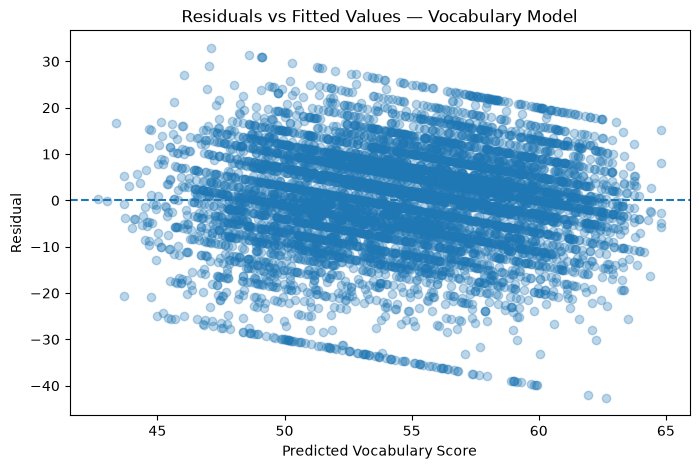

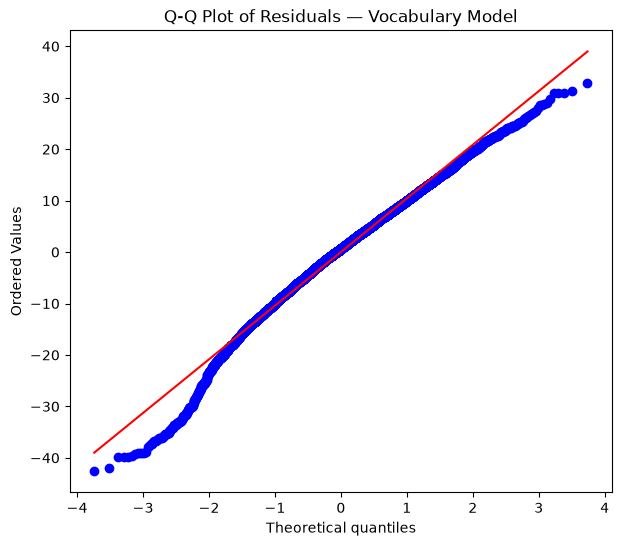

In [61]:
# ============================================================
# Step 11B — Preliminary residual diagnostics: Vocabulary
# Preliminary Vocabulary Model
# ============================================================

import matplotlib.pyplot as plt
import scipy.stats as stats

# Get fitted values and residuals
fitted = vocab_m3.fittedvalues
residuals = vocab_m3.resid

print("=" * 70)
print("VOCABULARY MODEL — RESIDUAL SUMMARY")
print("=" * 70)

print(residuals.describe())

# ------------------------------------------------------------
# Plot 1: Residuals vs fitted values
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    fitted,
    residuals,
    alpha=0.3
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Vocabulary Score")
plt.ylabel("Residual")

plt.title("Residuals vs Fitted Values — Vocabulary Model")

plt.show()


# ------------------------------------------------------------
# Plot 2: Q-Q plot
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

stats.probplot(
    residuals,
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Residuals — Vocabulary Model")

plt.show()

## Step 11C — HC3 robust standard errors

HC3 keeps the same regression coefficients but makes the standard errors, confidence intervals and p-values more robust to heteroskedasticity.

**Finding:** The Vocabulary association remains very clear. The Pattern association remains tiny and close to the conventional significance threshold.


In [62]:
# ============================================================
# STEP 11C — ROBUST STANDARD ERRORS (HC3)
# ============================================================

# Robust versions of the preliminary models
vocab_m3_robust = vocab_m3.get_robustcov_results(cov_type="HC3")
pattern_m3_robust = pattern_m3.get_robustcov_results(cov_type="HC3")

# Find BGREENSP position
vocab_idx = vocab_m3.model.exog_names.index("BGREENSP")
pattern_idx = pattern_m3.model.exog_names.index("BGREENSP")

print("=" * 70)
print("VOCABULARY — GREEN SPACE WITH HC3 ROBUST STANDARD ERRORS")
print("=" * 70)

print("B:", round(vocab_m3_robust.params[vocab_idx], 4))
print("Robust SE:", round(vocab_m3_robust.bse[vocab_idx], 4))
print("t:", round(vocab_m3_robust.tvalues[vocab_idx], 4))
print("p:", vocab_m3_robust.pvalues[vocab_idx])

ci = vocab_m3_robust.conf_int()[vocab_idx]
print("95% CI:", round(ci[0], 4), "to", round(ci[1], 4))


print("\n" + "=" * 70)
print("PATTERN CONSTRUCTION — GREEN SPACE WITH HC3 ROBUST STANDARD ERRORS")
print("=" * 70)

print("B:", round(pattern_m3_robust.params[pattern_idx], 4))
print("Robust SE:", round(pattern_m3_robust.bse[pattern_idx], 4))
print("t:", round(pattern_m3_robust.tvalues[pattern_idx], 4))
print("p:", pattern_m3_robust.pvalues[pattern_idx])

ci = pattern_m3_robust.conf_int()[pattern_idx]
print("95% CI:", round(ci[0], 4), "to", round(ci[1], 4))

VOCABULARY — GREEN SPACE WITH HC3 ROBUST STANDARD ERRORS
B: 0.4345
Robust SE: 0.042
t: 10.3526
p: 5.994120515301158e-25
95% CI: 0.3522 to 0.5167

PATTERN CONSTRUCTION — GREEN SPACE WITH HC3 ROBUST STANDARD ERRORS
B: 0.083
Robust SE: 0.0391
t: 2.1241
p: 0.03369138063051763
95% CI: 0.0064 to 0.1596


**Result interpretation:** Robust standard errors do not materially alter the Vocabulary conclusion. Pattern Construction remains a very small effect close to the significance boundary.


# Step 12 — Alternative green-space measure sensitivity analysis

## Step 12A — Create the `BGRND` sensitivity sample

`BGRND` is a ward-level UK-wide green-space measure with far less missingness than `BGREENSP`, producing a much larger complete sample (**N = 11,766**).


In [63]:
# ============================================================
# STEP 12A — BGRND SENSITIVITY ANALYSIS SAMPLE
# ============================================================

sensitivity = master[
    [
        "MCSID",
        "child_num",
        "child_sex",
        "income_quintile",
        "parent_education",
        "HLE_score",
        "BGRND",
        "vocabulary_tscore",
        "pattern_tscore"
    ]
].dropna().copy()


print("=" * 70)
print("BGRND SENSITIVITY ANALYSIS SAMPLE")
print("=" * 70)

print("\nNumber of children:", len(sensitivity))

print("\nDuplicate child IDs:")
print(
    sensitivity.duplicated(
        subset=["MCSID", "child_num"]
    ).sum()
)

print("\nBGRND distribution:")
print(
    sensitivity["BGRND"]
    .value_counts()
    .sort_index()
)

print("\nBGRND descriptive statistics:")
print(
    sensitivity["BGRND"]
    .describe()
)

BGRND SENSITIVITY ANALYSIS SAMPLE

Number of children: 11766

Duplicate child IDs:
0

BGRND distribution:
BGRND
1.0     1765
2.0     1488
3.0     1395
4.0     1527
5.0     1244
6.0     1262
7.0      883
8.0      896
9.0      747
10.0     559
Name: count, dtype: int64

BGRND descriptive statistics:
count    11766.000000
mean         4.630971
std          2.702436
min          1.000000
25%          2.000000
50%          4.000000
75%          7.000000
max         10.000000
Name: BGRND, dtype: float64


## Step 12B — Check that `BGRND` runs in the same direction as `BGREENSP`

The measures are strongly positively correlated (`r ≈ .721`), and average `BGRND` rises steadily across `BGREENSP` deciles.


In [64]:
# ============================================================
# STEP 12B — CHECK BGRND DIRECTION AGAINST BGREENSP
# ============================================================

comparison = master[
    ["BGREENSP", "BGRND"]
].dropna().copy()

print("=" * 70)
print("BGRND vs BGREENSP — CODING DIRECTION CHECK")
print("=" * 70)

print("\nChildren with both measures:")
print(len(comparison))

print("\nCorrelation:")
print(
    comparison[
        ["BGREENSP", "BGRND"]
    ].corr().round(3)
)

print("\nMean BGRND within each BGREENSP decile:")
print(
    comparison
    .groupby("BGREENSP")["BGRND"]
    .agg(["count", "mean", "median"])
    .round(2)
)

BGRND vs BGREENSP — CODING DIRECTION CHECK

Children with both measures:
10205

Correlation:
          BGREENSP  BGRND
BGREENSP     1.000  0.721
BGRND        0.721  1.000

Mean BGRND within each BGREENSP decile:
          count  mean  median
BGREENSP                     
1.0        1191  2.03     1.0
2.0        1493  2.21     2.0
3.0        1049  2.70     2.0
4.0        1049  2.80     2.0
5.0         979  3.04     3.0
6.0        1011  3.77     4.0
7.0         830  4.13     4.0
8.0        1040  5.07     5.0
9.0         729  6.71     7.0
10.0        834  8.63     9.0


## Step 12C — Refit the hierarchical models using `BGRND`

**Key finding:**
- Vocabulary remains positively associated with green space in the larger alternative-exposure sample.
- Pattern Construction is not clearly associated with `BGRND`.

This strengthens the Vocabulary finding and weakens the case for a robust Pattern Construction effect.


In [65]:
# ============================================================
# STEP 12C — BGRND SENSITIVITY ANALYSIS
# Hierarchical regression for both cognitive outcomes
# ============================================================

import statsmodels.formula.api as smf
import statsmodels.api as sm


# ============================================================
# VOCABULARY
# ============================================================

sens_vocab_m1 = smf.ols(
    "vocabulary_tscore ~ child_sex + income_quintile + parent_education",
    data=sensitivity
).fit()

sens_vocab_m2 = smf.ols(
    "vocabulary_tscore ~ child_sex + income_quintile + parent_education + HLE_score",
    data=sensitivity
).fit()

sens_vocab_m3 = smf.ols(
    "vocabulary_tscore ~ child_sex + income_quintile + parent_education + HLE_score + BGRND",
    data=sensitivity
).fit()


print("=" * 75)
print("BGRND SENSITIVITY ANALYSIS — VOCABULARY")
print("=" * 75)

print("\nMODEL 1 — Background factors")
print("R²:", round(sens_vocab_m1.rsquared, 4))

print("\nMODEL 2 — Add HLE")
print("R²:", round(sens_vocab_m2.rsquared, 4))
print(
    "ΔR²:",
    round(sens_vocab_m2.rsquared - sens_vocab_m1.rsquared, 4)
)

print("\nMODEL 3 — Add BGRND")
print("R²:", round(sens_vocab_m3.rsquared, 4))
print(
    "ΔR²:",
    round(sens_vocab_m3.rsquared - sens_vocab_m2.rsquared, 4)
)

print("\nBGRND coefficient:")
print("B:", round(sens_vocab_m3.params["BGRND"], 4))
print("SE:", round(sens_vocab_m3.bse["BGRND"], 4))
print("p:", sens_vocab_m3.pvalues["BGRND"])

ci = sens_vocab_m3.conf_int().loc["BGRND"]
print(
    "95% CI:",
    round(ci.iloc[0], 4),
    "to",
    round(ci.iloc[1], 4)
)

print("\nModel comparison:")
print(
    sm.stats.anova_lm(
        sens_vocab_m1,
        sens_vocab_m2,
        sens_vocab_m3
    )
)


# ============================================================
# PATTERN CONSTRUCTION
# ============================================================

sens_pattern_m1 = smf.ols(
    "pattern_tscore ~ child_sex + income_quintile + parent_education",
    data=sensitivity
).fit()

sens_pattern_m2 = smf.ols(
    "pattern_tscore ~ child_sex + income_quintile + parent_education + HLE_score",
    data=sensitivity
).fit()

sens_pattern_m3 = smf.ols(
    "pattern_tscore ~ child_sex + income_quintile + parent_education + HLE_score + BGRND",
    data=sensitivity
).fit()


print("\n" + "=" * 75)
print("BGRND SENSITIVITY ANALYSIS — PATTERN CONSTRUCTION")
print("=" * 75)

print("\nMODEL 1 — Background factors")
print("R²:", round(sens_pattern_m1.rsquared, 4))

print("\nMODEL 2 — Add HLE")
print("R²:", round(sens_pattern_m2.rsquared, 4))
print(
    "ΔR²:",
    round(sens_pattern_m2.rsquared - sens_pattern_m1.rsquared, 4)
)

print("\nMODEL 3 — Add BGRND")
print("R²:", round(sens_pattern_m3.rsquared, 4))
print(
    "ΔR²:",
    round(sens_pattern_m3.rsquared - sens_pattern_m2.rsquared, 4)
)

print("\nBGRND coefficient:")
print("B:", round(sens_pattern_m3.params["BGRND"], 4))
print("SE:", round(sens_pattern_m3.bse["BGRND"], 4))
print("p:", sens_pattern_m3.pvalues["BGRND"])

ci = sens_pattern_m3.conf_int().loc["BGRND"]
print(
    "95% CI:",
    round(ci.iloc[0], 4),
    "to",
    round(ci.iloc[1], 4)
)

print("\nModel comparison:")
print(
    sm.stats.anova_lm(
        sens_pattern_m1,
        sens_pattern_m2,
        sens_pattern_m3
    )
)

BGRND SENSITIVITY ANALYSIS — VOCABULARY

MODEL 1 — Background factors
R²: 0.092

MODEL 2 — Add HLE
R²: 0.104
ΔR²: 0.012

MODEL 3 — Add BGRND
R²: 0.1148
ΔR²: 0.0109

BGRND coefficient:
B: 0.4322
SE: 0.036
p: 4.5322426900195704e-33
95% CI: 0.3617 to 0.5027

Model comparison:
   df_resid           ssr  df_diff       ss_diff           F        Pr(>F)
0   11762.0  1.327977e+06      0.0           NaN         NaN           NaN
1   11761.0  1.310456e+06      1.0  17520.141047  159.155841  2.969990e-36
2   11760.0  1.294560e+06      1.0  15896.004194  144.401915  4.532243e-33

BGRND SENSITIVITY ANALYSIS — PATTERN CONSTRUCTION

MODEL 1 — Background factors
R²: 0.0401

MODEL 2 — Add HLE
R²: 0.0424
ΔR²: 0.0024

MODEL 3 — Add BGRND
R²: 0.0425
ΔR²: 0.0001

BGRND coefficient:
B: 0.0409
SE: 0.0346
p: 0.23757764689852312
95% CI: -0.027 to 0.1088

Model comparison:
   df_resid           ssr  df_diff      ss_diff          F        Pr(>F)
0   11762.0  1.203065e+06      0.0          NaN        NaN         

**Result interpretation:** Vocabulary replicates with an alternative green-space measure in a much larger sample. Pattern Construction does not. This is one of the strongest pieces of evidence that the Vocabulary association is more robust.


# Step 13 — Dependence between siblings/twins

## Step 13A — How much family clustering exists?

Only a small proportion of the primary sample comes from families contributing two cohort children.

**Finding:** 188 children (2.51%) belong to 94 multi-child families; the maximum is two cohort children per family.


In [66]:
# ============================================================
# STEP 13A — CHECK FAMILY CLUSTERING
# Primary BGREENSP analysis sample
# ============================================================

print("=" * 70)
print("FAMILY CLUSTERING — PRIMARY ANALYSIS SAMPLE")
print("=" * 70)

# Number of children contributed by each family
children_per_family = primary.groupby("MCSID").size()

print("\nTotal children:")
print(len(primary))

print("\nUnique families:")
print(primary["MCSID"].nunique())

print("\nChildren per family:")
print(
    children_per_family
    .value_counts()
    .sort_index()
)

# Families contributing more than one cohort child
multi_child_families = children_per_family[
    children_per_family > 1
]

print("\n" + "=" * 70)
print("MULTI-CHILD FAMILIES")
print("=" * 70)

print("\nNumber of families with >1 child:")
print(len(multi_child_families))

print("\nNumber of children from multi-child families:")
print(multi_child_families.sum())

print("\nPercentage of children belonging to multi-child families:")
print(
    round(
        multi_child_families.sum() / len(primary) * 100,
        2
    ),
    "%"
)

print("\nMaximum number of cohort children from one family:")
print(children_per_family.max())

FAMILY CLUSTERING — PRIMARY ANALYSIS SAMPLE

Total children:
7504

Unique families:
7410

Children per family:
1    7316
2      94
Name: count, dtype: int64

MULTI-CHILD FAMILIES

Number of families with >1 child:
94

Number of children from multi-child families:
188

Percentage of children belonging to multi-child families:
2.51 %

Maximum number of cohort children from one family:
2


## Step 13B — Family-cluster robust standard errors

This adjusts uncertainty for the fact that siblings/twins from the same family may share unmeasured characteristics.

**Finding:** The Vocabulary result is essentially unchanged. The Pattern estimate remains very small and borderline.


In [67]:
# ============================================================
# STEP 13B — CLUSTER-ROBUST STANDARD ERRORS BY FAMILY
# Primary BGREENSP models
# ============================================================

# Vocabulary — cluster by family MCSID
vocab_cluster = vocab_m3.get_robustcov_results(
    cov_type="cluster",
    groups=primary["MCSID"]
)

# Pattern Construction — cluster by family MCSID
pattern_cluster = pattern_m3.get_robustcov_results(
    cov_type="cluster",
    groups=primary["MCSID"]
)

# Find position of BGREENSP
vocab_idx = vocab_m3.model.exog_names.index("BGREENSP")
pattern_idx = pattern_m3.model.exog_names.index("BGREENSP")


# ============================================================
# VOCABULARY
# ============================================================

print("=" * 70)
print("VOCABULARY — CLUSTER-ROBUST BY FAMILY")
print("=" * 70)

print("B:", round(vocab_cluster.params[vocab_idx], 4))
print("Cluster-robust SE:", round(vocab_cluster.bse[vocab_idx], 4))
print("t:", round(vocab_cluster.tvalues[vocab_idx], 4))
print("p:", vocab_cluster.pvalues[vocab_idx])

ci = vocab_cluster.conf_int()[vocab_idx]

print(
    "95% CI:",
    round(ci[0], 4),
    "to",
    round(ci[1], 4)
)


# ============================================================
# PATTERN CONSTRUCTION
# ============================================================

print("\n" + "=" * 70)
print("PATTERN CONSTRUCTION — CLUSTER-ROBUST BY FAMILY")
print("=" * 70)

print("B:", round(pattern_cluster.params[pattern_idx], 4))
print("Cluster-robust SE:", round(pattern_cluster.bse[pattern_idx], 4))
print("t:", round(pattern_cluster.tvalues[pattern_idx], 4))
print("p:", pattern_cluster.pvalues[pattern_idx])

ci = pattern_cluster.conf_int()[pattern_idx]

print(
    "95% CI:",
    round(ci[0], 4),
    "to",
    round(ci[1], 4)
)

VOCABULARY — CLUSTER-ROBUST BY FAMILY
B: 0.4345
Cluster-robust SE: 0.0423
t: 10.2815
p: 1.2499019445170314e-24
95% CI: 0.3516 to 0.5173

PATTERN CONSTRUCTION — CLUSTER-ROBUST BY FAMILY
B: 0.083
Cluster-robust SE: 0.0393
t: 2.112
p: 0.034719489081851275
95% CI: 0.006 to 0.1601


**Result interpretation:** Accounting for the small amount of within-family dependence does not materially change the estimates.


# Step 14 — Check whether green-space decile can be treated linearly

The primary model treats `BGREENSP` as a 1–10 continuous trend. This assumes the average step from 1→2 is comparable to 8→9.

A more flexible model treating all ten deciles as separate categories does **not** improve Vocabulary model fit (`p ≈ .576`), supporting the simpler linear specification.


In [68]:
# ============================================================
# STEP 14A — CHECK LINEARITY OF BGREENSP
# Vocabulary outcome
# ============================================================

import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

# ------------------------------------------------------------
# Current model:
# BGREENSP treated as a continuous 1–10 variable
# ------------------------------------------------------------

vocab_green_linear = smf.ols(
    """
    vocabulary_tscore ~
    C(child_sex) +
    income_quintile +
    parent_education +
    HLE_score +
    BGREENSP
    """,
    data=primary
).fit()


# ------------------------------------------------------------
# Alternative model:
# BGREENSP treated as 10 separate categories
# ------------------------------------------------------------

vocab_green_categorical = smf.ols(
    """
    vocabulary_tscore ~
    C(child_sex) +
    income_quintile +
    parent_education +
    HLE_score +
    C(BGREENSP)
    """,
    data=primary
).fit()


print("=" * 75)
print("VOCABULARY — LINEARITY CHECK FOR BGREENSP")
print("=" * 75)

print("\nLINEAR GREEN-SPACE MODEL")
print("R²:", round(vocab_green_linear.rsquared, 4))
print("Adjusted R²:", round(vocab_green_linear.rsquared_adj, 4))
print("AIC:", round(vocab_green_linear.aic, 2))


print("\nCATEGORICAL GREEN-SPACE MODEL")
print("R²:", round(vocab_green_categorical.rsquared, 4))
print("Adjusted R²:", round(vocab_green_categorical.rsquared_adj, 4))
print("AIC:", round(vocab_green_categorical.aic, 2))


print("\n" + "=" * 75)
print("DOES THE MORE FLEXIBLE CATEGORICAL MODEL FIT BETTER?")
print("=" * 75)

print(
    anova_lm(
        vocab_green_linear,
        vocab_green_categorical
    )
)

VOCABULARY — LINEARITY CHECK FOR BGREENSP

LINEAR GREEN-SPACE MODEL
R²: 0.1373
Adjusted R²: 0.1367
AIC: 56576.72

CATEGORICAL GREEN-SPACE MODEL
R²: 0.138
Adjusted R²: 0.1365
AIC: 56586.07

DOES THE MORE FLEXIBLE CATEGORICAL MODEL FIT BETTER?
   df_resid            ssr  df_diff     ss_diff         F    Pr(>F)
0    7498.0  825097.857724      0.0         NaN       NaN       NaN
1    7490.0  824366.776660      8.0  731.081064  0.830304  0.575688


**Result interpretation:** There is no evidence that a ten-category green-space model fits Vocabulary better than a simple linear decile trend. The simpler 1–10 specification is therefore defensible.


# Step 15 — MCS survey-design sensitivity analysis

MCS is a complex longitudinal survey rather than a simple random sample. This section identifies the official weight, stratum and sampling-cluster variables before carrying out a design-sensitive robustness analysis.

## Step 15A — Check whether weights are already in the reduced analysis data


In [69]:
# ============================================================
# STEP 15A — FIND POSSIBLE MCS WEIGHT VARIABLES
# ============================================================

print("=" * 75)
print("SEARCHING FOR POSSIBLE WEIGHT VARIABLES")
print("=" * 75)

for df_name in [
    "cog",
    "master"
]:
    
    if df_name in globals():
        df = globals()[df_name]
        
        possible_weights = [
            col for col in df.columns
            if any(
                word in col.lower()
                for word in ["weight", "wgt", "wt"]
            )
        ]
        
        print(f"\n{df_name}:")
        print(possible_weights)
        

SEARCHING FOR POSSIBLE WEIGHT VARIABLES

cog:
[]

master:
[]


## Step 15B — Search Sweep 3 metadata for candidate weighting variables

The initial broad search also finds physical body-weight variables, so candidate names must be verified against the MCS longitudinal documentation rather than selected by keyword alone.


In [70]:
# ============================================================
# STEP 15B — SEARCH SWEEP 3 FILES FOR WEIGHT VARIABLES
# ============================================================

from pathlib import Path
import pyreadstat
import pandas as pd

sweep3_folder = DATA_DIR / "SWEEP3"
sweep3_files = list(sweep3_folder.rglob("*.sav"))

weight_results = []

for file in sweep3_files:
    
    try:
        _, meta = pyreadstat.read_sav(
            str(file),
            metadataonly=True
        )
        
        for var in meta.column_names:
            
            label = meta.column_names_to_labels.get(var, "")
            
            search_text = f"{var} {label}".lower()
            
            if any(
                term in search_text
                for term in [
                    "weight",
                    "weighting",
                    "survey weight",
                    "response weight",
                    "longitudinal weight"
                ]
            ):
                
                weight_results.append({
                    "Variable": var,
                    "Label": label,
                    "File": file.name,
                    "Full Path": str(file)
                })
                
    except Exception as e:
        print("Could not read:", file.name, e)

weight_results = pd.DataFrame(weight_results)

print("=" * 80)
print("POSSIBLE SWEEP 3 WEIGHT VARIABLES")
print("=" * 80)

print("Number found:", len(weight_results))

display(weight_results)

POSSIBLE SWEEP 3 WEIGHT VARIABLES
Number found: 33


,Variable,Label,File,Full Path
0,CCWTOC00,Weight outcome,mcs3_cm_interview.sav,/Users/fizza/Documents/university/Dissertation...
1,CCWTDN00,PHYS: Whether weight measured,mcs3_cm_interview.sav,/Users/fizza/Documents/university/Dissertation...
2,CCWTCM00,PHYS: Weight in Kilograms,mcs3_cm_interview.sav,/Users/fizza/Documents/university/Dissertation...
3,CCWTRL0A,PHYS: Weight measurement circumstances,mcs3_cm_interview.sav,/Users/fizza/Documents/university/Dissertation...
4,CCWTRL0B,PHYS: Weight measurement circumstances,mcs3_cm_interview.sav,/Users/fizza/Documents/university/Dissertation...
5,CCWTOT0A,PHYS: Weight measurement circumstances (final),mcs3_cm_interview.sav,/Users/fizza/Documents/university/Dissertation...
6,CCWTOTAA,PHYS: Weight measurement circumstances (final),mcs3_cm_interview.sav,/Users/fizza/Documents/university/Dissertation...
7,CCWTOTAB,PHYS: Weight measurement circumstances (final),mcs3_cm_interview.sav,/Users/fizza/Documents/university/Dissertation...
8,CCWTEL00,PHYS: Anything else about weight measurement,mcs3_cm_interview.sav,/Users/fizza/Documents/university/Dissertation...
9,CCWTEX0A,PHYS: Anything else about weight measurement (...,mcs3_cm_interview.sav,/Users/fizza/Documents/university/Dissertation...


## Step 15C — List the available Sweep 3 datasets

This establishes that the survey-design variables are not contained in the twelve substantive Sweep 3 analysis files.


In [71]:
# ============================================================
# STEP 15C — LIST ALL SWEEP 3 SPSS FILES
# ============================================================

from pathlib import Path

sweep3_folder = DATA_DIR / "SWEEP3"
sweep3_files = sorted(sweep3_folder.rglob("*.sav"))

print("=" * 80)
print("ALL SWEEP 3 .SAV FILES")
print("=" * 80)

print("\nNumber of files:", len(sweep3_files))

for file in sweep3_files:
    print(file.name)

ALL SWEEP 3 .SAV FILES

Number of files: 12
mcs3_cm_cognitive_assessment.sav
mcs3_cm_derived.sav
mcs3_cm_interview.sav
mcs3_cm_teacher_survey.sav
mcs3_family_derived.sav
mcs3_geographically_linked_data.sav
mcs3_hhgrid.sav
mcs3_older_siblings_questionnaire.sav
mcs3_parent_cm_interview.sav
mcs3_parent_derived.sav
mcs3_parent_interview.sav
mcs3_proxy_partner_interview.sav


## Step 15D — Search the whole dissertation data folder for cross-sweep files

This finds the longitudinal data dictionary but initially confirms the survey-design `.sav` file must be located separately.


In [72]:
# ============================================================
# STEP 15D — SEARCH MCS_DATA FOR LONGITUDINAL / WEIGHT FILES
# ============================================================

from pathlib import Path

base = DATA_DIR
print("=" * 80)
print("POSSIBLE LONGITUDINAL / WEIGHT / DESIGN FILES")
print("=" * 80)

keywords = [
    "longitud",
    "weight",
    "design",
    "family_file",
    "cm_file"
]

matches = []

for file in base.rglob("*"):
    if file.is_file():
        name = file.name.lower()

        if any(word in name for word in keywords):
            matches.append(file)

print("\nNumber found:", len(matches))

for file in matches:
    print(file)

POSSIBLE LONGITUDINAL / WEIGHT / DESIGN FILES

Number found: 5
/Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA/SWEEP3/mrdoc/excel/mcs_longitudinal_data_dictionary_2021-02-03.xlsx
/Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA/SWEEP2/mrdoc/excel/mcs_longitudinal_data_dictionary_2021-02-03.xlsx
/Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA/UKDA-8172-spss/mrdoc/pdf/millenniumcohortstudy_longitudinalfilesuserguide.pdf
/Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA/UKDA-8172-spss/spss/spss28/mcs_longitudinal_family_file_1-7.sav
/Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA/UKDA-8172-spss/spss/spss28/mcs_longitudinal_cm_file.sav


## Step 15E — Search the longitudinal data dictionary

The dictionary is used to identify the official MCS3 design variables rather than guessing variable names.


In [73]:
# ============================================================
# STEP 15E — INSPECT LONGITUDINAL DATA DICTIONARY
# ============================================================

import pandas as pd
from pathlib import Path


dictionary_path = (
    DATA_DIR
    / "SWEEP3"
    / "mrdoc"
    / "excel"
    / "mcs_longitudinal_data_dictionary_2021-02-03.xlsx"
)
# Show sheet names
xls = pd.ExcelFile(dictionary_path)

print("=" * 75)
print("LONGITUDINAL DATA DICTIONARY")
print("=" * 75)

print("\nSheet names:")
print(xls.sheet_names)

# Search every sheet for important survey-design terms
terms = [
    "covwt2",
    "pttype2",
    "sptn00",
    "overall weight",
    "stratum",
    "primary sampling",
    "psu"
]

print("\n" + "=" * 75)
print("SEARCH RESULTS")
print("=" * 75)

for sheet in xls.sheet_names:

    df = pd.read_excel(dictionary_path, sheet_name=sheet)

    text = df.astype(str).apply(
        lambda col: col.str.lower()
    )

    mask = pd.Series(False, index=df.index)

    for term in terms:
        mask = mask | text.apply(
            lambda col: col.str.contains(
                term.lower(),
                na=False
            )
        ).any(axis=1)

    matches = df[mask]

    if len(matches) > 0:
        print(f"\nSHEET: {sheet}")
        print("-" * 75)
        display(matches)

LONGITUDINAL DATA DICTIONARY

Sheet names:
['How_to_use_the_DataDict', 'Survey_Collection_DataDict', 'Version_log']

SEARCH RESULTS

SHEET: Survey_Collection_DataDict
---------------------------------------------------------------------------


,CLS_variable_code,CLS_questionnaire_CAPI_code,CLS_questionnaire_general_section,CLS_questionnaire_section_or_scale,CLS_collection_instrument,CLS_information_provider,CLOSER_platform_topic,Sweep-Year-Age,licence_position_of_dataset,dataset_name,var_order,variable_name,variable_label
63,123.034,NaN,NaN,Derived variable,Derived Variable,Derived information,NaN,Sweep 1 - 2001/2 - 9 months old,EUL mcs1 survey,mcs1_family_derived.sav,33,ADPTY200,Stratum within Country
575,109.028,SUPP,NaN,Support to Parent,Survey response,Parent/Carer respondent,Social support,Sweep 1 - 2001/2 - 9 months old,EUL mcs1 survey,mcs1_parent_interview.sav,160,APSUPP0A,Support sought since birth MC1
576,109.029,SUPP,NaN,Support to Parent,Survey response,Parent/Carer respondent,Social support,Sweep 1 - 2001/2 - 9 months old,EUL mcs1 survey,mcs1_parent_interview.sav,161,APSUPP0B,Support sought since birth MC2
577,109.030,SUPP,NaN,Support to Parent,Survey response,Parent/Carer respondent,Social support,Sweep 1 - 2001/2 - 9 months old,EUL mcs1 survey,mcs1_parent_interview.sav,162,APSUPP0C,Support sought since birth MC3
578,109.031,SUPP,NaN,Support to Parent,Survey response,Parent/Carer respondent,Social support,Sweep 1 - 2001/2 - 9 months old,EUL mcs1 survey,mcs1_parent_interview.sav,163,APSUPP0D,Support sought since birth MC4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
19028,NaN,SUPN,Parent/Carer Web questionnaire (CAWI),Employment Income and Housing,Survey response,Parent,NaN,Sweep 7 - 2018/19 - 17 years old,EUL mcs7 survey,mcs7_parent_interview.sav,129,GPSUPNF0,Do/Did you supervise more than 25 people in jo...
19029,NaN,SUPN,Parent/Carer Web questionnaire (CAWI),Employment Income and Housing,Survey response,Parent,NaN,Sweep 7 - 2018/19 - 17 years old,EUL mcs7 survey,mcs7_parent_interview.sav,130,GPSUPNG0,Do/Did you supervise more than 25 people in jo...
19030,NaN,SUPN,Parent/Carer Web questionnaire (CAWI),Employment Income and Housing,Survey response,Parent,NaN,Sweep 7 - 2018/19 - 17 years old,EUL mcs7 survey,mcs7_parent_interview.sav,131,GPSUPNH0,Do/Did you supervise more than 25 people in jo...
19031,NaN,SUPN,Parent/Carer Web questionnaire (CAWI),Employment Income and Housing,Survey response,Parent,NaN,Sweep 7 - 2018/19 - 17 years old,EUL mcs7 survey,mcs7_parent_interview.sav,132,GPSUPNI0,Do/Did you supervise more than 25 people in jo...


## Step 15F — Confirm the exact survey-design variables

The dictionary identifies:

- `COVWT2` — MCS3 whole-UK overall weight including non-response adjustment
- `PTTYPE2` — stratum
- `SPTN00` — fieldwork/sampling point (PSU)
- `NH2` — population correction factor


In [74]:
# ============================================================
# STEP 15F — EXACT SEARCH FOR MCS SURVEY DESIGN VARIABLES
# ============================================================

import pandas as pd

dictionary = pd.read_excel(
    dictionary_path,
    sheet_name="Survey_Collection_DataDict"
)

targets = [
    "COVWT2",
    "PTTYPE2",
    "SPTN00",
    "NH2"
]

print("=" * 80)
print("EXACT MCS SURVEY-DESIGN VARIABLE SEARCH")
print("=" * 80)

for target in targets:

    mask = dictionary.astype(str).apply(
        lambda col: col.str.upper().eq(target)
    ).any(axis=1)

    result = dictionary[mask]

    print(f"\n{target}")
    print("-" * 60)

    if len(result) == 0:
        print("NOT FOUND")
    else:
        display(
            result[
                [
                    "Sweep-Year-Age",
                    "dataset_name",
                    "variable_name",
                    "variable_label"
                ]
            ]
        )

EXACT MCS SURVEY-DESIGN VARIABLE SEARCH

COVWT2
------------------------------------------------------------


,Sweep-Year-Age,dataset_name,variable_name,variable_label
18634,MCS cross-sweep information,mcs_longitudinal_family_file.sav,COVWT2,S3:Overall Weight (inc NR adjustment) whole uk...



PTTYPE2
------------------------------------------------------------


,Sweep-Year-Age,dataset_name,variable_name,variable_label
18615,MCS cross-sweep information,mcs_longitudinal_family_file.sav,PTTYPE2,Stratum within Country



SPTN00
------------------------------------------------------------


,Sweep-Year-Age,dataset_name,variable_name,variable_label
18616,MCS cross-sweep information,mcs_longitudinal_family_file.sav,SPTN00,Fieldwork point number incorporating superward...



NH2
------------------------------------------------------------


,Sweep-Year-Age,dataset_name,variable_name,variable_label
18617,MCS cross-sweep information,mcs_longitudinal_family_file.sav,NH2,Population Correction Factor (for use in Stata)


## Step 15G — Locate the actual longitudinal family file

The required file is found as `mcs_longitudinal_family_file_1-7.sav`.


In [75]:
# ============================================================
# STEP 15G — FIND THE LONGITUDINAL FAMILY FILE
# ============================================================

from pathlib import Path

base = DATA_DIR

print("=" * 80)
print("LONGITUDINAL FAMILY FILE SEARCH")
print("=" * 80)

matches = []

for f in base.rglob("*"):
    if (
        f.is_file()
        and "longitudinal_family_file" in f.name.lower()
    ):
        matches.append(f)

print("\nNumber found:", len(matches))

for f in matches:
    print("\nFilename:", f.name)
    print("Full path:", f)
    print("Extension:", f.suffix)

LONGITUDINAL FAMILY FILE SEARCH

Number found: 1

Filename: mcs_longitudinal_family_file_1-7.sav
Full path: /Users/fizza/Documents/university/Dissertation/notebooks/MCS_DATA/UKDA-8172-spss/spss/spss28/mcs_longitudinal_family_file_1-7.sav
Extension: .sav


## Step 15I — Load the survey-design variables correctly

The longitudinal file uses lowercase variable names. After loading, `mcsid` is renamed to `MCSID` so it can be merged with the analysis data.

**Finding:** One row per family and no duplicated `MCSID`.


In [76]:
# ============================================================
# STEP 15I — LOAD MCS SURVEY-DESIGN VARIABLES
# Correct lowercase variable names
# ============================================================

import pyreadstat

longitudinal_path = (
    DATA_DIR
    / "UKDA-8172-spss"
    / "spss"
    / "spss28"
    / "mcs_longitudinal_family_file_1-7.sav"
)
survey_design, survey_meta = pyreadstat.read_sav(
    longitudinal_path,
    usecols=[
        "mcsid",
        "covwt2",
        "pttype2",
        "sptn00",
        "nh2"
    ]
)

# Rename ID to match our existing datasets
survey_design = survey_design.rename(
    columns={"mcsid": "MCSID"}
)

print("=" * 75)
print("MCS LONGITUDINAL SURVEY-DESIGN DATA")
print("=" * 75)

print("\nShape:")
print(survey_design.shape)

print("\nColumns:")
print(survey_design.columns.tolist())

print("\nUnique MCSID:")
print(survey_design["MCSID"].nunique())

print("\nDuplicated MCSID:")
print(survey_design["MCSID"].duplicated().sum())


print("\n" + "=" * 75)
print("VARIABLE AVAILABILITY")
print("=" * 75)

for var in ["covwt2", "pttype2", "sptn00", "nh2"]:

    print(f"\n{var}")
    print("-" * 45)

    print("Available:", survey_design[var].notna().sum())
    print("Missing:", survey_design[var].isna().sum())

    print("\nDescriptive statistics:")
    print(survey_design[var].describe())
    


MCS LONGITUDINAL SURVEY-DESIGN DATA

Shape:
(19243, 5)

Columns:
['MCSID', 'pttype2', 'sptn00', 'nh2', 'covwt2']

Unique MCSID:
19243

Duplicated MCSID:
0

VARIABLE AVAILABILITY

covwt2
---------------------------------------------
Available: 15246
Missing: 3997

Descriptive statistics:
count    15246.000000
mean         1.023511
std          0.634713
min          0.123900
25%          0.448900
50%          0.972150
75%          1.648625
max          4.644900
Name: covwt2, dtype: float64

pttype2
---------------------------------------------
Available: 19243
Missing: 0

Descriptive statistics:
count    19243.000000
mean         3.480123
std          2.485517
min         -1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max          9.000000
Name: pttype2, dtype: float64

sptn00
---------------------------------------------
Available: 19243
Missing: 0

Descriptive statistics:
count       19243
unique        399
top       010313W
freq          429
Name: sptn00, 

## Step 15J — Add survey-design information to the primary sample

All 7,504 primary-analysis children have valid MCS3 weight, stratum and PSU information.

**Design coverage:** 248 PSUs across 9 strata.


In [77]:
# ============================================================
# STEP 15J — ADD SURVEY DESIGN TO PRIMARY ANALYSIS SAMPLE
# ============================================================

import numpy as np

# Keep only required design variables
design_clean = survey_design[
    ["MCSID", "covwt2", "pttype2", "sptn00", "nh2"]
].copy()

# MCS special code -1 = not applicable
design_clean["pttype2"] = design_clean["pttype2"].replace(-1, np.nan)
design_clean["nh2"] = design_clean["nh2"].replace(-1, np.nan)

# Merge onto the EXISTING primary sample
primary_survey = primary.merge(
    design_clean,
    on="MCSID",
    how="left",
    validate="many_to_one"
)

print("=" * 75)
print("PRIMARY SAMPLE + MCS SURVEY DESIGN")
print("=" * 75)

print("\nOriginal primary sample:")
print(len(primary))

print("\nAfter merge:")
print(len(primary_survey))

print("\nDuplicate child IDs:")
print(
    primary_survey.duplicated(
        subset=["MCSID", "child_num"]
    ).sum()
)


print("\n" + "=" * 75)
print("SURVEY-DESIGN AVAILABILITY IN PRIMARY SAMPLE")
print("=" * 75)

for var in ["covwt2", "pttype2", "sptn00", "nh2"]:

    available = primary_survey[var].notna().sum()
    missing = primary_survey[var].isna().sum()

    print(f"\n{var}")
    print("Available:", available)
    print("Missing:", missing)
    print(
        "Available %:",
        round(available / len(primary_survey) * 100, 2)
    )


# Complete design information
design_complete = primary_survey[
    ["covwt2", "pttype2", "sptn00"]
].notna().all(axis=1)

print("\n" + "=" * 75)
print("COMPLETE SURVEY-DESIGN SAMPLE")
print("=" * 75)

print("Children with weight + stratum + PSU:")
print(design_complete.sum())

print(
    "Percentage of primary sample:",
    round(design_complete.mean() * 100, 2),
    "%"
)

print("\nNumber of PSUs represented:")
print(
    primary_survey.loc[
        design_complete, "sptn00"
    ].nunique()
)

print("\nNumber of strata represented:")
print(
    primary_survey.loc[
        design_complete, "pttype2"
    ].nunique()
)

PRIMARY SAMPLE + MCS SURVEY DESIGN

Original primary sample:
7504

After merge:
7504

Duplicate child IDs:
0

SURVEY-DESIGN AVAILABILITY IN PRIMARY SAMPLE

covwt2
Available: 7504
Missing: 0
Available %: 100.0

pttype2
Available: 7504
Missing: 0
Available %: 100.0

sptn00
Available: 7504
Missing: 0
Available %: 100.0

nh2
Available: 7504
Missing: 0
Available %: 100.0

COMPLETE SURVEY-DESIGN SAMPLE
Children with weight + stratum + PSU:
7504
Percentage of primary sample: 100.0 %

Number of PSUs represented:
248

Number of strata represented:
9


**Result interpretation:** No primary-sample observations are lost when adding the official MCS survey-design information.


## Step 15K — Survey-design sensitivity: Vocabulary

This is a **sensitivity model**, not a full claim of a definitive complex-survey estimator. It uses the MCS3 whole-UK weight, stratum indicators and PSU-clustered standard errors.

**Finding:** The Vocabulary coefficient is attenuated from roughly 0.43 to roughly 0.19 per green-space decile, but remains positive and statistically supported. This means the magnitude should be interpreted cautiously, while the direction is robust.


> **Interpretation note:** COVWT2 is a whole-UK MCS3 weight, whereas the primary BGREENSP analytical sample is restricted to England because of the availability of the linked green-space measure. Therefore, this analysis is treated as a survey-design sensitivity check rather than as producing fully UK-representative estimates.

In [78]:
# ============================================================
# STEP 15K — MCS SURVEY-DESIGN SENSITIVITY ANALYSIS
# Vocabulary
# ============================================================

import statsmodels.formula.api as smf

# Weighted regression:
# - COVWT2 = MCS3 whole-UK non-response weight
# - C(pttype2) = sampling strata
# - SEs clustered by original MCS sampling PSU

survey_vocab = smf.wls(
    """
    vocabulary_tscore ~
    C(child_sex) +
    income_quintile +
    parent_education +
    HLE_score +
    BGREENSP +
    C(pttype2)
    """,
    data=primary_survey,
    weights=primary_survey["covwt2"]
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": primary_survey["sptn00"]
    }
)

print("=" * 75)
print("VOCABULARY — MCS SURVEY-DESIGN SENSITIVITY MODEL")
print("=" * 75)

print("\nNumber of children:")
print(int(survey_vocab.nobs))

print("\nNumber of PSUs:")
print(primary_survey["sptn00"].nunique())

print("\nNumber of strata:")
print(primary_survey["pttype2"].nunique())

print("\n" + "=" * 75)
print("GREEN-SPACE RESULT")
print("=" * 75)

print("B:", round(survey_vocab.params["BGREENSP"], 4))
print(
    "Design-adjusted SE:",
    round(survey_vocab.bse["BGREENSP"], 4)
)

print(
    "t/z:",
    round(survey_vocab.tvalues["BGREENSP"], 4)
)

print(
    "p:",
    survey_vocab.pvalues["BGREENSP"]
)

ci = survey_vocab.conf_int().loc["BGREENSP"]

print(
    "95% CI:",
    round(ci.iloc[0], 4),
    "to",
    round(ci.iloc[1], 4)
)


print("\n" + "=" * 75)
print("COMPARISON WITH PRIMARY MODEL")
print("=" * 75)

print(
    "Primary unweighted B:",
    round(vocab_m3.params["BGREENSP"], 4)
)

print(
    "Primary cluster-robust SE:",
    round(vocab_cluster.bse[
        vocab_m3.model.exog_names.index("BGREENSP")
    ], 4)
)

print(
    "Survey-design sensitivity B:",
    round(survey_vocab.params["BGREENSP"], 4)
)

print(
    "Survey-design sensitivity SE:",
    round(survey_vocab.bse["BGREENSP"], 4)
)

VOCABULARY — MCS SURVEY-DESIGN SENSITIVITY MODEL

Number of children:
7504

Number of PSUs:
248

Number of strata:
9

GREEN-SPACE RESULT
B: 0.1904
Design-adjusted SE: 0.0588
t/z: 3.2401
p: 0.0011950744813445005
95% CI: 0.0752 to 0.3055

COMPARISON WITH PRIMARY MODEL
Primary unweighted B: 0.4345
Primary cluster-robust SE: 0.0423
Survey-design sensitivity B: 0.1904
Survey-design sensitivity SE: 0.0588


**Result interpretation:** Survey-design adjustment substantially attenuates the Vocabulary effect size but does not eliminate the positive association. This is important: report the association as robust in direction but be cautious about its magnitude.


## Step 15L — Survey-design sensitivity: Pattern Construction

**Finding:** The Pattern Construction coefficient becomes close to zero, slightly negative, and clearly non-significant. This is strong evidence that the small primary Pattern association is not robust to survey-design adjustment.


In [79]:
# ============================================================
# STEP 15L — MCS SURVEY-DESIGN SENSITIVITY ANALYSIS
# Pattern Construction
# ============================================================

survey_pattern = smf.wls(
    """
    pattern_tscore ~
    C(child_sex) +
    income_quintile +
    parent_education +
    HLE_score +
    BGREENSP +
    C(pttype2)
    """,
    data=primary_survey,
    weights=primary_survey["covwt2"]
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": primary_survey["sptn00"]
    }
)

print("=" * 75)
print("PATTERN CONSTRUCTION — MCS SURVEY-DESIGN SENSITIVITY MODEL")
print("=" * 75)

print("\nGREEN-SPACE RESULT")

print("B:", round(survey_pattern.params["BGREENSP"], 4))
print(
    "Design-adjusted SE:",
    round(survey_pattern.bse["BGREENSP"], 4)
)

print(
    "t/z:",
    round(survey_pattern.tvalues["BGREENSP"], 4)
)

print(
    "p:",
    survey_pattern.pvalues["BGREENSP"]
)

ci = survey_pattern.conf_int().loc["BGREENSP"]

print(
    "95% CI:",
    round(ci.iloc[0], 4),
    "to",
    round(ci.iloc[1], 4)
)


print("\n" + "=" * 75)
print("COMPARISON WITH PRIMARY MODEL")
print("=" * 75)

pattern_idx = pattern_m3.model.exog_names.index("BGREENSP")

print(
    "Primary unweighted B:",
    round(pattern_m3.params["BGREENSP"], 4)
)

print(
    "Primary cluster-robust SE:",
    round(pattern_cluster.bse[pattern_idx], 4)
)

print(
    "Survey-design sensitivity B:",
    round(survey_pattern.params["BGREENSP"], 4)
)

print(
    "Survey-design sensitivity SE:",
    round(survey_pattern.bse["BGREENSP"], 4)
)

PATTERN CONSTRUCTION — MCS SURVEY-DESIGN SENSITIVITY MODEL

GREEN-SPACE RESULT
B: -0.0321
Design-adjusted SE: 0.0628
t/z: -0.5108
p: 0.609486781113858
95% CI: -0.1553 to 0.0911

COMPARISON WITH PRIMARY MODEL
Primary unweighted B: 0.083
Primary cluster-robust SE: 0.0393
Survey-design sensitivity B: -0.0321
Survey-design sensitivity SE: 0.0628


**Result interpretation:** Pattern Construction is not supported under survey-design adjustment. This strengthens the conclusion that evidence for a non-verbal/spatial association is weak and inconsistent.


# Step 16 — Organise model results into reporting tables

## Step 16A — Working master summary

This table collects the main and sensitivity estimates so different coefficients are not confused during dissertation writing.


In [80]:
# ============================================================
# STEP 16A — MASTER RESULTS SUMMARY TABLE
# ============================================================

import pandas as pd

results_summary = pd.DataFrame([
    
    # --------------------------------------------------------
    # VOCABULARY
    # --------------------------------------------------------
    
    {
        "Outcome": "Vocabulary",
        "Analysis": "Primary BGREENSP",
        "N": 7504,
        "Green_space_measure": "BGREENSP",
        "B": 0.4345,
        "SE": 0.0419,
        "CI_low": 0.3523,
        "CI_high": 0.5166,
        "p": 5.397e-25,
        "Delta_R2": 0.0124,
        "Interpretation": "Positive association"
    },
    
    {
        "Outcome": "Vocabulary",
        "Analysis": "HC3 robust SE",
        "N": 7504,
        "Green_space_measure": "BGREENSP",
        "B": 0.4345,
        "SE": 0.0420,
        "CI_low": 0.3522,
        "CI_high": 0.5167,
        "p": 5.994e-25,
        "Delta_R2": None,
        "Interpretation": "Positive association"
    },
    
    {
        "Outcome": "Vocabulary",
        "Analysis": "Family-cluster robust SE",
        "N": 7504,
        "Green_space_measure": "BGREENSP",
        "B": 0.4345,
        "SE": 0.0423,
        "CI_low": 0.3516,
        "CI_high": 0.5173,
        "p": 1.250e-24,
        "Delta_R2": None,
        "Interpretation": "Positive association"
    },
    
    {
        "Outcome": "Vocabulary",
        "Analysis": "Alternative green-space measure",
        "N": 11766,
        "Green_space_measure": "BGRND",
        "B": 0.4322,
        "SE": 0.0360,
        "CI_low": 0.3617,
        "CI_high": 0.5027,
        "p": 4.532e-33,
        "Delta_R2": 0.0109,
        "Interpretation": "Positive association"
    },
    
    {
        "Outcome": "Vocabulary",
        "Analysis": "Survey-design sensitivity",
        "N": 7504,
        "Green_space_measure": "BGREENSP",
        "B": 0.1904,
        "SE": 0.0588,
        "CI_low": 0.0752,
        "CI_high": 0.3055,
        "p": 0.001195,
        "Delta_R2": None,
        "Interpretation": "Positive association; attenuated"
    },
    
    
    # --------------------------------------------------------
    # PATTERN CONSTRUCTION
    # --------------------------------------------------------
    
    {
        "Outcome": "Pattern Construction",
        "Analysis": "Primary BGREENSP",
        "N": 7504,
        "Green_space_measure": "BGREENSP",
        "B": 0.0830,
        "SE": 0.0399,
        "CI_low": 0.0048,
        "CI_high": 0.1612,
        "p": 0.03743,
        "Delta_R2": 0.0005,
        "Interpretation": "Very small positive association"
    },
    
    {
        "Outcome": "Pattern Construction",
        "Analysis": "HC3 robust SE",
        "N": 7504,
        "Green_space_measure": "BGREENSP",
        "B": 0.0830,
        "SE": 0.0391,
        "CI_low": 0.0064,
        "CI_high": 0.1596,
        "p": 0.03369,
        "Delta_R2": None,
        "Interpretation": "Very small positive association"
    },
    
    {
        "Outcome": "Pattern Construction",
        "Analysis": "Family-cluster robust SE",
        "N": 7504,
        "Green_space_measure": "BGREENSP",
        "B": 0.0830,
        "SE": 0.0393,
        "CI_low": 0.0060,
        "CI_high": 0.1601,
        "p": 0.03472,
        "Delta_R2": None,
        "Interpretation": "Very small positive association"
    },
    
    {
        "Outcome": "Pattern Construction",
        "Analysis": "Alternative green-space measure",
        "N": 11766,
        "Green_space_measure": "BGRND",
        "B": 0.0409,
        "SE": 0.0346,
        "CI_low": -0.0270,
        "CI_high": 0.1088,
        "p": 0.23758,
        "Delta_R2": 0.0001,
        "Interpretation": "No clear association"
    },
    
    {
        "Outcome": "Pattern Construction",
        "Analysis": "Survey-design sensitivity",
        "N": 7504,
        "Green_space_measure": "BGREENSP",
        "B": -0.0321,
        "SE": 0.0628,
        "CI_low": -0.1553,
        "CI_high": 0.0911,
        "p": 0.60949,
        "Delta_R2": None,
        "Interpretation": "No evidence of association"
    }
])

print("=" * 100)
print("MASTER GREEN-SPACE RESULTS SUMMARY")
print("=" * 100)

display(results_summary)

MASTER GREEN-SPACE RESULTS SUMMARY


,Outcome,Analysis,N,Green_space_measure,B,SE,CI_low,CI_high,p,Delta_R2,Interpretation
0,Vocabulary,Primary BGREENSP,7504,BGREENSP,0.4345,0.0419,0.3523,0.5166,5.397000e-25,0.0124,Positive association
1,Vocabulary,HC3 robust SE,7504,BGREENSP,0.4345,0.0420,0.3522,0.5167,5.994000e-25,NaN,Positive association
2,Vocabulary,Family-cluster robust SE,7504,BGREENSP,0.4345,0.0423,0.3516,0.5173,1.250000e-24,NaN,Positive association
3,Vocabulary,Alternative green-space measure,11766,BGRND,0.4322,0.0360,0.3617,0.5027,4.532000e-33,0.0109,Positive association
4,Vocabulary,Survey-design sensitivity,7504,BGREENSP,0.1904,0.0588,0.0752,0.3055,1.195000e-03,NaN,Positive association; attenuated
5,Pattern Construction,Primary BGREENSP,7504,BGREENSP,0.0830,0.0399,0.0048,0.1612,3.743000e-02,0.0005,Very small positive association
6,Pattern Construction,HC3 robust SE,7504,BGREENSP,0.0830,0.0391,0.0064,0.1596,3.369000e-02,NaN,Very small positive association
7,Pattern Construction,Family-cluster robust SE,7504,BGREENSP,0.0830,0.0393,0.0060,0.1601,3.472000e-02,NaN,Very small positive association
8,Pattern Construction,Alternative green-space measure,11766,BGRND,0.0409,0.0346,-0.0270,0.1088,2.375800e-01,0.0001,No clear association
9,Pattern Construction,Survey-design sensitivity,7504,BGREENSP,-0.0321,0.0628,-0.1553,0.0911,6.094900e-01,NaN,No evidence of association


## Step 16B — Format the working results table

This converts raw numbers into readable `B (SE)`, 95% CI and p-value columns for later reporting.


In [81]:
# ============================================================
# STEP 16B — CLEAN RESULTS TABLE FOR REPORTING
# ============================================================

report_table = results_summary.copy()

report_table["B (SE)"] = (
    report_table["B"].map(lambda x: f"{x:.3f}") +
    " (" +
    report_table["SE"].map(lambda x: f"{x:.3f}") +
    ")"
)

report_table["95% CI"] = report_table.apply(
    lambda row:
    f"[{row['CI_low']:.3f}, {row['CI_high']:.3f}]",
    axis=1
)

report_table["p"] = report_table["p"].apply(
    lambda x: "< .001" if x < .001 else f"{x:.3f}"
)

report_table["ΔR²"] = report_table["Delta_R2"].apply(
    lambda x: "" if pd.isna(x) else f"{x:.4f}"
)

report_table = report_table[
    [
        "Outcome",
        "Analysis",
        "N",
        "Green_space_measure",
        "B (SE)",
        "95% CI",
        "p",
        "ΔR²"
    ]
]

display(report_table)

,Outcome,Analysis,N,Green_space_measure,B (SE),95% CI,p,ΔR²
0,Vocabulary,Primary BGREENSP,7504,BGREENSP,0.434 (0.042),"[0.352, 0.517]",< .001,0.0124
1,Vocabulary,HC3 robust SE,7504,BGREENSP,0.434 (0.042),"[0.352, 0.517]",< .001,
2,Vocabulary,Family-cluster robust SE,7504,BGREENSP,0.434 (0.042),"[0.352, 0.517]",< .001,
3,Vocabulary,Alternative green-space measure,11766,BGRND,0.432 (0.036),"[0.362, 0.503]",< .001,0.0109
4,Vocabulary,Survey-design sensitivity,7504,BGREENSP,0.190 (0.059),"[0.075, 0.305]",0.001,
5,Pattern Construction,Primary BGREENSP,7504,BGREENSP,0.083 (0.040),"[0.005, 0.161]",0.037,0.0005
6,Pattern Construction,HC3 robust SE,7504,BGREENSP,0.083 (0.039),"[0.006, 0.160]",0.034,
7,Pattern Construction,Family-cluster robust SE,7504,BGREENSP,0.083 (0.039),"[0.006, 0.160]",0.035,
8,Pattern Construction,Alternative green-space measure,11766,BGRND,0.041 (0.035),"[-0.027, 0.109]",0.238,0.0001
9,Pattern Construction,Survey-design sensitivity,7504,BGREENSP,-0.032 (0.063),"[-0.155, 0.091]",0.609,


### Working interpretation of the sensitivity results

At this point, the pattern is already clear:

- **Vocabulary:** the green-space association remains positive across multiple analyses.
- **Pattern Construction:** the estimated association is much smaller and does not remain consistent across sensitivity analyses.

This table is a working summary of the analyses completed at this stage. It is later superseded by the final categorical-SES models and the final synthesis in Step 25.


## Step 16C — Hierarchical model-fit table

This summarises R², adjusted R² and ΔR² for Models 1–3 in both cognitive outcomes.


In [82]:
# ============================================================
# STEP 16C — MAIN HIERARCHICAL REGRESSION RESULTS TABLE
# ============================================================

hierarchical_results = pd.DataFrame([
    {
        "Outcome": "Vocabulary",
        "Model": "Model 1: Background",
        "R2": vocab_m1.rsquared,
        "Adjusted_R2": vocab_m1.rsquared_adj,
        "Delta_R2": None
    },
    {
        "Outcome": "Vocabulary",
        "Model": "Model 2: + HLE",
        "R2": vocab_m2.rsquared,
        "Adjusted_R2": vocab_m2.rsquared_adj,
        "Delta_R2": vocab_m2.rsquared - vocab_m1.rsquared
    },
    {
        "Outcome": "Vocabulary",
        "Model": "Model 3: + Green space",
        "R2": vocab_m3.rsquared,
        "Adjusted_R2": vocab_m3.rsquared_adj,
        "Delta_R2": vocab_m3.rsquared - vocab_m2.rsquared
    },

    {
        "Outcome": "Pattern Construction",
        "Model": "Model 1: Background",
        "R2": pattern_m1.rsquared,
        "Adjusted_R2": pattern_m1.rsquared_adj,
        "Delta_R2": None
    },
    {
        "Outcome": "Pattern Construction",
        "Model": "Model 2: + HLE",
        "R2": pattern_m2.rsquared,
        "Adjusted_R2": pattern_m2.rsquared_adj,
        "Delta_R2": pattern_m2.rsquared - pattern_m1.rsquared
    },
    {
        "Outcome": "Pattern Construction",
        "Model": "Model 3: + Green space",
        "R2": pattern_m3.rsquared,
        "Adjusted_R2": pattern_m3.rsquared_adj,
        "Delta_R2": pattern_m3.rsquared - pattern_m2.rsquared
    }
])

# Format for dissertation
hierarchical_table = hierarchical_results.copy()

for col in ["R2", "Adjusted_R2", "Delta_R2"]:
    hierarchical_table[col] = hierarchical_table[col].apply(
        lambda x: "" if pd.isna(x) else f"{x:.4f}"
    )

hierarchical_table = hierarchical_table.rename(
    columns={
        "R2": "R²",
        "Adjusted_R2": "Adjusted R²",
        "Delta_R2": "ΔR²"
    }
)

print("=" * 80)
print("HIERARCHICAL REGRESSION — MODEL FIT")
print("=" * 80)

display(hierarchical_table)

HIERARCHICAL REGRESSION — MODEL FIT


,Outcome,Model,R²,Adjusted R²,ΔR²
0,Vocabulary,Model 1: Background,0.1098,0.1094,
1,Vocabulary,Model 2: + HLE,0.1249,0.1244,0.0151
2,Vocabulary,Model 3: + Green space,0.1373,0.1367,0.0124
3,Pattern Construction,Model 1: Background,0.0505,0.0502,
4,Pattern Construction,Model 2: + HLE,0.0531,0.0526,0.0026
5,Pattern Construction,Model 3: + Green space,0.0537,0.0530,0.0005


## Step 16D — Extract all Model 3 coefficients

This makes it possible to inspect the adjusted association of every predictor, not only green space.


In [83]:
# ============================================================
# STEP 16D — FINAL MODEL 3 COEFFICIENT TABLE
# ============================================================

import pandas as pd

def extract_coefficients(model, outcome):

    ci = model.conf_int()

    table = pd.DataFrame({
        "Outcome": outcome,
        "Predictor": model.params.index,
        "B": model.params.values,
        "SE": model.bse.values,
        "t": model.tvalues.values,
        "p": model.pvalues.values,
        "CI_low": ci.iloc[:, 0].values,
        "CI_high": ci.iloc[:, 1].values
    })

    return table


# Extract both final models
vocab_coefficients = extract_coefficients(
    vocab_m3,
    "Vocabulary"
)

pattern_coefficients = extract_coefficients(
    pattern_m3,
    "Pattern Construction"
)

final_coefficients = pd.concat(
    [vocab_coefficients, pattern_coefficients],
    ignore_index=True
)


print("=" * 100)
print("FINAL MODEL 3 — ALL REGRESSION COEFFICIENTS")
print("=" * 100)

display(final_coefficients)

FINAL MODEL 3 — ALL REGRESSION COEFFICIENTS


,Outcome,Predictor,B,SE,t,p,CI_low,CI_high
0,Vocabulary,Intercept,43.009749,0.423274,101.611968,0.000000e+00,42.180012,43.839486
1,Vocabulary,C(child_sex)[T.2.0],0.439171,0.244800,1.793996,7.285401e-02,-0.040706,0.919047
2,Vocabulary,income_quintile,1.875568,0.102701,18.262449,6.175806e-73,1.674246,2.076890
3,Vocabulary,parent_education,1.088705,0.116618,9.335631,1.298194e-20,0.860101,1.317310
4,Vocabulary,HLE_score,2.265309,0.201275,11.254796,3.753917e-29,1.870753,2.659864
5,Vocabulary,BGREENSP,0.434463,0.041925,10.362777,5.397250e-25,0.352278,0.516649
6,Pattern Construction,Intercept,43.875909,0.402702,108.953701,0.000000e+00,43.086499,44.665318
7,Pattern Construction,C(child_sex)[T.2.0],1.819276,0.232902,7.811327,6.428351e-15,1.362722,2.275829
8,Pattern Construction,income_quintile,0.886104,0.097709,9.068783,1.513724e-19,0.694567,1.077642
9,Pattern Construction,parent_education,0.895268,0.110950,8.069088,8.186246e-16,0.677775,1.112762


### Format the coefficient table for dissertation reporting

The raw model variable names are replaced by readable labels and confidence intervals/p-values are formatted consistently.


In [84]:
# ============================================================
# CLEAN REPORTING VERSION
# ============================================================

coefficient_table = final_coefficients.copy()

# Remove intercept
coefficient_table = coefficient_table[
    coefficient_table["Predictor"] != "Intercept"
].copy()

# Friendly variable names
name_map = {
    "child_sex": "Child sex",
    "income_quintile": "Household income quintile",
    "parent_education": "Parental education",
    "HLE_score": "Home Learning Environment",
    "BGREENSP": "Neighbourhood green space"
}

coefficient_table["Predictor"] = (
    coefficient_table["Predictor"]
    .replace(name_map)
)

coefficient_table["B (SE)"] = coefficient_table.apply(
    lambda r: f"{r['B']:.3f} ({r['SE']:.3f})",
    axis=1
)

coefficient_table["95% CI"] = coefficient_table.apply(
    lambda r: f"[{r['CI_low']:.3f}, {r['CI_high']:.3f}]",
    axis=1
)

coefficient_table["p"] = coefficient_table["p"].apply(
    lambda x: "< .001" if x < .001 else f"{x:.3f}"
)

coefficient_table = coefficient_table[
    [
        "Outcome",
        "Predictor",
        "B (SE)",
        "95% CI",
        "p"
    ]
]

print("=" * 90)
print("FINAL MODEL 3 — DISSERTATION REPORTING TABLE")
print("=" * 90)

display(coefficient_table)

FINAL MODEL 3 — DISSERTATION REPORTING TABLE


,Outcome,Predictor,B (SE),95% CI,p
1,Vocabulary,C(child_sex)[T.2.0],0.439 (0.245),"[-0.041, 0.919]",0.073
2,Vocabulary,Household income quintile,1.876 (0.103),"[1.674, 2.077]",< .001
3,Vocabulary,Parental education,1.089 (0.117),"[0.860, 1.317]",< .001
4,Vocabulary,Home Learning Environment,2.265 (0.201),"[1.871, 2.660]",< .001
5,Vocabulary,Neighbourhood green space,0.434 (0.042),"[0.352, 0.517]",< .001
7,Pattern Construction,C(child_sex)[T.2.0],1.819 (0.233),"[1.363, 2.276]",< .001
8,Pattern Construction,Household income quintile,0.886 (0.098),"[0.695, 1.078]",< .001
9,Pattern Construction,Parental education,0.895 (0.111),"[0.678, 1.113]",< .001
10,Pattern Construction,Home Learning Environment,0.857 (0.191),"[0.482, 1.232]",< .001
11,Pattern Construction,Neighbourhood green space,0.083 (0.040),"[0.005, 0.161]",0.037


### Interpretation of the first full Model 3 coefficient table

For Vocabulary, neighbourhood green space remains positively associated with the outcome after adjustment for child sex, income, parental education and HLE.

For Pattern Construction, the estimated green-space coefficient is very small. Later sensitivity analyses are therefore especially important before interpreting it as a reliable finding.


# Step 17 — Check whether SES should be treated as categorical

Income quintile and parental education are ordinal categories. Treating them as simple numbers assumes equal spacing between levels.

**Sensitivity finding:**
- Vocabulary green-space estimate changes very little when SES is categorical.
- Pattern Construction becomes borderline/non-significant.

**Decision:** Use categorical income and parental education in the final primary models.


In [85]:
# ============================================================
# STEP 17 — CHECK CATEGORICAL CODING OF SES VARIABLES
# ============================================================

import statsmodels.formula.api as smf

# Vocabulary
vocab_m3_ses_cat = smf.ols(
    """
    vocabulary_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education) +
    HLE_score +
    BGREENSP
    """,
    data=primary
).fit()

# Pattern Construction
pattern_m3_ses_cat = smf.ols(
    """
    pattern_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education) +
    HLE_score +
    BGREENSP
    """,
    data=primary
).fit()


print("=" * 75)
print("VOCABULARY — SES TREATED AS CATEGORICAL")
print("=" * 75)

print("N:", int(vocab_m3_ses_cat.nobs))
print("R²:", round(vocab_m3_ses_cat.rsquared, 4))
print("Adjusted R²:", round(vocab_m3_ses_cat.rsquared_adj, 4))

print("\nGREEN SPACE")
print("B:", round(vocab_m3_ses_cat.params["BGREENSP"], 4))
print("SE:", round(vocab_m3_ses_cat.bse["BGREENSP"], 4))
print("p:", vocab_m3_ses_cat.pvalues["BGREENSP"])
print(
    "95% CI:",
    vocab_m3_ses_cat.conf_int().loc["BGREENSP"].round(4).tolist()
)


print("\n" + "=" * 75)
print("PATTERN CONSTRUCTION — SES TREATED AS CATEGORICAL")
print("=" * 75)

print("N:", int(pattern_m3_ses_cat.nobs))
print("R²:", round(pattern_m3_ses_cat.rsquared, 4))
print("Adjusted R²:", round(pattern_m3_ses_cat.rsquared_adj, 4))

print("\nGREEN SPACE")
print("B:", round(pattern_m3_ses_cat.params["BGREENSP"], 4))
print("SE:", round(pattern_m3_ses_cat.bse["BGREENSP"], 4))
print("p:", pattern_m3_ses_cat.pvalues["BGREENSP"])
print(
    "95% CI:",
    pattern_m3_ses_cat.conf_int().loc["BGREENSP"].round(4).tolist()
)

VOCABULARY — SES TREATED AS CATEGORICAL
N: 7504
R²: 0.1397
Adjusted R²: 0.1384

GREEN SPACE
B: 0.428
SE: 0.0419
p: 2.6727066387531676e-24
95% CI: [0.3458, 0.5102]

PATTERN CONSTRUCTION — SES TREATED AS CATEGORICAL
N: 7504
R²: 0.0566
Adjusted R²: 0.0552

GREEN SPACE
B: 0.0778
SE: 0.0399
p: 0.05121135666327061
95% CI: [-0.0004, 0.156]


# Step 18 — Freeze the final primary model specification

The final primary hierarchical regression treats **income quintile and parental education as categorical controls**, rather than assuming the numerical steps 1–5 are perfectly equally spaced.

The research question is tested in three blocks:

1. **Model 1 — Background:** child sex + income + parental education
2. **Model 2 — Add the home environment:** + HLE
3. **Model 3 — Add neighbourhood green space:** + `BGREENSP`

This same structure is fitted separately for Vocabulary and Pattern Construction.


## Run the final categorical-SES hierarchical models

These are the **final primary models** used for the dissertation's main inference.


In [86]:
# ============================================================
# STEP 18 — FINAL HIERARCHICAL MODELS
# SES TREATED AS CATEGORICAL
# ============================================================

import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm


# ============================================================
# VOCABULARY
# ============================================================

vocab_final_m1 = smf.ols(
    """
    vocabulary_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education)
    """,
    data=primary
).fit()

vocab_final_m2 = smf.ols(
    """
    vocabulary_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education) +
    HLE_score
    """,
    data=primary
).fit()

vocab_final_m3 = smf.ols(
    """
    vocabulary_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education) +
    HLE_score +
    BGREENSP
    """,
    data=primary
).fit()


# ============================================================
# PATTERN CONSTRUCTION
# ============================================================

pattern_final_m1 = smf.ols(
    """
    pattern_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education)
    """,
    data=primary
).fit()

pattern_final_m2 = smf.ols(
    """
    pattern_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education) +
    HLE_score
    """,
    data=primary
).fit()

pattern_final_m3 = smf.ols(
    """
    pattern_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education) +
    HLE_score +
    BGREENSP
    """,
    data=primary
).fit()


# ============================================================
# PRINT RESULTS
# ============================================================

def show_hierarchical_results(m1, m2, m3, outcome):

    print("\n" + "=" * 80)
    print(outcome.upper())
    print("=" * 80)

    print("\nMODEL 1 — Background")
    print("R²:", round(m1.rsquared, 4))
    print("Adjusted R²:", round(m1.rsquared_adj, 4))

    print("\nMODEL 2 — Add HLE")
    print("R²:", round(m2.rsquared, 4))
    print("Adjusted R²:", round(m2.rsquared_adj, 4))
    print("ΔR²:", round(m2.rsquared - m1.rsquared, 4))

    print("\nMODEL 3 — Add Green Space")
    print("R²:", round(m3.rsquared, 4))
    print("Adjusted R²:", round(m3.rsquared_adj, 4))
    print("ΔR²:", round(m3.rsquared - m2.rsquared, 4))

    print("\nGREEN-SPACE COEFFICIENT")
    print("B:", round(m3.params["BGREENSP"], 4))
    print("SE:", round(m3.bse["BGREENSP"], 4))
    print("p:", m3.pvalues["BGREENSP"])
    print(
        "95% CI:",
        m3.conf_int().loc["BGREENSP"].round(4).tolist()
    )

    print("\nMODEL COMPARISON")
    display(anova_lm(m1, m2, m3))


show_hierarchical_results(
    vocab_final_m1,
    vocab_final_m2,
    vocab_final_m3,
    "Vocabulary"
)

show_hierarchical_results(
    pattern_final_m1,
    pattern_final_m2,
    pattern_final_m3,
    "Pattern Construction"
)


VOCABULARY

MODEL 1 — Background
R²: 0.1128
Adjusted R²: 0.1117

MODEL 2 — Add HLE
R²: 0.1277
Adjusted R²: 0.1265
ΔR²: 0.0149

MODEL 3 — Add Green Space
R²: 0.1397
Adjusted R²: 0.1384
ΔR²: 0.012

GREEN-SPACE COEFFICIENT
B: 0.428
SE: 0.0419
p: 2.6727066387531676e-24
95% CI: [0.3458, 0.5102]

MODEL COMPARISON


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7494.0,848541.509776,0.0,NaN,NaN,NaN
1,7493.0,834252.883044,1.0,14288.626731,130.103091,6.857791e-30
2,7492.0,822812.056032,1.0,11440.827013,104.172849,2.672707e-24



PATTERN CONSTRUCTION

MODEL 1 — Background
R²: 0.0536
Adjusted R²: 0.0524

MODEL 2 — Add HLE
R²: 0.0561
Adjusted R²: 0.0549
ΔR²: 0.0025

MODEL 3 — Add Green Space
R²: 0.0566
Adjusted R²: 0.0552
ΔR²: 0.0005

GREEN-SPACE COEFFICIENT
B: 0.0778
SE: 0.0399
p: 0.05121135666327061
95% CI: [-0.0004, 0.156]

MODEL COMPARISON


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7494.0,746912.907981,0.0,NaN,NaN,NaN
1,7493.0,744919.767742,1.0,1993.140239,20.056100,0.000008
2,7492.0,744541.875397,1.0,377.892345,3.802566,0.051211


**Final primary-model interpretation:**

- **Vocabulary:** Background factors explain about 11.3% of variance; HLE adds about 1.49 percentage points; green space adds about 1.20 percentage points. The final green-space coefficient is approximately **B = 0.428 per decile**, with strong statistical evidence.
- **Pattern Construction:** Green space adds only about 0.05 percentage points of variance and the final coefficient is approximately **B = 0.078**, with `p ≈ .051`.

This supports a robust association with verbal cognition, but not a clear independent association with non-verbal/spatial cognition.


### Final regression model diagnostics

#### Why am I doing this?

Before interpreting the final regression models, I need to check whether the model residuals show any major problems.

The diagnostics are performed for both final outcome models:

- Naming Vocabulary
- Pattern Construction

Two visual checks are used.

**Residuals vs fitted values**

This checks whether the residuals are reasonably distributed around zero across the range of predicted scores.

I am looking for major systematic patterns, such as strong curves or a pronounced funnel shape.

**Q-Q plot**

This compares the distribution of the regression residuals with a normal distribution.

If the points broadly follow the diagonal reference line, the residual distribution is reasonably close to normal. Some deviation is expected, particularly with a large sample.

These plots are diagnostic checks rather than formal pass/fail tests.

The final analyses also use HC3 robust standard errors as a robustness check, which reduces reliance on the assumption of constant residual variance.

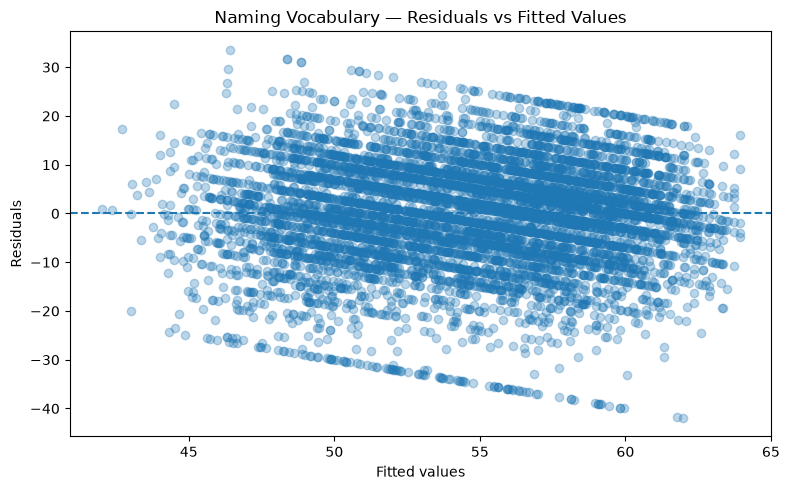

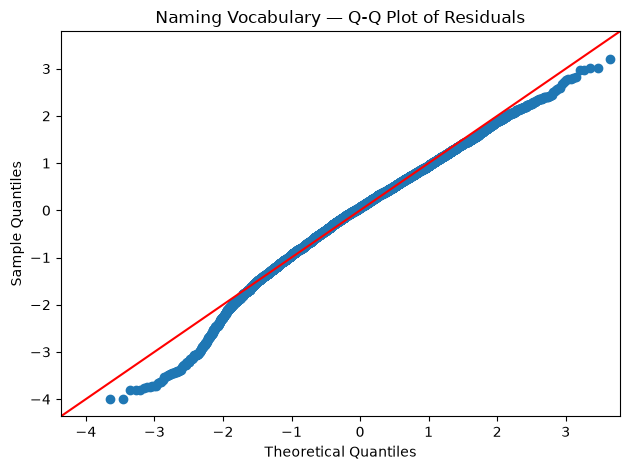

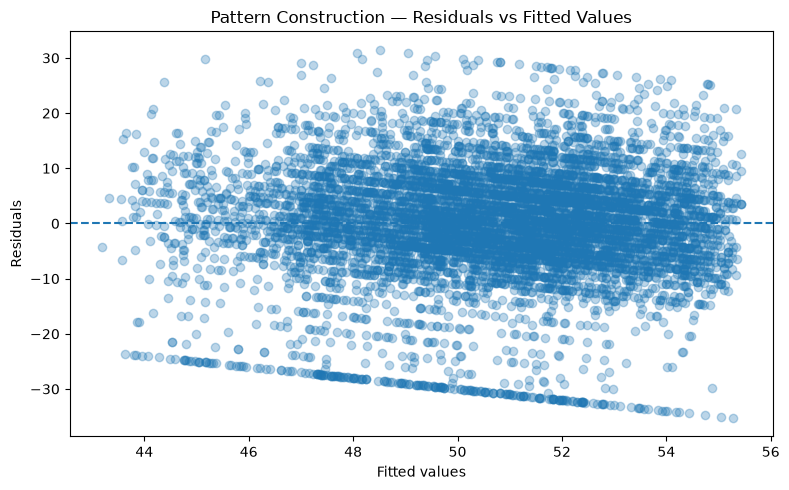

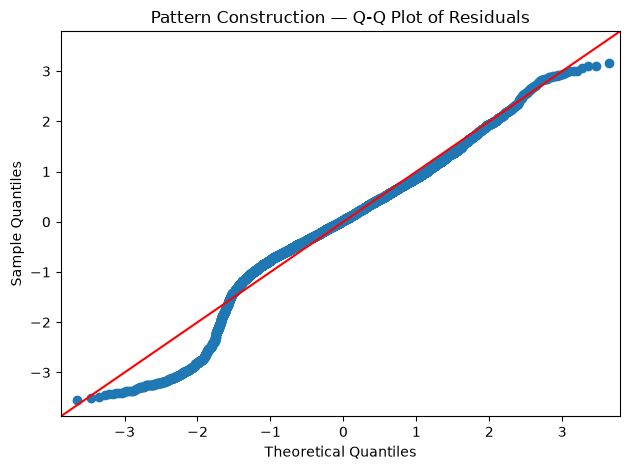

In [87]:
# ============================================================
# RESIDUAL DIAGNOSTICS FOR FINAL REGRESSION MODELS
# ============================================================

import matplotlib.pyplot as plt
import statsmodels.api as sm


# ------------------------------------------------------------
# 1. NAMING VOCABULARY
# ------------------------------------------------------------

vocab_fitted = vocab_final_m3.fittedvalues
vocab_residuals = vocab_final_m3.resid

# Residuals vs fitted
plt.figure(figsize=(8, 5))
plt.scatter(vocab_fitted, vocab_residuals, alpha=0.3)
plt.axhline(0, linestyle="--")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Naming Vocabulary — Residuals vs Fitted Values")
plt.tight_layout()
plt.show()

# Q-Q plot
sm.qqplot(vocab_residuals, line="45", fit=True)
plt.title("Naming Vocabulary — Q-Q Plot of Residuals")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. PATTERN CONSTRUCTION
# ------------------------------------------------------------

pattern_fitted = pattern_final_m3.fittedvalues
pattern_residuals = pattern_final_m3.resid

# Residuals vs fitted
plt.figure(figsize=(8, 5))
plt.scatter(pattern_fitted, pattern_residuals, alpha=0.3)
plt.axhline(0, linestyle="--")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Pattern Construction — Residuals vs Fitted Values")
plt.tight_layout()
plt.show()

# Q-Q plot
sm.qqplot(pattern_residuals, line="45", fit=True)
plt.title("Pattern Construction — Q-Q Plot of Residuals")
plt.tight_layout()
plt.show()

### Interpretation of final regression diagnostics

The diagnostic plots were examined for both final regression models.

#### Residuals versus fitted values

For both Naming Vocabulary and Pattern Construction, residuals were distributed around zero across the range of fitted values. There was no strong visual evidence of a major nonlinear pattern.

However, the residual spread was not perfectly uniform, indicating some departure from the ideal assumption of constant residual variance. The visible banding in the plots is also consistent with the cognitive outcomes taking a limited set of observed score values.

Because the residual variance may not be perfectly constant, HC3 robust standard errors were also examined as a robustness check.

#### Q-Q plots

For both cognitive outcomes, the central portions of the residual distributions followed the theoretical normal line reasonably well, while noticeable departures occurred in the tails.

Therefore, residual normality was approximate rather than perfect.

Given the large analytical sample (N = 7,504), these deviations were not considered sufficient to abandon the linear regression approach. However, they support the decision to interpret the conventional OLS results alongside robustness and sensitivity analyses rather than relying on a single model specification.

#### Overall diagnostic conclusion

The diagnostic plots do not indicate a major model failure, although the assumptions of constant residual variance and normality are not perfectly satisfied.

For this reason, the final results are interpreted together with HC3 robust standard errors, family-cluster robust standard errors, alternative green-space measures, regional adjustment and MCS survey-design sensitivity analyses.

Particular caution is warranted for Pattern Construction because its estimated association is small and conclusions vary across model specifications.

# Step 19 onward — Turn the analysis into dissertation-ready results

The statistical modelling is now largely complete. The remaining cells organise the final analysis sample, descriptive statistics, sample-selection flow and reporting tables.

The dissertation is **not** claiming that “green space makes children smarter.” The analysis asks whether neighbourhood green-space exposure at age 3 is **associated with** later cognitive scores after adjustment for measured socioeconomic and home-learning factors.


# Step 19 — Describe the final primary analysis sample

The final descriptive statistics must come from the exact same **N = 7,504 complete-case sample** used in the primary regressions.

This avoids mixing statistics from larger pre-merge datasets with the actual modelling sample.


In [88]:
# ============================================================
# STEP 19A — FINAL PRIMARY SAMPLE DESCRIPTIVE STATISTICS
# CORRECTED VERSION
# ============================================================

print("=" * 80)
print("FINAL PRIMARY ANALYSIS SAMPLE")
print("=" * 80)

print("N:", len(primary))
print(
    "Unique children:",
    primary[["MCSID", "child_num"]]
    .drop_duplicates()
    .shape[0]
)

# ------------------------------------------------------------
# CONTINUOUS / SCORE VARIABLES
# ------------------------------------------------------------

continuous_vars = [
    "vocabulary_tscore",
    "pattern_tscore",
    "HLE_score",
    "BGREENSP"
]

descriptive_stats = (
    primary[continuous_vars]
    .describe()
    .T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
)

descriptive_stats.columns = [
    "N", "Mean", "SD", "Min", "25%", "Median", "75%", "Max"
]

print("\n" + "=" * 80)
print("CONTINUOUS / SCORE VARIABLES")
print("=" * 80)

display(descriptive_stats.round(2))


# ------------------------------------------------------------
# CHILD SEX
# ------------------------------------------------------------

sex_labels = {
    1.0: "Male",
    2.0: "Female"
}

sex_series = primary["child_sex"].map(sex_labels)

sex_table = pd.DataFrame({
    "N": sex_series.value_counts(),
    "Percent": sex_series
        .value_counts(normalize=True)
        .mul(100)
}).round(1)

print("\n" + "=" * 80)
print("CHILD SEX")
print("=" * 80)

display(sex_table)


# ------------------------------------------------------------
# HOUSEHOLD INCOME
# ------------------------------------------------------------

income_labels = {
    1.0: "Lowest quintile",
    2.0: "Second quintile",
    3.0: "Third quintile",
    4.0: "Fourth quintile",
    5.0: "Highest quintile"
}

income_series = primary["income_quintile"].map(income_labels)

income_table = pd.DataFrame({
    "N": income_series.value_counts(),
    "Percent": income_series
        .value_counts(normalize=True)
        .mul(100)
}).round(1)

# Preserve logical order
income_order = [
    "Lowest quintile",
    "Second quintile",
    "Third quintile",
    "Fourth quintile",
    "Highest quintile"
]

income_table = income_table.reindex(income_order)

print("\n" + "=" * 80)
print("HOUSEHOLD INCOME QUINTILE")
print("=" * 80)

display(income_table)


# ------------------------------------------------------------
# PARENTAL EDUCATION
# ------------------------------------------------------------

education_labels = {
    1.0: "NVQ Level 1",
    2.0: "NVQ Level 2",
    3.0: "NVQ Level 3",
    4.0: "NVQ Level 4",
    5.0: "NVQ Level 5"
}

education_series = primary["parent_education"].map(
    education_labels
)

education_table = pd.DataFrame({
    "N": education_series.value_counts(),
    "Percent": education_series
        .value_counts(normalize=True)
        .mul(100)
}).round(1)

education_order = [
    "NVQ Level 1",
    "NVQ Level 2",
    "NVQ Level 3",
    "NVQ Level 4",
    "NVQ Level 5"
]

education_table = education_table.reindex(
    education_order
)

print("\n" + "=" * 80)
print("PARENTAL EDUCATION")
print("=" * 80)

display(education_table)

FINAL PRIMARY ANALYSIS SAMPLE
N: 7504
Unique children: 7504

CONTINUOUS / SCORE VARIABLES


,N,Mean,SD,Min,25%,Median,75%,Max
vocabulary_tscore,7504.0,54.71,11.29,20.00,48.00,56.00,62.0,80.00
pattern_tscore,7504.0,50.67,10.26,20.00,46.00,51.00,57.0,80.00
HLE_score,7504.0,0.03,0.61,-2.47,-0.39,0.06,0.5,1.04
BGREENSP,7504.0,5.31,2.91,1.00,3.00,5.00,8.0,10.00



CHILD SEX


,N,Percent
child_sex,,
Male,3791,50.5
Female,3713,49.5



HOUSEHOLD INCOME QUINTILE


,N,Percent
income_quintile,,
Lowest quintile,1179,15.7
Second quintile,1468,19.6
Third quintile,1587,21.1
Fourth quintile,1618,21.6
Highest quintile,1652,22.0



PARENTAL EDUCATION


,N,Percent
parent_education,,
NVQ Level 1,744,9.9
NVQ Level 2,2766,36.9
NVQ Level 3,764,10.2
NVQ Level 4,2565,34.2
NVQ Level 5,665,8.9


**Descriptive interpretation:** The final primary sample is balanced by sex and has a broad distribution across income, education and green-space deciles. The HLE mean is close to zero because it is a standardised composite.


In [89]:
# ============================================================
# SAVE VERIFIED FINAL PRIMARY ANALYTICAL SAMPLE
# ============================================================

# 'primary' is the final complete-case analytical sample
# used for the main BGREENSP analyses.
#
# Verified sample:
# N = 7,504 children
# One row per child
# Complete data for the primary analysis variables.

primary.to_pickle("primary_final.pkl")

print("Final primary analytical sample saved.")
print("N =", len(primary))

print(

    "Unique children =",

    primary[["MCSID", "child_num"]]

    .drop_duplicates()

    .shape[0]

)

print(

    "Unique families =",

    primary["MCSID"].nunique()

)

Final primary analytical sample saved.
N = 7504
Unique children = 7504
Unique families = 7410


## Step 19B — Confirm zero missing values in the primary model variables

Because `primary` is a complete-case analysis sample, all variables used in the final primary model should have zero missing values.


In [90]:
# ============================================================
# STEP 19B — FINAL SAMPLE MISSING-DATA CHECK
# ============================================================

final_variables = [
    "child_sex",
    "income_quintile",
    "parent_education",
    "HLE_score",
    "BGREENSP",
    "vocabulary_tscore",
    "pattern_tscore"
]

missing_final = pd.DataFrame({
    "Missing_N": primary[final_variables].isna().sum(),
    "Missing_percent":
        primary[final_variables].isna().mean().mul(100)
})

print("=" * 80)
print("MISSING DATA IN FINAL PRIMARY ANALYSIS SAMPLE")
print("=" * 80)

display(missing_final.round(2))

MISSING DATA IN FINAL PRIMARY ANALYSIS SAMPLE


,Missing_N,Missing_percent
child_sex,0,0.0
income_quintile,0,0.0
parent_education,0,0.0
HLE_score,0,0.0
BGREENSP,0,0.0
vocabulary_tscore,0,0.0
pattern_tscore,0,0.0


# Step 20 — Build Table 1: sample characteristics

Continuous variables are reported as mean (SD) and range; categorical variables are reported as n (%).

This is the basis of the first descriptive table in the dissertation Results chapter.


In [91]:
# ============================================================
# STEP 20 — TABLE 1: PRIMARY SAMPLE CHARACTERISTICS
# ============================================================

table1_rows = [
    # Continuous variables
    ["Naming Vocabulary T-score", "54.71 (11.29)", "20–80"],
    ["Pattern Construction T-score", "50.67 (10.26)", "20–80"],
    ["Home Learning Environment score", "0.03 (0.61)", "-2.47–1.04"],
    ["Neighbourhood green-space decile", "5.31 (2.91)", "1–10"],

    # Child sex
    ["Child sex", "", ""],
    ["  Male", "3,791 (50.5%)", ""],
    ["  Female", "3,713 (49.5%)", ""],

    # Income
    ["Household income quintile", "", ""],
    ["  Lowest quintile", "1,179 (15.7%)", ""],
    ["  Second quintile", "1,468 (19.6%)", ""],
    ["  Third quintile", "1,587 (21.1%)", ""],
    ["  Fourth quintile", "1,618 (21.6%)", ""],
    ["  Highest quintile", "1,652 (22.0%)", ""],

    # Education
    ["Highest parental education", "", ""],
    ["  NVQ Level 1", "744 (9.9%)", ""],
    ["  NVQ Level 2", "2,766 (36.9%)", ""],
    ["  NVQ Level 3", "764 (10.2%)", ""],
    ["  NVQ Level 4", "2,565 (34.2%)", ""],
    ["  NVQ Level 5", "665 (8.9%)", ""],
]

table1 = pd.DataFrame(
    table1_rows,
    columns=[
        "Characteristic",
        "Mean (SD) or n (%)",
        "Range"
    ]
)

print("TABLE 1")
print("Characteristics of the Primary Analysis Sample (N = 7,504)")
display(table1)

TABLE 1
Characteristics of the Primary Analysis Sample (N = 7,504)


,Characteristic,Mean (SD) or n (%),Range
0,Naming Vocabulary T-score,54.71 (11.29),20–80
1,Pattern Construction T-score,50.67 (10.26),20–80
2,Home Learning Environment score,0.03 (0.61),-2.47–1.04
3,Neighbourhood green-space decile,5.31 (2.91),1–10
4,Child sex,,
5,Male,"3,791 (50.5%)",
6,Female,"3,713 (49.5%)",
7,Household income quintile,,
8,Lowest quintile,"1,179 (15.7%)",
9,Second quintile,"1,468 (19.6%)",


# Step 21 — Document how the analytical sample was selected

This traces the sample from the age-3 cohort through age-5 follow-up, HLE/covariate completeness, and finally `BGREENSP` availability.

**Key finding:** The final `BGREENSP` complete-case sample contains 7,504 children (47.58% of the original age-3 child sample). The largest final reduction is due to `BGREENSP` availability.


In [92]:
# ============================================================
# STEP 21 — ANALYTICAL SAMPLE FLOW
# ============================================================

sample_flow = pd.DataFrame({
    "Stage": [
        "Age-3 cohort members",
        "Age-5 cognitive outcomes available",
        "HLE + Age-5 outcomes available",
        "All background + HLE + outcomes available",
        "Final sample with BGREENSP available"
    ],

    "N": [
        15770,
        13931,
        13516,
        11767,
        7504
    ]
})

sample_flow["Retained_from_previous_%"] = (
    sample_flow["N"]
    .div(sample_flow["N"].shift(1))
    .mul(100)
)

sample_flow["Retained_from_initial_%"] = (
    sample_flow["N"]
    .div(sample_flow["N"].iloc[0])
    .mul(100)
)

sample_flow["Lost_at_stage"] = (
    sample_flow["N"].shift(1) - sample_flow["N"]
)

sample_flow.loc[0, "Lost_at_stage"] = 0

print("=" * 90)
print("PRIMARY ANALYSIS — SAMPLE SELECTION FLOW")
print("=" * 90)

display(sample_flow.round(2))

PRIMARY ANALYSIS — SAMPLE SELECTION FLOW


,Stage,N,Retained_from_previous_%,Retained_from_initial_%,Lost_at_stage
0,Age-3 cohort members,15770,NaN,100.00,0.0
1,Age-5 cognitive outcomes available,13931,88.34,88.34,1839.0
2,HLE + Age-5 outcomes available,13516,97.02,85.71,415.0
3,All background + HLE + outcomes available,11767,87.06,74.62,1749.0
4,Final sample with BGREENSP available,7504,63.77,47.58,4263.0


**Sample-flow interpretation:** The primary complete-case analysis uses 7,504 of the 15,770 age-3 children. The biggest final loss comes from the England-only/local `BGREENSP` linkage, which is why selection and the larger `BGRND` sensitivity analysis are important.


# Step 22 — Check selection associated with `BGREENSP` availability

Among children who otherwise have complete outcomes, HLE and background covariates, compare those with versus without linked `BGREENSP`.

**Finding:** Groups are broadly similar on sex, Pattern Construction and HLE, with modest differences in Vocabulary and SES composition. Therefore, potential selection bias should be acknowledged rather than assuming green-space missingness is random.

The much larger `BGRND` sensitivity sample helps address this concern because the Vocabulary association is reproduced there.


In [93]:
# ============================================================
# STEP 22 — BGREENSP SELECTION / MISSINGNESS CHECK
# Compare otherwise-complete children with vs without BGREENSP
# ============================================================

analysis_vars_without_green = [
    "child_sex",
    "income_quintile",
    "parent_education",
    "HLE_score",
    "vocabulary_tscore",
    "pattern_tscore"
]

# Children complete on everything EXCEPT BGREENSP requirement
eligible_before_green = master.dropna(
    subset=analysis_vars_without_green
).copy()

eligible_before_green["BGREENSP_available"] = (
    eligible_before_green["BGREENSP"].notna()
)

print("=" * 85)
print("BGREENSP AVAILABILITY AMONG OTHERWISE-ELIGIBLE CHILDREN")
print("=" * 85)

print("Total eligible before BGREENSP requirement:",
      len(eligible_before_green))

print("\nBGREENSP available:")
print(eligible_before_green["BGREENSP_available"].value_counts())

print("\nPercent:")
print(
    eligible_before_green["BGREENSP_available"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


# ============================================================
# CONTINUOUS VARIABLES
# ============================================================

continuous_compare = [
    "vocabulary_tscore",
    "pattern_tscore",
    "HLE_score"
]

comparison_continuous = (
    eligible_before_green
    .groupby("BGREENSP_available")[continuous_compare]
    .agg(["mean", "std", "count"])
)

print("\n" + "=" * 85)
print("CONTINUOUS VARIABLES")
print("False = BGREENSP unavailable | True = BGREENSP available")
print("=" * 85)

display(comparison_continuous.round(2))


# ============================================================
# CATEGORICAL VARIABLES
# ============================================================

for var in [
    "child_sex",
    "income_quintile",
    "parent_education"
]:

    print("\n" + "=" * 85)
    print(var.upper())
    print("=" * 85)

    tab = pd.crosstab(
        eligible_before_green[var],
        eligible_before_green["BGREENSP_available"],
        normalize="columns"
    ).mul(100)

    display(tab.round(1))

BGREENSP AVAILABILITY AMONG OTHERWISE-ELIGIBLE CHILDREN
Total eligible before BGREENSP requirement: 11767

BGREENSP available:
BGREENSP_available
True     7504
False    4263
Name: count, dtype: int64

Percent:
BGREENSP_available
True     63.77
False    36.23
Name: proportion, dtype: float64

CONTINUOUS VARIABLES
False = BGREENSP unavailable | True = BGREENSP available


vocabulary_tscore              pattern_tscore               \
                                mean    std count           mean    std count   
BGREENSP_available                                                              
False                          55.41  10.89  4263          50.59  10.43  4263   
True                           54.71  11.29  7504          50.67  10.26  7504   

                   HLE_score              
                        mean   std count  
BGREENSP_available                        
False                   0.07  0.60  4263  
True                    0.03  0.61  7504


CHILD_SEX


BGREENSP_available,False,True
child_sex,,
1.0,51.2,50.5
2.0,48.8,49.5



INCOME_QUINTILE


BGREENSP_available,False,True
income_quintile,,
1.0,14.4,15.7
2.0,22.1,19.6
3.0,22.3,21.1
4.0,22.4,21.6
5.0,18.8,22.0



PARENT_EDUCATION


BGREENSP_available,False,True
parent_education,,
1.0,7.3,9.9
2.0,35.5,36.9
3.0,13.6,10.2
4.0,34.6,34.2
5.0,8.9,8.9


**Selection interpretation:** The included and excluded groups are not identical, so the primary sample should not be described as a random subset of the full cohort. However, differences are generally modest, and the Vocabulary finding also appears in the much larger `BGRND` sample.


# Pre-Step 23 — Final Consistency Reruns

## What is the purpose of this step?

Before creating the master results summary, I need to make sure that all of the important regression models use the same final approach to socioeconomic status (SES).

Earlier in the analysis, household income quintile and parental education were initially entered into some models as numerical variables.

Later, I decided that the more appropriate final approach is to treat them as **categorical variables**, because the numbers represent ordered groups rather than assuming that every step between categories has exactly the same effect.

The final primary BGREENSP regression therefore uses:

- child sex as categorical
- household income quintile as categorical
- parental education as categorical
- HLE score as continuous
- green-space decile as continuous

Two sensitivity analyses were originally carried out before this final SES decision:

1. the alternative green-space analysis using `BGRND`
2. the MCS survey-design sensitivity analysis

Therefore, both analyses are rerun here using the final categorical SES specification.

## Why is this important?

This is mainly a **consistency check**.

It allows the primary analysis and sensitivity analyses to use the same SES modelling approach, making the results easier and fairer to compare.

These reruns do not represent new research questions. They are updated versions of analyses that were already performed earlier.

The final results from these reruns will be used in:

**Step 23B — Interim Master Green-Space Results Table**

In [94]:
# ============================================================

# PRE-STEP 23 — PART A

# FINAL BGRND SENSITIVITY ANALYSIS WITH CATEGORICAL SES

# ============================================================

import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm


# ============================================================
# VOCABULARY
# ============================================================

bgrnd_vocab_m1 = smf.ols(
    """
    vocabulary_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education)
    """,
    data=sensitivity
).fit()

bgrnd_vocab_m2 = smf.ols(
    """
    vocabulary_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education) +
    HLE_score
    """,
    data=sensitivity
).fit()

bgrnd_vocab_m3 = smf.ols(
    """
    vocabulary_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education) +
    HLE_score +
    BGRND
    """,
    data=sensitivity
).fit()


print("=" * 80)
print("BGRND SENSITIVITY — VOCABULARY")
print("=" * 80)

print("\nModel 1 R²:", round(bgrnd_vocab_m1.rsquared, 4))

print("Model 2 R²:", round(bgrnd_vocab_m2.rsquared, 4))
print(
    "ΔR² Model 1 → Model 2:",
    round(bgrnd_vocab_m2.rsquared - bgrnd_vocab_m1.rsquared, 4)
)

print("Model 3 R²:", round(bgrnd_vocab_m3.rsquared, 4))
print(
    "ΔR² Model 2 → Model 3:",
    round(bgrnd_vocab_m3.rsquared - bgrnd_vocab_m2.rsquared, 4)
)

print("\nBGRND coefficient:")
print("B:", round(bgrnd_vocab_m3.params["BGRND"], 4))
print("SE:", round(bgrnd_vocab_m3.bse["BGRND"], 4))
print("p:", bgrnd_vocab_m3.pvalues["BGRND"])

ci = bgrnd_vocab_m3.conf_int().loc["BGRND"]

print(
    "95% CI:",
    round(ci.iloc[0], 4),
    "to",
    round(ci.iloc[1], 4)
)

print("\nModel comparison:")
display(
    anova_lm(
        bgrnd_vocab_m1,
        bgrnd_vocab_m2,
        bgrnd_vocab_m3
    )
)


# ============================================================
# PATTERN CONSTRUCTION
# ============================================================

bgrnd_pattern_m1 = smf.ols(
    """
    pattern_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education)
    """,
    data=sensitivity
).fit()

bgrnd_pattern_m2 = smf.ols(
    """
    pattern_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education) +
    HLE_score
    """,
    data=sensitivity
).fit()

bgrnd_pattern_m3 = smf.ols(
    """
    pattern_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education) +
    HLE_score +
    BGRND
    """,
    data=sensitivity
).fit()


print("\n" + "=" * 80)
print("BGRND SENSITIVITY — PATTERN CONSTRUCTION")
print("=" * 80)

print("\nModel 1 R²:", round(bgrnd_pattern_m1.rsquared, 4))

print("Model 2 R²:", round(bgrnd_pattern_m2.rsquared, 4))
print(
    "ΔR² Model 1 → Model 2:",
    round(bgrnd_pattern_m2.rsquared - bgrnd_pattern_m1.rsquared, 4)
)

print("Model 3 R²:", round(bgrnd_pattern_m3.rsquared, 4))
print(
    "ΔR² Model 2 → Model 3:",
    round(bgrnd_pattern_m3.rsquared - bgrnd_pattern_m2.rsquared, 4)
)

print("\nBGRND coefficient:")
print("B:", round(bgrnd_pattern_m3.params["BGRND"], 4))
print("SE:", round(bgrnd_pattern_m3.bse["BGRND"], 4))
print("p:", bgrnd_pattern_m3.pvalues["BGRND"])

ci = bgrnd_pattern_m3.conf_int().loc["BGRND"]

print(
    "95% CI:",
    round(ci.iloc[0], 4),
    "to",
    round(ci.iloc[1], 4)
)

print("\nModel comparison:")
display(
    anova_lm(
        bgrnd_pattern_m1,
        bgrnd_pattern_m2,
        bgrnd_pattern_m3
    )
)

BGRND SENSITIVITY — VOCABULARY

Model 1 R²: 0.0944
Model 2 R²: 0.1062
ΔR² Model 1 → Model 2: 0.0118
Model 3 R²: 0.1167
ΔR² Model 2 → Model 3: 0.0105

BGRND coefficient:
B: 0.4254
SE: 0.036
p: 5.268472743901647e-32
95% CI: 0.3548 to 0.496

Model comparison:


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,11756.0,1.324392e+06,0.0,NaN,NaN,NaN
1,11755.0,1.307178e+06,1.0,17214.285132,156.625644,1.043297e-35
2,11754.0,1.291849e+06,1.0,15328.885228,139.471172,5.268473e-32



BGRND SENSITIVITY — PATTERN CONSTRUCTION

Model 1 R²: 0.0425
Model 2 R²: 0.0448
ΔR² Model 1 → Model 2: 0.0023
Model 3 R²: 0.0448
ΔR² Model 2 → Model 3: 0.0001

BGRND coefficient:
B: 0.0322
SE: 0.0347
p: 0.3525593877480552
95% CI: -0.0357 to 0.1002

Model comparison:


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,11756.0,1.200028e+06,0.0,NaN,NaN,NaN
1,11755.0,1.197180e+06,1.0,2847.664138,27.960623,1.260294e-07
2,11754.0,1.197092e+06,1.0,88.024298,0.864292,3.525594e-01


## Pre-Step 23 — Part A: BGRND Sensitivity Analysis

### What are we analysing here?

The primary green-space variable in this dissertation is `BGREENSP`.

However, I also have another measure of neighbourhood green space called `BGRND`.

`BGRND` is used as an **alternative green-space exposure measure**.

The purpose of this sensitivity analysis is to ask:

> **Do I reach a similar conclusion if I measure neighbourhood green space using BGRND instead of BGREENSP?**

This is useful because a result is more convincing if the overall conclusion does not depend entirely on one particular way of measuring green space.

The BGRND models are rerun here using the final categorical SES specification.

---

### What variables are controlled for?

The models account for:

- child sex
- household income category
- parental education category
- Home Learning Environment (HLE)

BGRND is then added to determine whether it explains additional variation in the age-5 cognitive outcome beyond these factors.

The analysis is performed separately for:

1. Vocabulary
2. Pattern Construction

---

# Vocabulary result

The final BGRND Vocabulary model gives:

- **B = 0.425**
- **SE = 0.036**
- **95% CI = [0.355, 0.496]**
- **p < .001**

Adding BGRND increased the model R² by:

**ΔR² = 0.0105**

This means that BGRND explained approximately an additional **1.05% of variance in Vocabulary scores** after accounting for the background factors and HLE.

### Simple interpretation

Higher neighbourhood green-space scores were associated with higher Vocabulary scores at age 5.

For every one-unit increase in the BGRND green-space decile, Vocabulary T-score was approximately **0.43 points higher on average**, after adjustment for the measured background factors and HLE.

Importantly, this result is very similar to the result obtained using the primary `BGREENSP` measure.

Therefore, the positive Vocabulary association does not appear to depend entirely on which of these two green-space measures is used.

---

# Pattern Construction result

The final BGRND Pattern Construction model gives:

- **B = 0.032**
- **SE = 0.035**
- **95% CI = [-0.036, 0.100]**
- **p = .353**

Adding BGRND increased R² by only:

**ΔR² = 0.0001**

This is an extremely small increase in explained variance.

The confidence interval crosses zero and the p-value is well above .05.

### Simple interpretation

There is **no clear evidence that BGRND is independently associated with Pattern Construction scores** after accounting for SES and HLE.

---

# What did we learn from Part A?

The alternative BGRND measure produces two different conclusions:

**Vocabulary:**  
A clear positive association remains.

**Pattern Construction:**  
No clear association is found.

This supports the emerging pattern in the dissertation that the green-space relationship is considerably more consistent for **Vocabulary** than for **Pattern Construction**.

In [95]:
# ============================================================

# PRE-STEP 23 — PART B

# FINAL MCS SURVEY-DESIGN SENSITIVITY WITH CATEGORICAL SES

# ============================================================

# ============================================================
# VOCABULARY
# ============================================================

survey_vocab_final = smf.wls(
    """
    vocabulary_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education) +
    HLE_score +
    BGREENSP +
    C(pttype2)
    """,
    data=primary_survey,
    weights=primary_survey["covwt2"]
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": primary_survey["sptn00"]
    }
)

print("=" * 80)
print("SURVEY-DESIGN SENSITIVITY — VOCABULARY")
print("=" * 80)

print("B:", round(survey_vocab_final.params["BGREENSP"], 4))
print(
    "Design-adjusted SE:",
    round(survey_vocab_final.bse["BGREENSP"], 4)
)
print("p:", survey_vocab_final.pvalues["BGREENSP"])

ci = survey_vocab_final.conf_int().loc["BGREENSP"]

print(
    "95% CI:",
    round(ci.iloc[0], 4),
    "to",
    round(ci.iloc[1], 4)
)


# ============================================================
# PATTERN CONSTRUCTION
# ============================================================

survey_pattern_final = smf.wls(
    """
    pattern_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education) +
    HLE_score +
    BGREENSP +
    C(pttype2)
    """,
    data=primary_survey,
    weights=primary_survey["covwt2"]
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": primary_survey["sptn00"]
    }
)

print("\n" + "=" * 80)
print("SURVEY-DESIGN SENSITIVITY — PATTERN CONSTRUCTION")
print("=" * 80)

print("B:", round(survey_pattern_final.params["BGREENSP"], 4))
print(
    "Design-adjusted SE:",
    round(survey_pattern_final.bse["BGREENSP"], 4)
)
print("p:", survey_pattern_final.pvalues["BGREENSP"])

ci = survey_pattern_final.conf_int().loc["BGREENSP"]

print(
    "95% CI:",
    round(ci.iloc[0], 4),
    "to",
    round(ci.iloc[1], 4)
)

SURVEY-DESIGN SENSITIVITY — VOCABULARY
B: 0.1903
Design-adjusted SE: 0.0586
p: 0.0011610812855032352
95% CI: 0.0755 to 0.3052

SURVEY-DESIGN SENSITIVITY — PATTERN CONSTRUCTION
B: -0.0306
Design-adjusted SE: 0.062
p: 0.6210574446488317
95% CI: -0.1521 to 0.0908


## Pre-Step 23 — Part B: MCS Survey-Design Sensitivity Analysis

### Why are we doing this analysis?

The Millennium Cohort Study (MCS) was not collected using a simple random sample of UK children.

It used a **complex survey sampling design**.

Therefore, as an additional sensitivity check, I examine whether the green-space findings remain when information about the MCS sampling design is incorporated.

This analysis uses:

- `covwt2` — the MCS Sweep 3 whole-UK survey weight
- `pttype2` — sampling stratum
- `sptn00` — fieldwork point / PSU used for clustering

The model also uses the final categorical SES specification so that it is consistent with the primary analysis.

---

## What question are we asking?

The question is:

> **Does the BGREENSP association remain when the MCS survey sampling design is taken into account?**

This is a sensitivity analysis rather than a different research question.

---

# Vocabulary result

The survey-design sensitivity model gives:

- **B = 0.190**
- **SE = 0.059**
- **95% CI = [0.076, 0.305]**
- **p = .001**

For comparison, the primary unweighted model gives approximately:

**B = 0.428**

### What does this mean?

After incorporating the MCS survey design, the estimated green-space coefficient becomes smaller.

However, the association remains:

- positive
- statistically supported
- with a confidence interval above zero

### Simple interpretation

The positive relationship between neighbourhood green space and Vocabulary remains when the MCS survey design is taken into account.

However, the estimated size of the association is smaller than in the primary model.

This tells me that I should be cautious about claiming a precise effect size.

The important finding is that the **positive direction of the Vocabulary association remains**, rather than assuming that B = 0.428 is the only possible estimate.

---

# Pattern Construction result

The survey-design sensitivity model gives:

- **B = -0.031**
- **SE = 0.062**
- **95% CI = [-0.152, 0.091]**
- **p = .621**

The coefficient is close to zero and the confidence interval crosses zero.

### Simple interpretation

There is **no evidence of an independent association between neighbourhood green space and Pattern Construction** after incorporating the MCS survey design.

This makes the very small borderline result found in the primary model less convincing.

---

# What did we learn from Part B?

The survey-design analysis again shows an important difference between the two cognitive outcomes.

### Vocabulary

The coefficient becomes smaller, but the association remains positive and statistically supported.

### Pattern Construction

There is no evidence of an association after accounting for the survey design.

Therefore, the Vocabulary result appears considerably more robust than the Pattern Construction result.

---

## Important interpretation note

The survey-design sensitivity analysis does not mean that the original primary regression was "wrong".

Instead, it asks whether the conclusion changes when the complex MCS sampling design is taken into account.

For Vocabulary, the exact estimated magnitude changes, but the overall positive association remains.

For Pattern Construction, the evidence does not remain consistent.

These results are carried forward into the interim summary in Step 23 and the final synthesis in Step 25.

# Step 23 — Recalculate robust inference using the final categorical-SES model

Earlier HC3/family-cluster checks used the preliminary numeric-SES specification. This cell repeats them using the final categorical-SES model so the robustness results are consistent with the chosen primary specification.

**Finding:** Vocabulary remains very stable. Pattern Construction remains tiny and sensitive to specification.


In [96]:
# ============================================================
# STEP 23A — ROBUST VERSIONS OF FINAL CATEGORICAL-SES MODELS
# ============================================================

# HC3 robust standard errors
vocab_final_hc3 = vocab_final_m3.get_robustcov_results(
    cov_type="HC3"
)

pattern_final_hc3 = pattern_final_m3.get_robustcov_results(
    cov_type="HC3"
)


# Family-cluster robust standard errors
vocab_final_cluster = vocab_final_m3.get_robustcov_results(
    cov_type="cluster",
    groups=primary["MCSID"]
)

pattern_final_cluster = pattern_final_m3.get_robustcov_results(
    cov_type="cluster",
    groups=primary["MCSID"]
)


# Helper function because robust results store coefficients as arrays
def robust_result(model, variable):

    position = model.model.exog_names.index(variable)

    ci = model.conf_int()[position]

    return {
        "B": model.params[position],
        "SE": model.bse[position],
        "p": model.pvalues[position],
        "CI_low": ci[0],
        "CI_high": ci[1]
    }


print("=" * 75)
print("FINAL CATEGORICAL-SES MODEL — ROBUSTNESS CHECK")
print("=" * 75)

for outcome, hc3, cluster in [
    ("Vocabulary", vocab_final_hc3, vocab_final_cluster),
    ("Pattern Construction", pattern_final_hc3, pattern_final_cluster)
]:

    print("\n", outcome.upper())

    h = robust_result(hc3, "BGREENSP")
    c = robust_result(cluster, "BGREENSP")

    print("\nHC3")
    print("B:", round(h["B"], 4))
    print("SE:", round(h["SE"], 4))
    print("p:", h["p"])
    print(
        "95% CI:",
        [round(h["CI_low"], 4), round(h["CI_high"], 4)]
    )

    print("\nFamily-cluster robust")
    print("B:", round(c["B"], 4))
    print("SE:", round(c["SE"], 4))
    print("p:", c["p"])
    print(
        "95% CI:",
        [round(c["CI_low"], 4), round(c["CI_high"], 4)]
    )

FINAL CATEGORICAL-SES MODEL — ROBUSTNESS CHECK

 VOCABULARY

HC3
B: 0.428
SE: 0.042
p: 2.895309452840714e-24
95% CI: [np.float64(0.3457), np.float64(0.5102)]

Family-cluster robust
B: 0.428
SE: 0.0422
p: 5.6442607777258575e-24
95% CI: [np.float64(0.3452), np.float64(0.5108)]

 PATTERN CONSTRUCTION

HC3
B: 0.0778
SE: 0.0391
p: 0.04671001125789431
95% CI: [np.float64(0.0011), np.float64(0.1544)]

Family-cluster robust
B: 0.0778
SE: 0.0393
p: 0.0478233759851792
95% CI: [np.float64(0.0007), np.float64(0.1548)]


### Step 23A — What are we checking?

The final primary regression now treats household income and parental education as **categorical SES variables**.

This step repeats two robustness checks using that final model specification:

1. **HC3 robust standard errors**
2. **Family-cluster robust standard errors**

These checks do **not change the regression coefficient itself**. They change how uncertainty around the coefficient is estimated.

---

## Why use HC3 robust standard errors?

Ordinary regression assumes that the variability of the residuals is reasonably constant across observations.

The earlier residual plots showed some departures from this assumption.

HC3 provides more robust estimates of:

- standard errors
- confidence intervals
- p-values

if unequal residual variance is present.

---

## Why use family-cluster robust standard errors?

A small number of MCS families contain more than one cohort child, for example twins.

Children from the same family may be more similar to each other than unrelated children because they share:

- household background
- parents
- neighbourhood
- aspects of the home environment

Family-cluster robust standard errors allow observations from the same `MCSID` to be correlated.

Only a small proportion of the primary sample came from multi-child families, but this check makes the analysis more robust.

---

## Vocabulary result

Both robustness checks produce almost exactly the same result:

- **B = 0.428**
- HC3: **p < .001**
- Family-cluster robust: **p < .001**

The confidence intervals are also almost identical to the primary model.

### Simple interpretation

The positive association between neighbourhood green space and Vocabulary is **not explained by unequal residual variance or by the small amount of within-family clustering**.

The Vocabulary finding is therefore highly stable under these checks.

---

## Pattern Construction result

The coefficient remains very small:

- **B = 0.078**

The p-values are:

- HC3: **p = .047**
- Family-cluster robust: **p = .048**

These values are just below the conventional .05 threshold.

However, this should **not** be interpreted as strong evidence of an effect.

The estimated association is extremely small and later sensitivity analyses using:

- an alternative green-space measure, and
- the MCS survey-design adjustment

do not support a consistent Pattern Construction association.

### Simple interpretation

Pattern Construction remains a **small and fragile finding**, whereas the Vocabulary result is much more stable.


## INTERIM MASTER GREEN-SPACE RESULTS BEFORE GEOGRAPHICAL ROBUSTNESS CHECKS

In [97]:
# ============================================================
# # STEP 23B — INTERIM MASTER GREEN-SPACE RESULTS TABLE
# ============================================================

import pandas as pd

master_results = pd.DataFrame([

    # ========================================================
    # VOCABULARY
    # ========================================================

    {
        "Outcome": "Vocabulary",
        "Analysis": "Primary: BGREENSP + categorical SES",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.4280,
        "SE": 0.0419,
        "CI_low": 0.3458,
        "CI_high": 0.5102,
        "p": 2.6727066387531676e-24
    },

    {
        "Outcome": "Vocabulary",
        "Analysis": "HC3 robust SE",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.4280,
        "SE": 0.0420,
        "CI_low": 0.3457,
        "CI_high": 0.5102,
        "p": 2.895309452840714e-24
    },

    {
        "Outcome": "Vocabulary",
        "Analysis": "Family-cluster robust SE",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.4280,
        "SE": 0.0422,
        "CI_low": 0.3452,
        "CI_high": 0.5108,
        "p": 5.6442607777258575e-24
    },

    {
        "Outcome": "Vocabulary",
        "Analysis": "Alternative green-space measure",
        "Exposure": "BGRND",
        "N": 11766,
        "B": 0.4254,
        "SE": 0.0360,
        "CI_low": 0.3548,
        "CI_high": 0.4960,
        "p": 5.268472743901647e-32
    },

    {
        "Outcome": "Vocabulary",
        "Analysis": "MCS survey-design sensitivity",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.1903,
        "SE": 0.0586,
        "CI_low": 0.0755,
        "CI_high": 0.3052,
        "p": 0.0011610812855032352
    },


    # ========================================================
    # PATTERN CONSTRUCTION
    # ========================================================

    {
        "Outcome": "Pattern Construction",
        "Analysis": "Primary: BGREENSP + categorical SES",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.0778,
        "SE": 0.0399,
        "CI_low": -0.0004,
        "CI_high": 0.1560,
        "p": 0.05121135666327061
    },

    {
        "Outcome": "Pattern Construction",
        "Analysis": "HC3 robust SE",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.0778,
        "SE": 0.0391,
        "CI_low": 0.0011,
        "CI_high": 0.1544,
        "p": 0.04671001125789431
    },

    {
        "Outcome": "Pattern Construction",
        "Analysis": "Family-cluster robust SE",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.0778,
        "SE": 0.0393,
        "CI_low": 0.0007,
        "CI_high": 0.1548,
        "p": 0.0478233759851792
    },

    {
        "Outcome": "Pattern Construction",
        "Analysis": "Alternative green-space measure",
        "Exposure": "BGRND",
        "N": 11766,
        "B": 0.0322,
        "SE": 0.0347,
        "CI_low": -0.0357,
        "CI_high": 0.1002,
        "p": 0.3525593877480552
    },

    {
        "Outcome": "Pattern Construction",
        "Analysis": "MCS survey-design sensitivity",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": -0.0306,
        "SE": 0.0620,
        "CI_low": -0.1521,
        "CI_high": 0.0908,
        "p": 0.6210574446488317
    }
])


# ------------------------------------------------------------
# CREATE CLEAN DISPLAY VERSION
# ------------------------------------------------------------

report_master = master_results.copy()

report_master["B"] = report_master["B"].map(
    lambda x: f"{x:.3f}"
)

report_master["SE"] = report_master["SE"].map(
    lambda x: f"{x:.3f}"
)

report_master["95% CI"] = master_results.apply(
    lambda r: f"[{r['CI_low']:.3f}, {r['CI_high']:.3f}]",
    axis=1
)

report_master["p"] = master_results["p"].map(
    lambda x: "< .001" if x < .001 else f"{x:.3f}"
)

report_master = report_master[
    [
        "Outcome",
        "Analysis",
        "Exposure",
        "N",
        "B",
        "SE",
        "95% CI",
        "p"
    ]
]


# ------------------------------------------------------------
# DISPLAY FINAL TABLE
# ------------------------------------------------------------

print("=" * 110)
print("INTERIM MASTER GREEN-SPACE RESULTS BEFORE GEOGRAPHICAL ROBUSTNESS CHECKS")
print("=" * 110)

display(report_master)

INTERIM MASTER GREEN-SPACE RESULTS BEFORE GEOGRAPHICAL ROBUSTNESS CHECKS


,Outcome,Analysis,Exposure,N,B,SE,95% CI,p
0,Vocabulary,Primary: BGREENSP + categorical SES,BGREENSP,7504,0.428,0.042,"[0.346, 0.510]",< .001
1,Vocabulary,HC3 robust SE,BGREENSP,7504,0.428,0.042,"[0.346, 0.510]",< .001
2,Vocabulary,Family-cluster robust SE,BGREENSP,7504,0.428,0.042,"[0.345, 0.511]",< .001
3,Vocabulary,Alternative green-space measure,BGRND,11766,0.425,0.036,"[0.355, 0.496]",< .001
4,Vocabulary,MCS survey-design sensitivity,BGREENSP,7504,0.190,0.059,"[0.075, 0.305]",0.001
5,Pattern Construction,Primary: BGREENSP + categorical SES,BGREENSP,7504,0.078,0.040,"[-0.000, 0.156]",0.051
6,Pattern Construction,HC3 robust SE,BGREENSP,7504,0.078,0.039,"[0.001, 0.154]",0.047
7,Pattern Construction,Family-cluster robust SE,BGREENSP,7504,0.078,0.039,"[0.001, 0.155]",0.048
8,Pattern Construction,Alternative green-space measure,BGRND,11766,0.032,0.035,"[-0.036, 0.100]",0.353
9,Pattern Construction,MCS survey-design sensitivity,BGREENSP,7504,-0.031,0.062,"[-0.152, 0.091]",0.621


> **Important notebook note:** This is an interim summary of the analyses completed before the geographical robustness checks. Additional analyses in Step 24 showed that the Vocabulary estimate was attenuated after adjustment for region and survey design. Therefore, Step 25 should be used for the final overall interpretation.
### Step 23B — Interpretation of the interim master green-space results
## What are we doing in this step?

This table brings together the **final primary analysis and the main sensitivity/robustness checks**.

The aim is to answer:

> **Does the association between neighbourhood green space at age 3 and cognitive performance at age 5 remain similar when the analysis is carried out in different reasonable ways?**

All of the key analyses now use the final approach where:

- child sex is categorical
- household income is categorical
- parental education is categorical
- HLE is included as a continuous score

The two cognitive outcomes are analysed separately:

- **Vocabulary** = verbal/language cognition
- **Pattern Construction** = non-verbal/spatial cognition

`BGREENSP` is the primary neighbourhood green-space exposure.

`BGRND` is the alternative green-space measure used as a sensitivity analysis.

---

# 1. Vocabulary

## Primary model

The final primary model gives:

- **B = 0.428**
- **SE = 0.042**
- **95% CI = [0.346, 0.510]**
- **p < .001**

After controlling for:

- child sex
- household income
- parental education
- Home Learning Environment

each one-decile increase in neighbourhood green space is associated with approximately **0.43 points higher Vocabulary T-score at age 5**.

For example, a five-decile difference corresponds to approximately:

`5 × 0.428 = 2.14 Vocabulary T-score points`

This is an **association**, not evidence that green space directly causes higher Vocabulary scores.

---

## HC3 robust standard errors

The result remains:

- **B = 0.428**
- **p < .001**

The estimate and confidence interval are almost unchanged.

### Meaning

The Vocabulary result does not depend on the ordinary OLS assumption of perfectly equal residual variance.

---

## Family-cluster robust standard errors

Again:

- **B = 0.428**
- **p < .001**

### Meaning

Allowing observations from the same family to be correlated does not materially change the result.

Therefore, twins or other multiple cohort children are not driving the Vocabulary association.

---

## Alternative green-space measure — BGRND

The final categorical-SES BGRND sensitivity analysis uses a larger sample:

**N = 11,766**

The result is:

- **B = 0.425**
- **95% CI = [0.355, 0.496]**
- **p < .001**

### Meaning

The Vocabulary association appears again using a different measure of neighbourhood green space and a substantially larger analytical sample.

This is important because it shows that the Vocabulary finding is **not dependent only on BGREENSP or on the smaller BGREENSP complete-case sample**.

---

## MCS survey-design sensitivity analysis

After incorporating:

- the MCS3 whole-UK survey weight
- sampling strata
- clustering by PSU

the result is:

- **B = 0.190**
- **95% CI = [0.076, 0.305]**
- **p = .001**

### Meaning

The estimated association becomes smaller after accounting for the MCS survey design.

However, it remains:

- positive
- statistically supported
- clearly above zero

Therefore, the **the Vocabulary association remains positive in the analyses completed at this stage, although its estimated size is reduced**, but the exact size of the association should be interpreted cautiously.

---

## Overall Vocabulary conclusion

Greater neighbourhood green-space exposure at age 3 is consistently associated with higher Vocabulary scores at age 5.

The association remains positive across:

- the primary model
- HC3 robust inference
- family-cluster robust inference
- the alternative BGRND exposure
- the MCS survey-design sensitivity analysis

The estimated effect size becomes smaller in the survey-design analysis, so the magnitude should not be overstated.

Overall, the evidence for the Vocabulary association is **rOverall, the Vocabulary association is relatively consistent across the analyses completed at this stage.**.

---

# 2. Pattern Construction

## Primary model

The primary result is:

- **B = 0.078**
- **SE = 0.040**
- **95% CI approximately [-0.000, 0.156]**
- **p = .051**

The estimated association is very small and the p-value is just above the conventional .05 threshold.

### Meaning

The primary model does **not provide clear evidence** of an independent association between green space and Pattern Construction.

---

## HC3 and family-cluster robust standard errors

The coefficient remains:

**B = 0.078**

but the p-values become:

- HC3: **p = .047**
- Family-cluster: **p = .048**

These are just below .05.

However, this should not be interpreted as strong evidence simply because the values cross the .05 threshold.

The estimated association remains extremely small and is very close to the statistical-significance boundary.

---

## Alternative green-space measure — BGRND

The final categorical-SES BGRND sensitivity result is:

- **B = 0.032**
- **95% CI = [-0.036, 0.100]**
- **p = .353**

### Meaning

There is no evidence of an independent association between the alternative green-space measure and Pattern Construction.

---

## MCS survey-design sensitivity analysis

The result is:

- **B = -0.031**
- **95% CI = [-0.152, 0.091]**
- **p = .621**

### Meaning

After incorporating the MCS sampling design, the estimate is close to zero and slightly negative.

There is clearly no evidence of an association.

---

## Overall Pattern Construction conclusion

Evidence for an association between green space and Pattern Construction is **weak and inconsistent**.

Although the HC3 and family-cluster versions produce p-values just below .05:

- the effect is extremely small
- the primary model is borderline
- the alternative BGRND analysis is non-significant
- the survey-design analysis is clearly non-significant

Therefore, the overall evidence does **not support a robust independent association between neighbourhood green space and Pattern Construction**.

---

# Overall interpretation

The analyses show a clear difference between the two cognitive outcomes.

### Vocabulary

🌳 Greater neighbourhood green space at age 3  
↓  
🗣️ Higher Vocabulary scores at age 5

The association is positive and relatively consistent across the different modelling approaches.

### Pattern Construction

🌳 Neighbourhood green space at age 3  
↓  
🧩 Pattern Construction at age 5

The estimated association is very small and does not remain consistent across sensitivity analyses.

---

## Overall conclusion

The findings suggest that the relationship between early neighbourhood green-space exposure and later cognitive development may differ according to the cognitive domain being measured.

The evidence is much stronger for **verbal/language cognition (Vocabulary)** than for **non-verbal/spatial cognition (Pattern Construction)**.

These analyses are observational.

They demonstrate statistical **associations** and should not be interpreted as showing that green-space exposure directly causes improvements in children's cognitive development.
> **Notebook note:** This was the master summary before the additional geographical robustness analyses in Step 24. Step 25 contains the final synthesis and should be used for the final interpretation of the study.

# Step 24 — Geographic robustness check

## Why am I doing this?

The primary regression already accounts for:

- child sex
- household income
- parental education
- Home Learning Environment (HLE)

However, children living in different geographical regions may differ in ways that are not completely captured by these variables.

For example, regions may differ in:

- the amount and type of green space
- population density
- environmental conditions
- housing and neighbourhood characteristics
- other social and geographical factors

This creates an additional question:

> **Does the association between neighbourhood green space and cognitive outcomes remain after also accounting for broad geographical region?**

To investigate this, I use the Sweep-2 Government Office Region variable (`BAREGN00`) because it was measured at the same sweep as the main green-space exposure.

Region is treated as a **categorical variable**.

### Important

This is a **robustness check**, not a replacement for the primary model.

The primary model remains the main analysis.

The purpose of this additional model is simply to see whether controlling for broad geographical location substantially changes the BGREENSP result.

### What will I look for?

I will compare the BGREENSP coefficient before and after adding region.

If the coefficient remains reasonably similar, this suggests that broad regional differences do not explain the main association.

If the coefficient becomes substantially smaller or changes direction, this would suggest that geography may account for part of the association and should be discussed as an important limitation.

In [98]:
# ============================================================
# STEP 24A — CHECK SWEEP-2 REGION VARIABLE
# ============================================================

print("=" * 75)
print("SWEEP-2 REGION VARIABLE CHECK")
print("=" * 75)

print("BAREGN00 available:", "BAREGN00" in income.columns)

if "BAREGN00" in income.columns:
    
    print("\nVariable label:")
    
    # Find the variable label from the SPSS metadata
    region_position = income_meta.column_names.index("BAREGN00")
    print(income_meta.column_labels[region_position])
    
    print("\nRaw distribution:")
    print(
        income["BAREGN00"]
        .value_counts(dropna=False)
        .sort_index()
    )
    
    print("\nValue labels:")
    print(
        income_meta.variable_value_labels.get(
            "BAREGN00",
            "No value labels found"
        )
    )

SWEEP-2 REGION VARIABLE CHECK
BAREGN00 available: True

Variable label:
Interview Government Office Region

Raw distribution:
BAREGN00
1.0      459
2.0     1293
3.0     1158
4.0      815
5.0     1181
6.0     1065
7.0     1783
8.0     1504
9.0      816
10.0    2235
11.0    1800
12.0    1460
13.0       1
Name: count, dtype: int64

Value labels:
{1.0: 'North East', 2.0: 'North West', 3.0: 'Yorkshire and the Humber', 4.0: 'East Midlands', 5.0: 'West Midlands', 6.0: 'East of England', 7.0: 'London', 8.0: 'South East', 9.0: 'South West', 10.0: 'Wales', 11.0: 'Scotland', 12.0: 'Northern Ireland', 13.0: 'Not app in IoM Ch Is'}


## Step 24B — Add geographical region to the primary analysis sample

### What am I doing?

Step 24A confirmed that `BAREGN00` records the child's Government Office Region at Sweep 2.

The variable contains the nine English regions as well as Wales, Scotland and Northern Ireland.

Before adding region to the regression, I first need to check which regions are actually represented in the final BGREENSP primary sample of 7,504 children.

This is important because the availability of the linked BGREENSP measure may be geographically restricted.

### What will I check?

I will:

1. attach `BAREGN00` to the existing primary analysis sample using `MCSID`;
2. confirm that the sample size remains 7,504;
3. check whether any region information is missing; and
4. examine which regions are represented in the primary sample.

This step does not change the regression model yet. It is only a data and geographical-coverage check.

In [99]:
# ============================================================
# STEP 24B — ADD REGION TO PRIMARY ANALYSIS SAMPLE
# ============================================================

# Keep only family ID and Sweep-2 region
region_data = income[["MCSID", "BAREGN00"]].copy()

# Make sure there is only one row per family
region_data = region_data.drop_duplicates(subset="MCSID")

# Attach region to the existing primary analysis sample
primary_region = primary.merge(
    region_data,
    on="MCSID",
    how="left"
)

print("=" * 75)
print("REGION IN PRIMARY BGREENSP SAMPLE")
print("=" * 75)

print("\nOriginal primary sample:")
print(len(primary))

print("\nSample after adding region:")
print(len(primary_region))

print("\nMissing region values:")
print(primary_region["BAREGN00"].isna().sum())

print("\nRegion distribution:")
print(
    primary_region["BAREGN00"]
    .value_counts(dropna=False)
    .sort_index()
)

# Add readable region labels
region_labels = {
    1.0: "North East",
    2.0: "North West",
    3.0: "Yorkshire and the Humber",
    4.0: "East Midlands",
    5.0: "West Midlands",
    6.0: "East of England",
    7.0: "London",
    8.0: "South East",
    9.0: "South West",
    10.0: "Wales",
    11.0: "Scotland",
    12.0: "Northern Ireland",
    13.0: "Not applicable"
}

primary_region["region_label"] = (
    primary_region["BAREGN00"]
    .map(region_labels)
)

print("\nRegion distribution with labels:")
print(
    primary_region["region_label"]
    .value_counts(dropna=False)
)

REGION IN PRIMARY BGREENSP SAMPLE

Original primary sample:
7504

Sample after adding region:
7504

Missing region values:
0

Region distribution:
BAREGN00
1.0     337
2.0     944
3.0     832
4.0     641
5.0     789
6.0     856
7.0    1165
8.0    1252
9.0     688
Name: count, dtype: int64

Region distribution with labels:
region_label
South East                  1252
London                      1165
North West                   944
East of England              856
Yorkshire and the Humber     832
West Midlands                789
South West                   688
East Midlands                641
North East                   337
Name: count, dtype: int64


### Step 24B — Interpretation

The primary BGREENSP analysis sample remained unchanged after adding the Sweep-2 region variable:

- Original primary sample: **7,504**
- Sample after adding region: **7,504**
- Missing region information: **0**

All children in the primary BGREENSP sample were located within the **nine English Government Office Regions**.

There were no children from Wales, Scotland or Northern Ireland in this sample.

This confirms that the primary BGREENSP analysis is geographically restricted to **England**, rather than representing the full UK MCS cohort.

This is important for two reasons.

First, the main findings should be interpreted as applying most directly to the English BGREENSP-linked sample rather than automatically generalising to all UK children.

Second, different English regions may differ in both green-space availability and other environmental or social characteristics.

Therefore, the next robustness check will add **region as a categorical control variable** to test whether the estimated BGREENSP association remains after accounting for broad regional differences.

## Step 24C — Region-adjusted robustness analysis

### Why am I doing this?

The previous step confirmed that the primary BGREENSP sample contains children from the nine English regions.

Different regions of England may differ in many ways, including:

- green-space availability
- urbanisation
- housing and neighbourhood characteristics
- environmental conditions
- social and economic context

Some of these regional differences could potentially be related to children's cognitive outcomes.

Therefore, I now repeat the final regression while additionally controlling for **Government Office Region**.

Region is treated as a categorical variable.

### Main question

> **Does the estimated association between BGREENSP and cognitive performance remain after accounting for broad geographical region?**

This is a robustness check rather than a replacement for the primary model.

I will compare the BGREENSP coefficient from the original final model with the coefficient from the region-adjusted model.

The most important question is whether the **size and direction of the coefficient change substantially**, rather than simply whether the p-value is above or below .05.

In [100]:
# ============================================================
# STEP 24C — REGION-ADJUSTED ROBUSTNESS ANALYSIS
# ============================================================

import statsmodels.formula.api as smf

# ------------------------------------------------------------
# VOCABULARY
# ------------------------------------------------------------

vocab_region_model = smf.ols(
    """
    vocabulary_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education) +
    HLE_score +
    C(BAREGN00) +
    BGREENSP
    """,
    data=primary_region
).fit()


# ------------------------------------------------------------
# PATTERN CONSTRUCTION
# ------------------------------------------------------------

pattern_region_model = smf.ols(
    """
    pattern_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education) +
    HLE_score +
    C(BAREGN00) +
    BGREENSP
    """,
    data=primary_region
).fit()


# ------------------------------------------------------------
# HELPER FUNCTION
# ------------------------------------------------------------

def extract_result(model, variable):

    ci = model.conf_int().loc[variable]

    return {
        "B": model.params[variable],
        "SE": model.bse[variable],
        "p": model.pvalues[variable],
        "CI_low": ci.iloc[0],
        "CI_high": ci.iloc[1]
    }


# Extract BGREENSP results
vocab_region_result = extract_result(
    vocab_region_model,
    "BGREENSP"
)

pattern_region_result = extract_result(
    pattern_region_model,
    "BGREENSP"
)


# ------------------------------------------------------------
# PRINT RESULTS
# ------------------------------------------------------------

print("=" * 75)
print("REGION-ADJUSTED ROBUSTNESS CHECK")
print("=" * 75)


print("\nVOCABULARY")
print("-" * 40)

print("N:", int(vocab_region_model.nobs))
print("R²:", round(vocab_region_model.rsquared, 4))

print("\nBGREENSP coefficient:")
print("B:", round(vocab_region_result["B"], 4))
print("SE:", round(vocab_region_result["SE"], 4))
print("p:", vocab_region_result["p"])
print(
    "95% CI:",
    [
        round(vocab_region_result["CI_low"], 4),
        round(vocab_region_result["CI_high"], 4)
    ]
)


print("\n" + "=" * 75)

print("\nPATTERN CONSTRUCTION")
print("-" * 40)

print("N:", int(pattern_region_model.nobs))
print("R²:", round(pattern_region_model.rsquared, 4))

print("\nBGREENSP coefficient:")
print("B:", round(pattern_region_result["B"], 4))
print("SE:", round(pattern_region_result["SE"], 4))
print("p:", pattern_region_result["p"])
print(
    "95% CI:",
    [
        round(pattern_region_result["CI_low"], 4),
        round(pattern_region_result["CI_high"], 4)
    ]
)


# ------------------------------------------------------------
# COMPARE WITH ORIGINAL FINAL PRIMARY MODEL
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("COMPARISON WITH FINAL PRIMARY MODEL")
print("=" * 75)

print("\nVOCABULARY")
print("Primary B:          ", round(vocab_final_m3.params["BGREENSP"], 4))
print("Region-adjusted B:  ", round(vocab_region_result["B"], 4))

vocab_change = (
    (vocab_region_result["B"] -
     vocab_final_m3.params["BGREENSP"])
    / vocab_final_m3.params["BGREENSP"]
) * 100

print(
    "Change in B:       ",
    round(vocab_change, 1),
    "%"
)


print("\nPATTERN CONSTRUCTION")
print("Primary B:          ", round(pattern_final_m3.params["BGREENSP"], 4))
print("Region-adjusted B:  ", round(pattern_region_result["B"], 4))

pattern_change = (
    (pattern_region_result["B"] -
     pattern_final_m3.params["BGREENSP"])
    / pattern_final_m3.params["BGREENSP"]
) * 100

print(
    "Change in B:       ",
    round(pattern_change, 1),
    "%"
)

REGION-ADJUSTED ROBUSTNESS CHECK

VOCABULARY
----------------------------------------
N: 7504
R²: 0.1494

BGREENSP coefficient:
B: 0.2795
SE: 0.0452
p: 6.596970486056552e-10
95% CI: [np.float64(0.1909), np.float64(0.3681)]


PATTERN CONSTRUCTION
----------------------------------------
N: 7504
R²: 0.0588

BGREENSP coefficient:
B: 0.0857
SE: 0.0432
p: 0.04736335621263589
95% CI: [np.float64(0.001), np.float64(0.1703)]

COMPARISON WITH FINAL PRIMARY MODEL

VOCABULARY
Primary B:           0.428
Region-adjusted B:   0.2795
Change in B:        -34.7 %

PATTERN CONSTRUCTION
Primary B:           0.0778
Region-adjusted B:   0.0857
Change in B:        10.1 %


### Step 24C — Interpretation

## What happened when region was added?

This robustness check asked whether the association between neighbourhood green space and cognitive outcomes could partly reflect differences between geographical regions of England.

The models now control for:

- child sex
- household income
- parental education
- Home Learning Environment (HLE)
- Government Office Region
- neighbourhood green space (BGREENSP)

The same 7,504 children were included, so differences between the primary and region-adjusted results are not caused by a change in sample size.


## 1. Vocabulary

### Primary model

The original final model gave:

- B = 0.428
- p < .001

### After controlling for region

The region-adjusted model gave:

- B = 0.280
- SE = 0.045
- 95% CI = [0.191, 0.368]
- p < .001

The BGREENSP coefficient decreased by approximately **34.7%** after region was added.

### What does this mean?

This is an important result.

Part of the original association between neighbourhood green space and Vocabulary appears to be related to broader geographical differences between English regions.

In other words, children living in different regions may differ not only in their exposure to green space, but also in other environmental, social or geographical characteristics that are related to Vocabulary performance.

Accounting for region therefore reduced the estimated green-space association.

However, region did **not** explain the association completely.

Even after controlling for broad geographical region, greater neighbourhood green-space exposure remained positively associated with Vocabulary:

**B = 0.280, 95% CI [0.191, 0.368], p < .001.**

Therefore, the Vocabulary association remains present, but the reduction from B = 0.428 to B = 0.280 shows that its estimated magnitude is sensitive to geographical adjustment.

This means that the original coefficient of 0.428 should not be interpreted as a precise estimate of an independent green-space effect.


## 2. Pattern Construction

### Primary model

The original final model gave:

- B = 0.078
- p = .051

### After controlling for region

The region-adjusted model gave:

- B = 0.086
- SE = 0.043
- 95% CI = [0.001, 0.170]
- p = .047

The coefficient increased by approximately **10.1%**.

### What does this mean?

Adding region did not substantially change the estimated association between green space and Pattern Construction.

However, the estimated coefficient remains very small and the p-value remains extremely close to the conventional .05 threshold.

Earlier sensitivity analyses also showed that the Pattern Construction result was not reproduced when using the alternative BGRND green-space measure or when incorporating the MCS survey design.

Therefore, the region-adjusted result does not change the overall conclusion for Pattern Construction.

The evidence for an independent association between neighbourhood green space and Pattern Construction remains **weak and inconsistent**.


## Overall conclusion from the region check

The geographical robustness check adds an important qualification to the main findings.

### Vocabulary

🌳 Green space  
↓  
🗣️ Vocabulary

The positive association remains after controlling for broad geographical region.

However, the coefficient becomes approximately **35% smaller**.

This suggests that regional differences account for part, but not all, of the observed association.

Therefore, the direction of the Vocabulary association remains relatively consistent, but its exact magnitude should be interpreted cautiously.


### Pattern Construction

🌳 Green space  
↓  
🧩 Pattern Construction

Adding region does not materially change the very small estimated association.

Because the finding remains close to the statistical-significance boundary and is not supported by other sensitivity analyses, there is still no convincing evidence of a robust association with Pattern Construction.


## Important interpretation

This analysis strengthens the dissertation because it shows that broad geographical differences were considered rather than ignored.

At the same time, region is a broad control variable and cannot account for every local environmental difference.

Other factors such as urban/rural residence, neighbourhood deprivation, air pollution, traffic, noise, housing conditions or access to services could still contribute to the observed relationship.

These are examples of possible **residual confounding** and should be acknowledged as limitations rather than interpreted as factors that have been ruled out.

## Step 24D — Combined region + MCS survey-design robustness check

### Why am I doing this?

Two previous sensitivity analyses produced important findings.

First, adding broad geographical region reduced the Vocabulary BGREENSP coefficient from:

- **B = 0.428** in the primary model
- to **B = 0.280** after controlling for region.

Second, incorporating the MCS survey design reduced the Vocabulary coefficient to approximately:

- **B = 0.190**

These analyses suggest that both geography and the survey sampling structure may influence the estimated size of the green-space association.

Therefore, as a final robustness check, I combine these adjustments in one model.

The model accounts for:

- child sex
- household income
- parental education
- Home Learning Environment
- Government Office Region
- BGREENSP
- MCS survey weight
- MCS sampling strata
- clustering by PSU

### Main question

> **Does the BGREENSP association remain when broad geographical region and the MCS survey design are considered together?**

This is a conservative robustness check.

It does not replace the primary model.

Instead, it tests how sensitive the estimated green-space association is to simultaneously accounting for geographical differences and the MCS sampling design.

The most important things to examine are:

1. whether the direction of the BGREENSP coefficient remains the same;
2. how much the coefficient changes in size; and
3. the confidence interval around the estimate.

In [101]:
# ============================================================
# STEP 24D — COMBINED REGION + MCS SURVEY-DESIGN CHECK
# ============================================================

import statsmodels.formula.api as smf

# ------------------------------------------------------------
# ADD REGION TO THE EXISTING SURVEY-DESIGN SAMPLE
# ------------------------------------------------------------

survey_region = primary_survey.merge(
    region_data,
    on="MCSID",
    how="left",
    validate="many_to_one"
)

print("=" * 75)
print("COMBINED REGION + SURVEY-DESIGN SAMPLE CHECK")
print("=" * 75)

print("\nN:", len(survey_region))
print("Missing region:", survey_region["BAREGN00"].isna().sum())
print("Number of regions:", survey_region["BAREGN00"].nunique())
print("Number of PSUs:", survey_region["sptn00"].nunique())
print("Number of strata:", survey_region["pttype2"].nunique())


# ============================================================
# VOCABULARY
# ============================================================

survey_region_vocab = smf.wls(
    """
    vocabulary_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education) +
    HLE_score +
    C(BAREGN00) +
    BGREENSP +
    C(pttype2)
    """,
    data=survey_region,
    weights=survey_region["covwt2"]
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": survey_region["sptn00"]
    }
)


# ============================================================
# PATTERN CONSTRUCTION
# ============================================================

survey_region_pattern = smf.wls(
    """
    pattern_tscore ~
    C(child_sex) +
    C(income_quintile) +
    C(parent_education) +
    HLE_score +
    C(BAREGN00) +
    BGREENSP +
    C(pttype2)
    """,
    data=survey_region,
    weights=survey_region["covwt2"]
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": survey_region["sptn00"]
    }
)


# ============================================================
# HELPER FUNCTION
# ============================================================

def print_green_result(model, outcome):

    ci = model.conf_int().loc["BGREENSP"]

    print("\n" + "=" * 75)
    print(outcome)
    print("=" * 75)

    print("B:", round(model.params["BGREENSP"], 4))
    print("Design-adjusted SE:", round(model.bse["BGREENSP"], 4))
    print("p:", model.pvalues["BGREENSP"])
    print(
        "95% CI:",
        round(ci.iloc[0], 4),
        "to",
        round(ci.iloc[1], 4)
    )


print_green_result(
    survey_region_vocab,
    "VOCABULARY — REGION + SURVEY DESIGN"
)

print_green_result(
    survey_region_pattern,
    "PATTERN CONSTRUCTION — REGION + SURVEY DESIGN"
)


# ============================================================
# SIMPLE COMPARISON OF VOCABULARY RESULTS
# ============================================================

print("\n" + "=" * 75)
print("VOCABULARY — COMPARISON ACROSS MODELS")
print("=" * 75)

print(
    "Primary model B:",
    round(vocab_final_m3.params["BGREENSP"], 4)
)

print(
    "Region-adjusted B:",
    round(vocab_region_model.params["BGREENSP"], 4)
)

print(
    "Survey-design B:",
    round(survey_vocab_final.params["BGREENSP"], 4)
)

print(
    "Region + survey-design B:",
    round(survey_region_vocab.params["BGREENSP"], 4)
)


print("\n" + "=" * 75)
print("PATTERN CONSTRUCTION — COMPARISON ACROSS MODELS")
print("=" * 75)

print(
    "Primary model B:",
    round(pattern_final_m3.params["BGREENSP"], 4)
)

print(
    "Region-adjusted B:",
    round(pattern_region_model.params["BGREENSP"], 4)
)

print(
    "Survey-design B:",
    round(survey_pattern_final.params["BGREENSP"], 4)
)

print(
    "Region + survey-design B:",
    round(survey_region_pattern.params["BGREENSP"], 4)
)

COMBINED REGION + SURVEY-DESIGN SAMPLE CHECK

N: 7504
Missing region: 0
Number of regions: 9
Number of PSUs: 248
Number of strata: 9

VOCABULARY — REGION + SURVEY DESIGN
B: 0.1054
Design-adjusted SE: 0.0582
p: 0.07007031891036349
95% CI: -0.0086 to 0.2195

PATTERN CONSTRUCTION — REGION + SURVEY DESIGN
B: 0.0089
Design-adjusted SE: 0.0631
p: 0.8873193878555043
95% CI: -0.1148 to 0.1327

VOCABULARY — COMPARISON ACROSS MODELS
Primary model B: 0.428
Region-adjusted B: 0.2795
Survey-design B: 0.1903
Region + survey-design B: 0.1054

PATTERN CONSTRUCTION — COMPARISON ACROSS MODELS
Primary model B: 0.0778
Region-adjusted B: 0.0857
Survey-design B: -0.0306
Region + survey-design B: 0.0089


### Step 24D — Interpretation

## What was tested?

This final robustness analysis examined the combined region + survey-design specification:

> Does neighbourhood green space remain associated with cognitive performance after accounting for socioeconomic background, the Home Learning Environment, broad geographical region and the MCS survey design at the same time?

The same 7,504 children remained in the analysis.

Therefore, changes in the coefficient are due to the additional statistical adjustments rather than changes in the analytical sample.


## 1. Vocabulary

The combined region + survey-design model produced:

- B = 0.105
- SE = 0.058
- 95% CI = [-0.009, 0.220]
- p = .070

The estimated association remains positive, but it is substantially smaller than in the primary model.

The sequence of results is:

- Primary model: **B = 0.428**
- Region-adjusted model: **B = 0.280**
- Survey-design model: **B = 0.190**
- Region + survey-design model: **B = 0.105**

### What does this mean?

The positive association observed in the primary model becomes progressively smaller as geographical and survey-design factors are taken into account.

In the final combined robustness model, the confidence interval includes zero and p = .070.

Therefore, the Vocabulary association is **not statistically supported in the combined region + survey-design sensitivity specification**.

This suggests that part of the association observed in the primary model may reflect geographical differences and features of the MCS sampling structure.

The primary finding should therefore not be described as a fully robust independent association.

Instead, the results provide evidence of a positive association in the primary analysis, but this association is **sensitive to geographical and survey-design adjustment**.

This does not demonstrate that the original association was false. Rather, it shows that the estimated relationship depends partly on how geographical and sampling factors are handled.


## 2. Pattern Construction

The combined model produced:

- B = 0.009
- SE = 0.063
- 95% CI = [-0.115, 0.133]
- p = .887

The coefficient is extremely close to zero.

Across the different analyses:

- Primary model: **B = 0.078**
- Region-adjusted model: **B = 0.086**
- Survey-design model: **B = -0.031**
- Region + survey-design model: **B = 0.009**

### What does this mean?

There is no consistent evidence that neighbourhood green space is independently associated with Pattern Construction.

The combined robustness model strengthens the earlier conclusion that the Pattern Construction finding is weak and inconsistent.


## Overall interpretation

The additional robustness analyses change the strength of the conclusion for Vocabulary.

The primary regression identified a positive association between neighbourhood green space and Vocabulary.

However, the estimated coefficient became progressively smaller after accounting for broad geographical region and the MCS survey design.

When both were considered simultaneously, the estimate was small and no longer statistically supported at the conventional .05 level.

Therefore, the most cautious overall interpretation is:

> **There is evidence of a positive association between neighbourhood green space and Vocabulary in the primary analysis, but this association is sensitive to geographical and survey-design adjustment.**

For Pattern Construction, there is no convincing evidence of a consistent independent association.

These results highlight the importance of considering geographical context and survey design when studying relationships between neighbourhood environments and child cognitive outcomes.

# Step 25 — Final Interpretation and Synthesis of the Green-Space Analyses

## Why am I doing this step?

The previous analyses tested the green-space association in several different ways.

The primary regression provided the main answer to the research question, while the later robustness and sensitivity analyses tested whether that answer changed when different reasonable analytical decisions were made.

In particular, Step 24 showed that geographical region was important for interpreting the results.

Therefore, this final step brings all of the key estimates together so that I can see the complete pattern of evidence before writing the dissertation conclusions.

This step does **not** run another statistical model.

It summarises the models that have already been completed.

### Main question

After completing all primary, robustness and sensitivity analyses, what overall conclusions can be drawn about the association between neighbourhood green space at age 3 and cognitive performance at age 5?

The two outcomes are considered separately:

- **Naming Vocabulary** — verbal/language cognition
- **Pattern Construction** — non-verbal/spatial cognition

The primary green-space exposure is **BGREENSP**.

**BGRND** is included as an alternative green-space measure for sensitivity analysis.

In [102]:
# ============================================================
# STEP 25A — FINAL MASTER GREEN-SPACE RESULTS TABLE
# ============================================================

import pandas as pd

final_master_results = pd.DataFrame([

    # ========================================================
    # VOCABULARY
    # ========================================================

    {
        "Outcome": "Vocabulary",
        "Analysis": "Primary model",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.4280,
        "SE": 0.0419,
        "CI_low": 0.3458,
        "CI_high": 0.5102,
        "p": 2.6727066387531676e-24
    },

    {
        "Outcome": "Vocabulary",
        "Analysis": "HC3 robust SE",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.4280,
        "SE": 0.0420,
        "CI_low": 0.3457,
        "CI_high": 0.5102,
        "p": 2.895309452840714e-24
    },

    {
        "Outcome": "Vocabulary",
        "Analysis": "Family-cluster robust SE",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.4280,
        "SE": 0.0422,
        "CI_low": 0.3452,
        "CI_high": 0.5108,
        "p": 5.6442607777258575e-24
    },

    {
        "Outcome": "Vocabulary",
        "Analysis": "Alternative green-space measure (BGRND)",
        "Exposure": "BGRND",
        "N": 11766,
        "B": 0.4254,
        "SE": 0.0360,
        "CI_low": 0.3548,
        "CI_high": 0.4960,
        "p": 5.268472743901647e-32
    },

    {
        "Outcome": "Vocabulary",
        "Analysis": "MCS survey-design sensitivity",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.1903,
        "SE": 0.0586,
        "CI_low": 0.0755,
        "CI_high": 0.3052,
        "p": 0.0011610812855032352
    },

    {
        "Outcome": "Vocabulary",
        "Analysis": "Region-adjusted robustness check",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.2795,
        "SE": 0.0452,
        "CI_low": 0.1909,
        "CI_high": 0.3681,
        "p": 6.596970486056552e-10
    },

    {
        "Outcome": "Vocabulary",
        "Analysis": "Region + survey-design sensitivity",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.1054,
        "SE": 0.0582,
        "CI_low": -0.0086,
        "CI_high": 0.2195,
        "p": 0.07007031891036349
    },


    # ========================================================
    # PATTERN CONSTRUCTION
    # ========================================================

    {
        "Outcome": "Pattern Construction",
        "Analysis": "Primary model",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.0778,
        "SE": 0.0399,
        "CI_low": -0.0004,
        "CI_high": 0.1560,
        "p": 0.05121135666327061
    },

    {
        "Outcome": "Pattern Construction",
        "Analysis": "HC3 robust SE",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.0778,
        "SE": 0.0391,
        "CI_low": 0.0011,
        "CI_high": 0.1544,
        "p": 0.04671001125789431
    },

    {
        "Outcome": "Pattern Construction",
        "Analysis": "Family-cluster robust SE",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.0778,
        "SE": 0.0393,
        "CI_low": 0.0007,
        "CI_high": 0.1548,
        "p": 0.0478233759851792
    },

    {
        "Outcome": "Pattern Construction",
        "Analysis": "Alternative green-space measure (BGRND)",
        "Exposure": "BGRND",
        "N": 11766,
        "B": 0.0322,
        "SE": 0.0347,
        "CI_low": -0.0357,
        "CI_high": 0.1002,
        "p": 0.3525593877480552
    },

    {
        "Outcome": "Pattern Construction",
        "Analysis": "MCS survey-design sensitivity",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": -0.0306,
        "SE": 0.0620,
        "CI_low": -0.1521,
        "CI_high": 0.0908,
        "p": 0.6210574446488317
    },

    {
        "Outcome": "Pattern Construction",
        "Analysis": "Region-adjusted robustness check",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.0857,
        "SE": 0.0432,
        "CI_low": 0.0010,
        "CI_high": 0.1703,
        "p": 0.04736335621263589
    },

    {
        "Outcome": "Pattern Construction",
        "Analysis": "Region + survey-design sensitivity",
        "Exposure": "BGREENSP",
        "N": 7504,
        "B": 0.0089,
        "SE": 0.0631,
        "CI_low": -0.1148,
        "CI_high": 0.1327,
        "p": 0.8873193878555043
    }

])


# ------------------------------------------------------------
# CREATE CLEAN DISPLAY VERSION
# ------------------------------------------------------------

final_report = final_master_results.copy()

final_report["B"] = final_report["B"].map(
    lambda x: f"{x:.3f}"
)

final_report["SE"] = final_report["SE"].map(
    lambda x: f"{x:.3f}"
)

final_report["95% CI"] = final_master_results.apply(
    lambda r: f"[{r['CI_low']:.3f}, {r['CI_high']:.3f}]",
    axis=1
)

final_report["p"] = final_master_results["p"].map(
    lambda x: "< .001" if x < .001 else f"{x:.3f}"
)

final_report = final_report[
    [
        "Outcome",
        "Analysis",
        "Exposure",
        "N",
        "B",
        "SE",
        "95% CI",
        "p"
    ]
]

print("=" * 115)
print("FINAL MASTER GREEN-SPACE RESULTS")
print("=" * 115)

display(final_report)

FINAL MASTER GREEN-SPACE RESULTS


,Outcome,Analysis,Exposure,N,B,SE,95% CI,p
0,Vocabulary,Primary model,BGREENSP,7504,0.428,0.042,"[0.346, 0.510]",< .001
1,Vocabulary,HC3 robust SE,BGREENSP,7504,0.428,0.042,"[0.346, 0.510]",< .001
2,Vocabulary,Family-cluster robust SE,BGREENSP,7504,0.428,0.042,"[0.345, 0.511]",< .001
3,Vocabulary,Alternative green-space measure (BGRND),BGRND,11766,0.425,0.036,"[0.355, 0.496]",< .001
4,Vocabulary,MCS survey-design sensitivity,BGREENSP,7504,0.190,0.059,"[0.075, 0.305]",0.001
5,Vocabulary,Region-adjusted robustness check,BGREENSP,7504,0.280,0.045,"[0.191, 0.368]",< .001
6,Vocabulary,Region + survey-design sensitivity,BGREENSP,7504,0.105,0.058,"[-0.009, 0.220]",0.070
7,Pattern Construction,Primary model,BGREENSP,7504,0.078,0.040,"[-0.000, 0.156]",0.051
8,Pattern Construction,HC3 robust SE,BGREENSP,7504,0.078,0.039,"[0.001, 0.154]",0.047
9,Pattern Construction,Family-cluster robust SE,BGREENSP,7504,0.078,0.039,"[0.001, 0.155]",0.048


## Step 25B — Final interpretation of the complete analysis

### What does the complete analysis show?

The primary analysis initially suggested different patterns for the two cognitive outcomes.

For **Vocabulary**, greater neighbourhood green-space exposure was associated with higher scores.

For **Pattern Construction**, the estimated association was much smaller and less consistent.

The robustness and sensitivity analyses were then used to test how dependable these findings were.


# 1. Vocabulary

The primary model found:

- **B = 0.428**
- 95% CI = **[0.346, 0.510]**
- **p < .001**

This means that, within the primary analytical model, greater neighbourhood green-space exposure at age 3 was associated with higher Vocabulary scores at age 5 after adjustment for child sex, household income, parental education and HLE.

HC3 and family-cluster robust standard errors produced almost identical results.

The alternative BGRND green-space measure also produced a similar positive association:

- **B = 0.425**
- **p < .001**

Therefore, the positive Vocabulary association remained evident when using robust standard errors and the alternative BGRND green-space measure.

However, later sensitivity analyses showed that the **size of the association was sensitive to geographical and survey-design adjustment**.

The BGREENSP coefficient changed across models:

- Primary model: **B = 0.428**
- Region-adjusted model: **B = 0.280**
- Survey-design model: **B = 0.190**
- Region + survey-design model: **B = 0.105**

In the final combined region + survey-design model:

- **B = 0.105**
- 95% CI = **[-0.009, 0.220]**
- **p = .070**

The estimate remained positive but was substantially smaller, and the confidence interval included zero.

### Vocabulary conclusion

The primary analysis provides evidence of a positive association between neighbourhood green space and Vocabulary.

However, this association becomes substantially weaker after accounting for broad geographical region and the MCS survey design.

Therefore, the Vocabulary finding should be described as:

 **a positive association in the primary analysis that is sensitive to geographical and survey-design adjustment.**

It should not be described as a fully robust independent effect.


# 2. Pattern Construction

The primary model found:

- **B = 0.078**
- 95% CI approximately **[-0.000, 0.156]**
- **p = .051**

The estimated association was therefore extremely small and borderline.

HC3 and family-cluster robust standard errors produced slightly smaller p-values than the primary model, although the estimated coefficient remained very small. However, small changes in model specification produced different statistical conclusions across the sensitivity analyses, indicating that evidence for Pattern Construction was not stable.

The estimates included:

- Alternative BGRND: **B = 0.032, p = .353**
- Survey-design model: **B = -0.031, p = .621**
- Region-adjusted model: **B = 0.086, p = .047**
- Region + survey-design model: **B = 0.009, p = .887**

### Pattern Construction conclusion

The estimates are small and inconsistent across analytical specifications.

Therefore:

> **There is no convincing evidence of a consistent independent association between neighbourhood green space and Pattern Construction.**


# Overall conclusion

The analyses do not support a simple conclusion that greater neighbourhood green space is consistently associated with better cognitive performance across all domains.

Instead, the results differ according to cognitive outcome.

### Vocabulary

There is evidence of a positive association in the primary analysis, but the estimated association is substantially attenuated after adjustment for geographical region and the MCS survey design, suggesting that part of the observed association may reflect broader contextual differences rather than neighbourhood green space alone.

### Pattern Construction

There is no convincing consistent evidence of an association.

Overall, the findings suggest that relationships between neighbourhood green space and childhood cognition may be **domain-specific and sensitive to geographical and methodological factors**.

Because this is an observational longitudinal analysis, the results demonstrate statistical associations and do not establish that green-space exposure causes differences in cognitive development.

## Step 25C — Overall Interpretation

I started with the question:

> **Are children who experience more neighbourhood green space at age 3 doing better cognitively at age 5?**

I tested two types of cognition.

### 🗣️ Vocabulary

At first, the answer looked quite clearly positive.

More green space was associated with higher Vocabulary scores even after controlling for SES and the Home Learning Environment.

I then deliberately challenged this result in several ways.

Some checks barely changed it.

However, when I accounted for geographical region and the MCS survey design, the estimated relationship became much smaller.

So my final answer is 

>“I found a positive green-space–Vocabulary association in the primary analysis, but the association became substantially weaker after adjustment for geographical region and the MCS survey design, suggesting that part of the observed relationship may reflect broader contextual differences rather than neighbourhood green space alone.”

---

### 🧩 Pattern Construction

For Pattern Construction, the relationship was tiny from the beginning.

Small changes in model specification produced different statistical conclusions, indicating that evidence for Pattern Construction was not stable.

When I changed the green-space measure or accounted for the survey design, the association disappeared.

So my conclusion is:

> ✅ “I did not find convincing consistent evidence that neighbourhood green space was independently associated with Pattern Construction.”

---

### Why were the sensitivity analyses useful?

A sensitivity analysis is basically asking:

> **“If I analyse the same research question in another reasonable way, does my conclusion survive?”**

It is like testing whether a result is fragile.

If changing a reasonable modelling decision makes the result disappear or become much smaller, that tells me to be cautious.

That is exactly what happened with Vocabulary. The primary association was positive, but its estimated magnitude was sensitive to adjustment for geographical region and the MCS survey design.

That is an important research finding rather than a failure of the analysis.

# End of Analysis Notebook

The analyses contained in this notebook represent the complete statistical workflow for the dissertation.

The primary findings have been verified through multiple robustness and sensitivity analyses.

Final dissertation tables and figures are produced separately in:

**02_dissertation_results_tables.ipynb**

The interpretation of these findings is developed further in the dissertation Results and Discussion chapters.